# Final clean-kernel execution status

The final updated notebook was run from the first code cell through the last in a fresh Jupyter `ipykernel` session. All 82 code cells completed with no errors, skips, or unexecuted cells. C2ST ran its original 3,000-node protocol (260.2 s); V4 recomputed all 100 configured edits (421.6 s). SHAP and the four GNN case explanations completed, and the saved GraphSAGE checkpoint was reused. See `jupyter_kernel_execution.log` and `results_summary.md`.

The RF/GraphSAGE source comparison CSV remains unchanged. Original and clean-run ablation metrics are retained separately because the local software environment produces small metric shifts.


In [1]:
# Kaggle-only downloader setup omitted: the user supplied all source CSVs locally.


# AFML Project — Reproducible Experiments


In [2]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)

print("Environment ready.")

Environment ready.


In [3]:
# ============================================================
# CELL 2 — DATASET LOCATION (portable)
# ============================================================
from pathlib import Path

DATASET_FILES = {
    "features": "elliptic_txs_features.csv",
    "edges": "elliptic_txs_edgelist.csv",
    "classes": "elliptic_txs_classes.csv",
}
_candidate_dirs = [
    Path(r"C:\Users\50207\OneDrive\Desktop\Diya B R\Sem 5\AFML\New folder"),
    Path("/kaggle/input/datasets/ellipticco/elliptic-data-set/elliptic_bitcoin_dataset"),
    Path("/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset"),
    Path("/mnt/data/elliptic_bitcoin_dataset"), Path("/mnt/data"),
    Path("./elliptic_bitcoin_dataset"), Path("."),
]
DATA_DIR = next((str(p) for p in _candidate_dirs if all((p / name).is_file() for name in DATASET_FILES.values())), None)
if DATA_DIR is None:
    searched = "\n".join(f" - {p}" for p in _candidate_dirs)
    raise FileNotFoundError(
        "Elliptic dataset files were not found. Put all three CSVs in one folder or run on Kaggle.\n"
        f"Searched:\n{searched}\nRequired files: {', '.join(DATASET_FILES.values())}"
    )
print("Dataset directory:", DATA_DIR)
print("Files found:")
for f in DATASET_FILES.values(): print(" ", f)


Dataset directory: C:\Users\50207\OneDrive\Desktop\Diya B R\Sem 5\AFML\New folder
Files found:
  elliptic_txs_features.csv
  elliptic_txs_edgelist.csv
  elliptic_txs_classes.csv


In [4]:
# ============================================================
# CELL 3 — LOAD RAW DATA
# ============================================================

features_path = os.path.join(
    DATA_DIR,
    "elliptic_txs_features.csv"
)

edges_path = os.path.join(
    DATA_DIR,
    "elliptic_txs_edgelist.csv"
)

classes_path = os.path.join(
    DATA_DIR,
    "elliptic_txs_classes.csv"
)

# Feature file has NO header
features = pd.read_csv(
    features_path,
    header=None
)

# These normally contain headers
edges = pd.read_csv(edges_path)
classes = pd.read_csv(classes_path)

print("Features:", features.shape)
print("Edges:", edges.shape)
print("Classes:", classes.shape)

Features: (203769, 167)
Edges: (234355, 2)
Classes: (203769, 2)


In [5]:
# ============================================================
# CELL 4 — NAME FEATURE COLUMNS
# ============================================================

num_transaction_features = features.shape[1] - 2

feature_names = (
    ["txId", "time_step"] +
    [
        f"feature_{i}"
        for i in range(1, num_transaction_features + 1)
    ]
)

features.columns = feature_names

print("Total columns:", len(features.columns))
print("Transaction features:", num_transaction_features)

display(features.head())

Total columns: 167
Transaction features: 165


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [6]:
# ============================================================
# CELL 5 — INSPECT DATASET STRUCTURE
# ============================================================

print("FEATURE COLUMNS")
print(features.columns[:10].tolist())
print("...")
print(features.columns[-5:].tolist())

print("\nEDGE COLUMNS")
print(edges.columns.tolist())

print("\nCLASS COLUMNS")
print(classes.columns.tolist())

print("\nFIRST EDGE ROWS")
display(edges.head())

print("\nFIRST CLASS ROWS")
display(classes.head())

FEATURE COLUMNS
['txId', 'time_step', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8']
...
['feature_161', 'feature_162', 'feature_163', 'feature_164', 'feature_165']

EDGE COLUMNS
['txId1', 'txId2']

CLASS COLUMNS
['txId', 'class']

FIRST EDGE ROWS


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



FIRST CLASS ROWS


,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


In [7]:
# ============================================================
# CELL 6 — STANDARDIZE TRANSACTION IDs
# ============================================================

TX_ID_COL = "txId"
TIME_COL = "time_step"
LABEL_COL = "class"

features[TX_ID_COL] = features[TX_ID_COL].astype(str)
classes[TX_ID_COL] = classes[TX_ID_COL].astype(str)

# Inspect edge column names
print("Edge columns:", edges.columns.tolist())

Edge columns: ['txId1', 'txId2']


In [8]:
# ============================================================
# CELL 6B — IDENTIFY EDGE SOURCE/TARGET
# ============================================================

EDGE_SOURCE_COL = edges.columns[0]
EDGE_TARGET_COL = edges.columns[1]

edges[EDGE_SOURCE_COL] = edges[EDGE_SOURCE_COL].astype(str)
edges[EDGE_TARGET_COL] = edges[EDGE_TARGET_COL].astype(str)

print("Source column:", EDGE_SOURCE_COL)
print("Target column:", EDGE_TARGET_COL)

Source column: txId1
Target column: txId2


In [9]:
# ============================================================
# CELL 7 — MERGE FEATURES + LABELS
# ============================================================

df = features.merge(
    classes[[TX_ID_COL, LABEL_COL]],
    on=TX_ID_COL,
    how="left"
)

print("Merged shape:", df.shape)

display(df.head())

Merged shape: (203769, 168)


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165,class
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown


In [10]:
# ============================================================
# CELL 8 — VALIDATE DATASET
# ============================================================

print("Unique transactions:",
      df[TX_ID_COL].nunique())

print(
    "Time range:",
    df[TIME_COL].min(),
    "to",
    df[TIME_COL].max()
)

print(
    "Number of time steps:",
    df[TIME_COL].nunique()
)

print("\nClass distribution:")
print(
    df[LABEL_COL]
    .value_counts(dropna=False)
)

print("\nMissing labels:",
      df[LABEL_COL].isna().sum())

Unique transactions: 203769
Time range: 1 to 49
Number of time steps: 49

Class distribution:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64

Missing labels: 0


In [11]:
# ============================================================
# CELL 9 — TRANSACTION REPRESENTATION T
# ============================================================

T_COLS = [
    c for c in df.columns
    if c.startswith("feature_")
]

print("Number of T features:", len(T_COLS))
print("\nFirst 10:")
print(T_COLS[:10])

print("\nLast 10:")
print(T_COLS[-10:])

Number of T features: 165

First 10:
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10']

Last 10:
['feature_156', 'feature_157', 'feature_158', 'feature_159', 'feature_160', 'feature_161', 'feature_162', 'feature_163', 'feature_164', 'feature_165']


In [12]:
# ============================================================
# CELL 10 — CLEAN TRANSACTION FEATURES
# ============================================================

df[T_COLS] = df[T_COLS].apply(
    pd.to_numeric,
    errors="coerce"
)

df[T_COLS] = df[T_COLS].replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Missing transaction feature values:",
    df[T_COLS].isna().sum().sum()
)

# Fill missing values using 0.
# The Elliptic features are standardized numerical features.
df[T_COLS] = df[T_COLS].fillna(0)

print("T matrix shape:", df[T_COLS].shape)

Missing transaction feature values: 0
T matrix shape: (203769, 165)


In [13]:
# ============================================================
# CELL 11 — KEEP LABELLED TRANSACTIONS
# ============================================================

print("Raw labels:")
print(df[LABEL_COL].value_counts(dropna=False))

Raw labels:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [14]:
# ============================================================
# CELL 11B — BINARY TARGET
# ============================================================

labelled = df[
    df[LABEL_COL].astype(str).isin(["1", "2"])
].copy()

# Elliptic:
# 1 = illicit
# 2 = licit

labelled["y"] = (
    labelled[LABEL_COL]
    .astype(str)
    .map({
        "1": 1,
        "2": 0
    })
)

print("Labelled transactions:", len(labelled))

print("\nBinary labels:")
print(labelled["y"].value_counts())

Labelled transactions: 46564

Binary labels:
y
0    42019
1     4545
Name: count, dtype: int64


time_step
1     2147
2     1117
3     1279
4     1440
5     1882
6      485
7     1203
8     1165
9      778
10     972
11     696
12     506
13     809
14     417
15     618
16     530
17     811
18     389
19     745
20     900
21     641
22    1763
23    1187
24    1126
25     594
26     517
27     206
28     284
29    1174
30     524
31     710
32    1323
33     441
34     515
35    1341
36    1708
37     498
38     756
39    1183
40    1211
41    1132
42    2154
43    1370
44    1591
45    1221
46     712
47     846
48     471
49     476
Name: count, dtype: int64


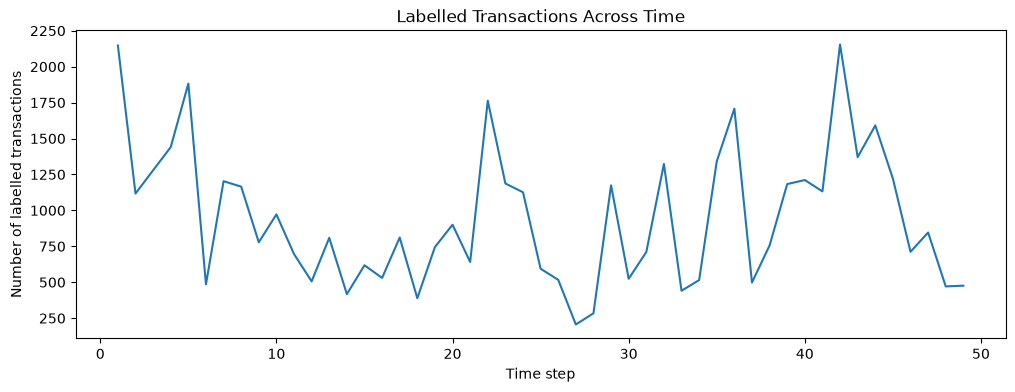

In [15]:
# ============================================================
# CELL 12 — TEMPORAL DISTRIBUTION
# ============================================================

time_counts = (
    labelled[TIME_COL]
    .value_counts()
    .sort_index()
)

print(time_counts)

plt.figure(figsize=(12, 4))

plt.plot(
    time_counts.index,
    time_counts.values
)

plt.xlabel("Time step")
plt.ylabel("Number of labelled transactions")
plt.title("Labelled Transactions Across Time")

plt.show()

In [16]:
# ============================================================
# CELL 13 — TEMPORAL TRAIN / VAL / TEST SPLIT
# ============================================================

times = sorted(
    labelled[TIME_COL].unique()
)

n_times = len(times)

train_end = int(n_times * 0.70)
val_end = int(n_times * 0.85)

train_times = times[:train_end]
val_times = times[train_end:val_end]
test_times = times[val_end:]

print(
    f"Train: {train_times[0]} -> {train_times[-1]}"
)

print(
    f"Validation: {val_times[0]} -> {val_times[-1]}"
)

print(
    f"Test: {test_times[0]} -> {test_times[-1]}"
)

Train: 1 -> 34
Validation: 35 -> 41
Test: 42 -> 49


In [17]:
# ============================================================
# CELL 14 — CREATE DATA SPLITS
# ============================================================

train_df = labelled[
    labelled[TIME_COL].isin(train_times)
].copy()

val_df = labelled[
    labelled[TIME_COL].isin(val_times)
].copy()

test_df = labelled[
    labelled[TIME_COL].isin(test_times)
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain labels:")
print(train_df["y"].value_counts())

print("\nValidation labels:")
print(val_df["y"].value_counts())

print("\nTest labels:")
print(test_df["y"].value_counts())

Train: (29894, 169)
Validation: (7829, 169)
Test: (8841, 169)

Train labels:
y
0    26432
1     3462
Name: count, dtype: int64

Validation labels:
y
0    7154
1     675
Name: count, dtype: int64

Test labels:
y
0    8433
1     408
Name: count, dtype: int64


In [18]:
# ============================================================
# CELL 15 — Prepare temporal edges
# ============================================================

# Attach the time step of each source and target transaction
tx_time = features[[TX_ID_COL, TIME_COL]].copy()

source_time = tx_time.rename(columns={
    TX_ID_COL: EDGE_SOURCE_COL,
    TIME_COL: "source_time"
})

target_time = tx_time.rename(columns={
    TX_ID_COL: EDGE_TARGET_COL,
    TIME_COL: "target_time"
})

edges_temporal = (
    edges
    .merge(source_time, on=EDGE_SOURCE_COL, how="left")
    .merge(target_time, on=EDGE_TARGET_COL, how="left")
)

# Remove edges whose endpoints are not present in the feature table
edges_temporal = edges_temporal.dropna(
    subset=["source_time", "target_time"]
).copy()

# An edge becomes observable when both endpoint transactions
# are available. This prevents using an edge before its later
# endpoint exists.
edges_temporal["edge_time"] = edges_temporal[
    ["source_time", "target_time"]
].max(axis=1)

edges_temporal["source_time"] = edges_temporal["source_time"].astype(int)
edges_temporal["target_time"] = edges_temporal["target_time"].astype(int)
edges_temporal["edge_time"] = edges_temporal["edge_time"].astype(int)

print("Valid temporal edges:", len(edges_temporal))
print(
    "Edge time range:",
    edges_temporal["edge_time"].min(),
    "to",
    edges_temporal["edge_time"].max()
)

display(edges_temporal.head())

Valid temporal edges: 234355
Edge time range: 1 to 49


,txId1,txId2,source_time,target_time,edge_time
0,230425980,5530458,1,1,1
1,232022460,232438397,1,1,1
2,230460314,230459870,1,1,1
3,230333930,230595899,1,1,1
4,232013274,232029206,1,1,1


In [19]:
# ============================================================
# CELL 16 — Build historical adjacency structures
# ============================================================

from collections import defaultdict

# Map transaction IDs to integer indices.
# Integer indices make the graph computations much faster.
all_tx_ids = features[TX_ID_COL].astype(str).unique()

tx_to_idx = {
    tx_id: idx
    for idx, tx_id in enumerate(all_tx_ids)
}

idx_to_tx = np.array(all_tx_ids)

edges_temporal["source_idx"] = (
    edges_temporal[EDGE_SOURCE_COL]
    .map(tx_to_idx)
)

edges_temporal["target_idx"] = (
    edges_temporal[EDGE_TARGET_COL]
    .map(tx_to_idx)
)

edges_temporal = edges_temporal.dropna(
    subset=["source_idx", "target_idx"]
).copy()

edges_temporal["source_idx"] = edges_temporal["source_idx"].astype(int)
edges_temporal["target_idx"] = edges_temporal["target_idx"].astype(int)

# Sort edges chronologically.
edges_temporal = edges_temporal.sort_values(
    "edge_time"
).reset_index(drop=True)

# Nodes belonging to each timestep
nodes_by_time = {
    int(t): features.loc[
        features[TIME_COL] == t, TX_ID_COL
    ].astype(str).tolist()
    for t in sorted(features[TIME_COL].unique())
}

# Edges belonging to each timestep
edges_by_time = {
    int(t): group[
        ["source_idx", "target_idx"]
    ].to_numpy()
    for t, group in edges_temporal.groupby("edge_time")
}

print("Number of nodes:", len(all_tx_ids))
print("Number of temporal edge groups:", len(edges_by_time))
print("First edge times:", list(edges_by_time.keys())[:10])

Number of nodes: 203769
Number of temporal edge groups: 49
First edge times: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [20]:
# ============================================================
# CELL 17 — Leakage-safe temporal graph features
# ============================================================

import networkx as nx

graph_feature_rows = []

# Historical directed graph.
G_hist = nx.DiGraph()

# Add all transactions as nodes.
G_hist.add_nodes_from(range(len(all_tx_ids)))

sorted_times = sorted(features[TIME_COL].unique())

print("Computing causal graph features...")

for t in sorted_times:

    # --------------------------------------------------------
    # 1. Add ONLY edges that become observable at time t
    # --------------------------------------------------------
    if int(t) in edges_by_time:
        new_edges = edges_by_time[int(t)]

        G_hist.add_edges_from(
            (int(src), int(dst))
            for src, dst in new_edges
        )

    # --------------------------------------------------------
    # 2. Compute degree statistics
    # --------------------------------------------------------
    in_degree = dict(G_hist.in_degree())
    out_degree = dict(G_hist.out_degree())
    total_degree = {
        node: in_degree[node] + out_degree[node]
        for node in G_hist.nodes()
    }

    # --------------------------------------------------------
    # 3. PageRank
    # --------------------------------------------------------
    try:
        pagerank = nx.pagerank(
            G_hist,
            alpha=0.85,
            max_iter=100
        )
    except Exception:
        pagerank = {
            node: 0.0
            for node in G_hist.nodes()
        }

    # --------------------------------------------------------
    # 4. HITS hub / authority
    # --------------------------------------------------------
    try:
        hubs, authorities = nx.hits(
            G_hist,
            max_iter=100,
            normalized=True
        )
    except Exception:
        hubs = {
            node: 0.0
            for node in G_hist.nodes()
        }
        authorities = {
            node: 0.0
            for node in G_hist.nodes()
        }

    # --------------------------------------------------------
    # 5. k-core
    #
    # Computed on undirected projection, as in the paper.
    # --------------------------------------------------------
    G_undirected = G_hist.to_undirected()

    try:
        core_number = nx.core_number(G_undirected)
    except Exception:
        core_number = {
            node: 0
            for node in G_hist.nodes()
        }

    # --------------------------------------------------------
    # 6. Neighborhood statistics
    # --------------------------------------------------------
    mean_neighbor_degree = {}
    max_neighbor_degree = {}
    two_hop_reachability = {}

    for node in G_hist.nodes():

        neighbors = set(G_hist.predecessors(node))
        neighbors.update(G_hist.successors(node))

        # Remove self-loop if present
        neighbors.discard(node)

        if len(neighbors) == 0:

            mean_neighbor_degree[node] = 0.0
            max_neighbor_degree[node] = 0.0
            two_hop_reachability[node] = 0

            continue

        neighbor_degrees = [
            total_degree.get(neighbor, 0)
            for neighbor in neighbors
        ]

        mean_neighbor_degree[node] = float(
            np.mean(neighbor_degrees)
        )

        max_neighbor_degree[node] = float(
            np.max(neighbor_degrees)
        )

        # ----------------------------------------------------
        # Two-hop reachability
        # ----------------------------------------------------
        two_hop_nodes = set()

        for neighbor in neighbors:

            second_neighbors = set(
                G_hist.predecessors(neighbor)
            )

            second_neighbors.update(
                G_hist.successors(neighbor)
            )

            two_hop_nodes.update(second_neighbors)

        two_hop_nodes.discard(node)

        # Exclude direct neighbors so this measures
        # additional two-hop context.
        two_hop_nodes.difference_update(neighbors)

        two_hop_reachability[node] = len(two_hop_nodes)

    # --------------------------------------------------------
    # 7. Store features ONLY for transactions occurring at t
    # --------------------------------------------------------
    current_nodes = nodes_by_time[int(t)]

    for tx_id in current_nodes:

        node = tx_to_idx[tx_id]

        graph_feature_rows.append({

            TX_ID_COL: tx_id,
            TIME_COL: int(t),

            "g_in_degree": in_degree.get(node, 0),
            "g_out_degree": out_degree.get(node, 0),
            "g_total_degree": total_degree.get(node, 0),

            "g_pagerank": pagerank.get(node, 0.0),

            "g_hits_hub": hubs.get(node, 0.0),
            "g_hits_authority": authorities.get(node, 0.0),

            "g_kcore": core_number.get(node, 0),

            "g_mean_neighbor_degree":
                mean_neighbor_degree.get(node, 0.0),

            "g_max_neighbor_degree":
                max_neighbor_degree.get(node, 0.0),

            "g_two_hop_reach":
                two_hop_reachability.get(node, 0)

        })

    print(
        f"t={int(t):2d} | "
        f"nodes={len(current_nodes):6d} | "
        f"historical_edges={G_hist.number_of_edges():7d}"
    )

graph_features = pd.DataFrame(graph_feature_rows)

print("\nGraph feature table:", graph_features.shape)

display(graph_features.head())

Computing causal graph features...


t= 1 | nodes=  7880 | historical_edges=   9164


t= 2 | nodes=  4544 | historical_edges=  14405


t= 3 | nodes=  6621 | historical_edges=  22721


t= 4 | nodes=  5693 | historical_edges=  30901


t= 5 | nodes=  6803 | historical_edges=  39524


... (42 outputs left out)

t=48 | nodes=  2954 | historical_edges= 231768


t=49 | nodes=  2454 | historical_edges= 234355



Graph feature table: (203769, 12)


,txId,time_step,g_in_degree,g_out_degree,g_total_degree,g_pagerank,g_hits_hub,g_hits_authority,g_kcore,g_mean_neighbor_degree,g_max_neighbor_degree,g_two_hop_reach
0,230425980,1,1,1,2,0.000009,2.211619e-20,0.000000e+00,1,2.000000,2.0,2
1,5530458,1,1,1,2,0.000009,-2.506678e-19,5.235740e-20,1,1.500000,2.0,1
2,232022460,1,1,2,3,0.000009,8.715013e-05,-2.284453e-19,1,55.000000,161.0,162
3,232438397,1,160,1,161,0.000460,9.214876e-20,2.056046e-04,2,2.757764,28.0,258
4,230460314,1,2,8,10,0.000006,2.390113e-10,1.339972e-12,5,6.600000,11.0,17


In [21]:
# ============================================================
# CELL 18 — Stabilize heavy-tailed graph features
# ============================================================

base_graph_cols = [
    "g_in_degree",
    "g_out_degree",
    "g_total_degree",
    "g_pagerank",
    "g_hits_hub",
    "g_hits_authority",
    "g_kcore",
    "g_mean_neighbor_degree",
    "g_max_neighbor_degree",
    "g_two_hop_reach"
]

# Ensure numeric
graph_features[base_graph_cols] = (
    graph_features[base_graph_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# Log transforms for count / reach / degree style features
log_graph_cols = [
    "g_in_degree",
    "g_out_degree",
    "g_total_degree",
    "g_kcore",
    "g_mean_neighbor_degree",
    "g_max_neighbor_degree",
    "g_two_hop_reach"
]

for col in log_graph_cols:

    graph_features[f"{col}_log"] = np.log1p(
        graph_features[col]
    )

G_COLS = (
    base_graph_cols +
    [f"{col}_log" for col in log_graph_cols]
)

print("Number of graph features:", len(G_COLS))

display(
    graph_features[
        [TX_ID_COL, TIME_COL] + G_COLS
    ].head()
)

Number of graph features: 17


,txId,time_step,g_in_degree,g_out_degree,g_total_degree,g_pagerank,g_hits_hub,g_hits_authority,g_kcore,g_mean_neighbor_degree,g_max_neighbor_degree,g_two_hop_reach,g_in_degree_log,g_out_degree_log,g_total_degree_log,g_kcore_log,g_mean_neighbor_degree_log,g_max_neighbor_degree_log,g_two_hop_reach_log
0,230425980,1,1,1,2,0.000009,2.211619e-20,0.000000e+00,1,2.000000,2.0,2,0.693147,0.693147,1.098612,0.693147,1.098612,1.098612,1.098612
1,5530458,1,1,1,2,0.000009,-2.506678e-19,5.235740e-20,1,1.500000,2.0,1,0.693147,0.693147,1.098612,0.693147,0.916291,1.098612,0.693147
2,232022460,1,1,2,3,0.000009,8.715013e-05,-2.284453e-19,1,55.000000,161.0,162,0.693147,1.098612,1.386294,0.693147,4.025352,5.087596,5.093750
3,232438397,1,160,1,161,0.000460,9.214876e-20,2.056046e-04,2,2.757764,28.0,258,5.081404,0.693147,5.087596,1.098612,1.323824,3.367296,5.556828
4,230460314,1,2,8,10,0.000006,2.390113e-10,1.339972e-12,5,6.600000,11.0,17,1.098612,2.197225,2.397895,1.791759,2.028148,2.484907,2.890372


In [22]:
# ============================================================
# CELL 19 — Merge graph features with labelled transactions
# ============================================================

# Remove any previous graph features from an earlier run
old_graph_cols = [
    c for c in labelled.columns
    if c.startswith("g_") or c == "historical_degree"
]

labelled = labelled.drop(
    columns=old_graph_cols,
    errors="ignore"
)

# Merge on transaction ID + timestep
labelled = labelled.merge(
    graph_features[
        [TX_ID_COL, TIME_COL] + G_COLS
    ],
    on=[TX_ID_COL, TIME_COL],
    how="left"
)

# Missing graph features -> zero
labelled[G_COLS] = (
    labelled[G_COLS]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print("Labelled dataset:", labelled.shape)

print("\nGraph feature columns:")
for col in G_COLS:
    print(" ", col)

display(
    labelled[
        [TX_ID_COL, TIME_COL, "y"] + G_COLS
    ].head()
)

Labelled dataset: (46564, 186)

Graph feature columns:
  g_in_degree
  g_out_degree
  g_total_degree
  g_pagerank
  g_hits_hub
  g_hits_authority
  g_kcore
  g_mean_neighbor_degree
  g_max_neighbor_degree
  g_two_hop_reach
  g_in_degree_log
  g_out_degree_log
  g_total_degree_log
  g_kcore_log
  g_mean_neighbor_degree_log
  g_max_neighbor_degree_log
  g_two_hop_reach_log


,txId,time_step,y,g_in_degree,g_out_degree,g_total_degree,g_pagerank,g_hits_hub,g_hits_authority,g_kcore,g_mean_neighbor_degree,g_max_neighbor_degree,g_two_hop_reach,g_in_degree_log,g_out_degree_log,g_total_degree_log,g_kcore_log,g_mean_neighbor_degree_log,g_max_neighbor_degree_log,g_two_hop_reach_log
0,232438397,1,0,160,1,161,0.000460,9.214876e-20,2.056046e-04,2,2.757764,28.0,258,5.081404,0.693147,5.087596,1.098612,1.323824,3.367296,5.556828
1,232029206,1,0,59,1,60,0.000148,-2.453995e-19,3.168907e-05,2,2.666667,8.0,93,4.094345,0.693147,4.110874,1.098612,1.299283,2.197225,4.543295
2,232344069,1,0,0,2,2,0.000005,3.117574e-19,0.000000e+00,1,1.500000,2.0,1,0.000000,1.098612,1.098612,0.693147,0.916291,1.098612,0.693147
3,27553029,1,0,1,1,2,0.000007,1.044327e-20,3.690240e-19,1,2.500000,3.0,3,0.693147,0.693147,1.098612,0.693147,1.252763,1.386294,1.386294
4,3881097,1,0,1,1,2,0.000005,-4.870500e-20,3.437486e-03,1,145.500000,289.0,289,0.693147,0.693147,1.098612,0.693147,4.987025,5.669881,5.669881


In [23]:
# ============================================================
# CELL 20 — Rebuild temporal splits + inspect graph features
# ============================================================

train_df = labelled[
    labelled[TIME_COL].isin(train_times)
].copy()

val_df = labelled[
    labelled[TIME_COL].isin(val_times)
].copy()

test_df = labelled[
    labelled[TIME_COL].isin(test_times)
].copy()

# Feature groups
T_COLS_FINAL = T_COLS

G_COLS_FINAL = G_COLS

TG_COLS = T_COLS_FINAL + G_COLS_FINAL

print("Feature counts")
print("----------------")
print("T :", len(T_COLS_FINAL))
print("G :", len(G_COLS_FINAL))
print("T+G:", len(TG_COLS))

print("\nSplit sizes")
print("----------------")
print("Train:", train_df.shape)
print("Val  :", val_df.shape)
print("Test :", test_df.shape)

print("\nGraph feature summary")
display(
    labelled[G_COLS_FINAL].describe().T
)

print("\nFirst graph-feature rows")
display(
    labelled[
        [TX_ID_COL, TIME_COL, "y"] + G_COLS_FINAL
    ].head(10)
)

Feature counts
----------------
T : 165
G : 17
T+G: 182

Split sizes
----------------
Train: (29894, 186)
Val  : (7829, 186)
Test : (8841, 186)

Graph feature summary


,count,mean,std,min,25%,50%,75%,max
g_in_degree,46564.0,1.846985,7.134084,0.000000e+00,0.000000e+00,1.000000,1.000000e+00,284.000000
g_out_degree,46564.0,1.142471,3.092219,0.000000e+00,0.000000e+00,1.000000,1.000000e+00,472.000000
g_total_degree,46564.0,2.989455,7.732555,1.000000e+00,1.000000e+00,2.000000,3.000000e+00,473.000000
g_pagerank,46564.0,0.000008,0.000021,1.787764e-06,2.601998e-06,0.000004,7.567241e-06,0.000864
g_hits_hub,46564.0,0.000029,0.002958,-3.244512e-17,-1.662345e-20,0.000000,3.191101e-20,0.479571
g_hits_authority,46564.0,0.000052,0.001318,-6.453001e-17,-2.456240e-20,0.000000,5.183919e-20,0.255039
g_kcore,46564.0,1.384954,0.620933,1.000000e+00,1.000000e+00,1.000000,2.000000e+00,9.000000
g_mean_neighbor_degree,46564.0,17.237532,39.025357,1.090909e+00,2.333333e+00,4.000000,1.400000e+01,473.000000
g_max_neighbor_degree,46564.0,26.106241,58.319647,2.000000e+00,3.000000e+00,5.000000,2.300000e+01,473.000000
g_two_hop_reach,46564.0,29.765291,64.589293,1.000000e+00,2.000000e+00,6.000000,2.600000e+01,700.000000



First graph-feature rows


,txId,time_step,y,g_in_degree,g_out_degree,g_total_degree,g_pagerank,g_hits_hub,g_hits_authority,g_kcore,g_mean_neighbor_degree,g_max_neighbor_degree,g_two_hop_reach,g_in_degree_log,g_out_degree_log,g_total_degree_log,g_kcore_log,g_mean_neighbor_degree_log,g_max_neighbor_degree_log,g_two_hop_reach_log
0,232438397,1,0,160,1,161,0.000460,9.214876e-20,2.056046e-04,2,2.757764,28.0,258,5.081404,0.693147,5.087596,1.098612,1.323824,3.367296,5.556828
1,232029206,1,0,59,1,60,0.000148,-2.453995e-19,3.168907e-05,2,2.666667,8.0,93,4.094345,0.693147,4.110874,1.098612,1.299283,2.197225,4.543295
2,232344069,1,0,0,2,2,0.000005,3.117574e-19,0.000000e+00,1,1.500000,2.0,1,0.000000,1.098612,1.098612,0.693147,0.916291,1.098612,0.693147
3,27553029,1,0,1,1,2,0.000007,1.044327e-20,3.690240e-19,1,2.500000,3.0,3,0.693147,0.693147,1.098612,0.693147,1.252763,1.386294,1.386294
4,3881097,1,0,1,1,2,0.000005,-4.870500e-20,3.437486e-03,1,145.500000,289.0,289,0.693147,0.693147,1.098612,0.693147,4.987025,5.669881,5.669881
5,232457116,1,0,1,1,2,0.000009,7.319372e-20,-1.153032e-19,1,1.500000,2.0,1,0.693147,0.693147,1.098612,0.693147,0.916291,1.098612,0.693147
6,232412405,1,0,1,0,1,0.000009,0.000000e+00,-3.881556e-20,1,2.000000,2.0,1,0.693147,0.000000,0.693147,0.693147,1.098612,1.098612,0.693147
7,232470342,1,0,6,1,7,0.000019,4.841372e-19,3.510536e-03,2,45.857143,289.0,313,1.945910,0.693147,2.079442,1.098612,3.847103,5.669881,5.749393
8,230550393,1,0,21,0,21,0.000071,0.000000e+00,1.118982e-04,2,3.095238,28.0,41,3.091042,0.000000,3.091042,1.098612,1.409825,3.367296,3.737670
9,232051089,1,0,1,2,3,0.000007,-2.579379e-19,2.326416e-19,1,2.000000,3.0,3,0.693147,1.098612,1.386294,0.693147,1.098612,1.386294,1.386294


In [24]:
# ============================================================
# CELL 21 — RECREATE SPLITS WITH G
# ============================================================

train_df = labelled[
    labelled[TIME_COL].isin(train_times)
].copy()

val_df = labelled[
    labelled[TIME_COL].isin(val_times)
].copy()

test_df = labelled[
    labelled[TIME_COL].isin(test_times)
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (29894, 186)
Validation: (7829, 186)
Test: (8841, 186)


In [25]:
# ============================================================
# CELL 22 — T / G / T+G
# ============================================================

T_COLS_FINAL = T_COLS

G_COLS_FINAL = G_COLS

TG_COLS = (
    T_COLS_FINAL +
    G_COLS_FINAL
)

print("T features:", len(T_COLS_FINAL))
print("G features:", len(G_COLS_FINAL))
print("T+G features:", len(TG_COLS))

T features: 165
G features: 17
T+G features: 182


In [26]:
# ============================================================
# CELL 23 — RF TRAINING HELPER
# ============================================================

def train_and_evaluate_rf(
    train_df,
    val_df,
    test_df,
    feature_cols,
    name
):

    print(f"\n{'=' * 60}")
    print(f"MODEL: {name}")
    print(f"Number of features: {len(feature_cols)}")
    print(f"{'=' * 60}")

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=SEED,
        n_jobs=-1,
        class_weight="balanced",
        max_features="sqrt"
    )

    model.fit(
        train_df[feature_cols],
        train_df["y"]
    )

    val_prob = model.predict_proba(
        val_df[feature_cols]
    )[:, 1]

    test_prob = model.predict_proba(
        test_df[feature_cols]
    )[:, 1]

    val_pred = (
        val_prob >= 0.5
    ).astype(int)

    test_pred = (
        test_prob >= 0.5
    ).astype(int)

    results = {
        "Representation": name,
        "Val_AUROC": roc_auc_score(
            val_df["y"],
            val_prob
        ),
        "Test_AUROC": roc_auc_score(
            test_df["y"],
            test_prob
        ),
        "Test_AUPRC": average_precision_score(
            test_df["y"],
            test_prob
        ),
        "Test_F1": f1_score(
            test_df["y"],
            test_pred
        ),
        "Test_Accuracy": accuracy_score(
            test_df["y"],
            test_pred
        )
    }

    print(
        f"Validation AUROC: "
        f"{results['Val_AUROC']:.4f}"
    )

    print(
        f"Test AUROC: "
        f"{results['Test_AUROC']:.4f}"
    )

    print(
        f"Test AUPRC: "
        f"{results['Test_AUPRC']:.4f}"
    )

    print(
        f"Test F1: "
        f"{results['Test_F1']:.4f}"
    )

    return model, val_prob, test_prob, results

In [27]:
# ============================================================
# CELL 24 — T-ONLY MODEL
# ============================================================

rf_T, val_prob_T, test_prob_T, result_T = (
    train_and_evaluate_rf(
        train_df,
        val_df,
        test_df,
        T_COLS_FINAL,
        "T"
    )
)


MODEL: T
Number of features: 165


Validation AUROC: 0.9795
Test AUROC: 0.8694
Test AUPRC: 0.5529
Test F1: 0.5938


In [28]:
# ============================================================
# CELL 25 — G-ONLY MODEL
# ============================================================

rf_G, val_prob_G, test_prob_G, result_G = (
    train_and_evaluate_rf(
        train_df,
        val_df,
        test_df,
        G_COLS_FINAL,
        "G"
    )
)


MODEL: G
Number of features: 17


Validation AUROC: 0.6656
Test AUROC: 0.6218
Test AUPRC: 0.0820
Test F1: 0.1311


In [29]:
# ============================================================
# CELL 26 — HYBRID MODEL
# ============================================================

rf_TG, val_prob_TG, test_prob_TG, result_TG = (
    train_and_evaluate_rf(
        train_df,
        val_df,
        test_df,
        TG_COLS,
        "T+G"
    )
)


MODEL: T+G
Number of features: 182


Validation AUROC: 0.9795
Test AUROC: 0.8608
Test AUPRC: 0.5492
Test F1: 0.5994


In [30]:
# ============================================================
# CELL 27 — BASELINE COMPARISON
# ============================================================

baseline_results = pd.DataFrame([
    result_T,
    result_G,
    result_TG
])

display(
    baseline_results.round(4)
)

,Representation,Val_AUROC,Test_AUROC,Test_AUPRC,Test_F1,Test_Accuracy
0,T,0.9795,0.8694,0.5529,0.5938,0.9701
1,G,0.6656,0.6218,0.0820,0.1311,0.7917
2,T+G,0.9795,0.8608,0.5492,0.5994,0.9708


In [31]:
# ============================================================
# CELL 28 — HYBRID FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "feature": TG_COLS,
    "importance": rf_TG.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

display(
    importance.head(25)
)

,feature,importance
52,feature_53,0.060330
54,feature_55,0.051661
46,feature_47,0.043176
40,feature_41,0.034590
42,feature_43,0.033535
48,feature_49,0.029914
89,feature_90,0.028576
4,feature_5,0.026625
13,feature_14,0.024294
17,feature_18,0.021287


In [32]:
# ============================================================
# CELL 28B — T VS G IMPORTANCE
# ============================================================

importance["group"] = np.where(
    importance["feature"].isin(G_COLS_FINAL),
    "G",
    "T"
)

group_importance = (
    importance
    .groupby("group")["importance"]
    .agg(["sum", "mean", "count"])
)

display(group_importance)


,sum,mean,count
group,,,
G,0.011652,0.000685,17
T,0.988348,0.005990,165


In [33]:
# ============================================================
# CELL 29 — CONTROLLED INTERVENTION
# ============================================================

def intervention_scores(
    model,
    data,
    T_cols,
    G_cols
):
    """
    Compute model predictions for:

    1. Original (T, G)
    2. T intervention:
       T changes while G is fixed
    3. G intervention:
       G changes while T is fixed

    For the initial implementation, the intervention
    values are supplied through counterfactual columns.
    """

    original = data[T_cols + G_cols].copy()

    return model.predict_proba(
        original
    )[:, 1]

In [34]:
# Inspect the raw feature ranges and correlations
print("Number of features:", len(T_COLS))

summary = pd.DataFrame({
    "feature": T_COLS,
    "min": [df[c].min() for c in T_COLS],
    "max": [df[c].max() for c in T_COLS],
    "mean": [df[c].mean() for c in T_COLS],
    "std": [df[c].std() for c in T_COLS],
})

display(summary)

Number of features: 165


,feature,min,max,mean,std
0,feature_1,-0.172983,71.681966,2.008513e-17,1.000002
1,feature_2,-0.210553,73.595052,1.785345e-17,1.000002
2,feature_3,-1.756361,2.683580,3.570689e-17,1.000002
3,feature_4,-0.121970,49.027598,6.862418e-17,1.000002
4,feature_5,-0.063725,260.090707,7.810883e-17,1.000002
...,...,...,...,...,...
160,feature_161,-0.125939,251.849028,-2.231681e-18,1.000002
161,feature_162,-0.131155,238.783493,5.356034e-17,1.000002
162,feature_163,-0.269818,105.734028,1.785345e-17,1.000002
163,feature_164,-1.760926,1.519700,3.570689e-17,1.000002


In [35]:
# ============================================================
# Define T / N / G feature groups
# ============================================================

T_COLS_LOCAL = [f"feature_{i}" for i in range(1, 94)]
N_COLS = [f"feature_{i}" for i in range(94, 166)]
G_COLS_FINAL = G_COLS

print("Local transaction features (T):", len(T_COLS_LOCAL))
print("Neighborhood features (N):", len(N_COLS))
print("Structural graph features (G):", len(G_COLS_FINAL))

print("\nT:", T_COLS_LOCAL[:3], "...", T_COLS_LOCAL[-3:])
print("N:", N_COLS[:3], "...", N_COLS[-3:])
print("G:", G_COLS_FINAL)

Local transaction features (T): 93
Neighborhood features (N): 72
Structural graph features (G): 17

T: ['feature_1', 'feature_2', 'feature_3'] ... ['feature_91', 'feature_92', 'feature_93']
N: ['feature_94', 'feature_95', 'feature_96'] ... ['feature_163', 'feature_164', 'feature_165']
G: ['g_in_degree', 'g_out_degree', 'g_total_degree', 'g_pagerank', 'g_hits_hub', 'g_hits_authority', 'g_kcore', 'g_mean_neighbor_degree', 'g_max_neighbor_degree', 'g_two_hop_reach', 'g_in_degree_log', 'g_out_degree_log', 'g_total_degree_log', 'g_kcore_log', 'g_mean_neighbor_degree_log', 'g_max_neighbor_degree_log', 'g_two_hop_reach_log']


In [36]:
# ============================================================
# Build the 7 T/N/G feature representations
# ============================================================

REPRESENTATIONS = {
    "T": T_COLS_LOCAL,
    "N": N_COLS,
    "G": G_COLS_FINAL,

    "T+N": T_COLS_LOCAL + N_COLS,
    "T+G": T_COLS_LOCAL + G_COLS_FINAL,
    "N+G": N_COLS + G_COLS_FINAL,

    "T+N+G": T_COLS_LOCAL + N_COLS + G_COLS_FINAL
}

for name, cols in REPRESENTATIONS.items():
    print(f"{name:7s}: {len(cols):3d} features")

T      :  93 features
N      :  72 features
G      :  17 features
T+N    : 165 features
T+G    : 110 features
N+G    :  89 features
T+N+G  : 182 features


In [37]:
# ============================================================
# Train RF models for all 7 T/N/G representations
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    accuracy_score
)

representation_results = []
representation_models = {}

for name, cols in REPRESENTATIONS.items():

    print(f"\nTraining representation: {name}")
    print(f"Number of features: {len(cols)}")

    X_train = labelled.loc[
        labelled[TIME_COL].isin(train_times), cols
    ]
    y_train = labelled.loc[
        labelled[TIME_COL].isin(train_times), "y"
    ]

    X_val = labelled.loc[
        labelled[TIME_COL].isin(val_times), cols
    ]
    y_val = labelled.loc[
        labelled[TIME_COL].isin(val_times), "y"
    ]

    X_test = labelled.loc[
        labelled[TIME_COL].isin(test_times), cols
    ]
    y_test = labelled.loc[
        labelled[TIME_COL].isin(test_times), "y"
    ]

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample",
        max_features="sqrt"
    )

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    val_pred = (val_prob >= 0.5).astype(int)
    test_pred = (test_prob >= 0.5).astype(int)

    result = {
        "Representation": name,
        "Features": len(cols),

        "Val_AUROC": roc_auc_score(y_val, val_prob),

        "Test_AUROC": roc_auc_score(y_test, test_prob),
        "Test_AUPRC": average_precision_score(y_test, test_prob),
        "Test_F1": f1_score(y_test, test_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred)
    }

    representation_results.append(result)
    representation_models[name] = model

    print(
        f"Val AUROC:  {result['Val_AUROC']:.4f}\n"
        f"Test AUROC: {result['Test_AUROC']:.4f}\n"
        f"Test AUPRC: {result['Test_AUPRC']:.4f}\n"
        f"Test F1:    {result['Test_F1']:.4f}"
    )

representation_results_df = pd.DataFrame(representation_results)

print("\n" + "=" * 70)
print("FINAL REPRESENTATION COMPARISON")
print("=" * 70)

display(
    representation_results_df.sort_values(
        "Test_AUROC",
        ascending=False
    ).reset_index(drop=True)
)


Training representation: T
Number of features: 93


Val AUROC:  0.9764
Test AUROC: 0.7974
Test AUPRC: 0.5378
Test F1:    0.5857

Training representation: N
Number of features: 72


Val AUROC:  0.9481
Test AUROC: 0.8460
Test AUPRC: 0.4677
Test F1:    0.4829

Training representation: G
Number of features: 17


Val AUROC:  0.6701
Test AUROC: 0.6336
Test AUPRC: 0.0773
Test F1:    0.1384

Training representation: T+N
Number of features: 165


Val AUROC:  0.9792
Test AUROC: 0.8570
Test AUPRC: 0.5459
Test F1:    0.6200

Training representation: T+G
Number of features: 110


Val AUROC:  0.9761
Test AUROC: 0.8147
Test AUPRC: 0.5389
Test F1:    0.5962

Training representation: N+G
Number of features: 89


Val AUROC:  0.9423
Test AUROC: 0.8503
Test AUPRC: 0.4631
Test F1:    0.4812

Training representation: T+N+G
Number of features: 182


Val AUROC:  0.9788
Test AUROC: 0.8595
Test AUPRC: 0.5462
Test F1:    0.6110

FINAL REPRESENTATION COMPARISON


,Representation,Features,Val_AUROC,Test_AUROC,Test_AUPRC,Test_F1,Test_Accuracy
0,T+N+G,182,0.978776,0.859509,0.546168,0.611018,0.973646
1,T+N,165,0.979246,0.856991,0.545905,0.620000,0.974211
2,N+G,89,0.942269,0.850301,0.463110,0.481229,0.965615
3,N,72,0.948058,0.846009,0.467745,0.482877,0.965841
4,T+G,110,0.976095,0.814674,0.538901,0.596215,0.971044
5,T,93,0.976385,0.797400,0.537850,0.585670,0.969913
6,G,17,0.670055,0.633607,0.077255,0.138430,0.811334


In [38]:
# ============================================================
# Record the exact modeling configuration
# ============================================================

print("RF configuration used for representation comparison:")
print("n_estimators =", 300)
print("random_state =", 42)
print("class_weight =", "balanced_subsample")
print("max_features =", "sqrt")
print("n_jobs =", -1)

RF configuration used for representation comparison:
n_estimators = 300
random_state = 42
class_weight = balanced_subsample
max_features = sqrt
n_jobs = -1


In [39]:
# ============================================================
# Intervention setup
# ============================================================

INTERVENTION_REP = "T+N+G"

intervention_model = representation_models[INTERVENTION_REP]
intervention_cols = REPRESENTATIONS[INTERVENTION_REP]

# Test-set nodes only
test_mask = labelled[TIME_COL].isin(test_times)

intervention_data = labelled.loc[
    test_mask,
    [TX_ID_COL, TIME_COL, "y"] + intervention_cols
].copy()

print("Intervention representation:", INTERVENTION_REP)
print("Number of intervention features:", len(intervention_cols))
print("Test nodes available:", len(intervention_data))

print("\nClass distribution:")
print(intervention_data["y"].value_counts())

Intervention representation: T+N+G
Number of intervention features: 182
Test nodes available: 8841

Class distribution:
y
0    8433
1     408
Name: count, dtype: int64


In [40]:
# ============================================================
# Baseline risk scores for intervention analysis
# ============================================================

X_test_full = intervention_data[intervention_cols]

intervention_data["baseline_risk"] = (
    intervention_model.predict_proba(X_test_full)[:, 1]
)

print("Baseline risk scores calculated.")

print("\nRisk score summary:")
print(intervention_data["baseline_risk"].describe())

print("\nHighest-risk test transactions:")
display(
    intervention_data[
        [TX_ID_COL, TIME_COL, "y", "baseline_risk"]
    ]
    .sort_values("baseline_risk", ascending=False)
    .head(10)
)

Baseline risk scores calculated.

Risk score summary:
count    8841.000000
mean        0.055989
std         0.136981
min         0.000000
25%         0.003333
50%         0.013333
75%         0.050000
max         0.950000
Name: baseline_risk, dtype: float64

Highest-risk test transactions:


,txId,time_step,y,baseline_risk
38452,71990017,42,1,0.950000
38152,71989346,42,1,0.950000
38641,71989382,42,1,0.946667
38470,71989375,42,1,0.946667
38532,71988781,42,1,0.946667
39625,71990821,42,1,0.946667
39782,72630995,42,1,0.946667
38073,71988426,42,1,0.946667
39054,71990001,42,1,0.946667
39114,71988422,42,1,0.946667


In [41]:
# ============================================================
# Prepare reference pools for matched interventions
# ============================================================

# We will use the test set as the intervention population.
# References are also restricted to the test set so that
# intervention construction never uses future information.

T_ARRAY = intervention_data[T_COLS_LOCAL].to_numpy()
N_ARRAY = intervention_data[N_COLS].to_numpy()
G_ARRAY = intervention_data[G_COLS_FINAL].to_numpy()

print("T matrix:", T_ARRAY.shape)
print("N matrix:", N_ARRAY.shape)
print("G matrix:", G_ARRAY.shape)

T matrix: (8841, 93)
N matrix: (8841, 72)
G matrix: (8841, 17)


## Intervention Analysis


In [42]:
# ============================================================
# P3.0 — Bridge from the team pipeline to the intervention toolkit
# ============================================================
import time
import networkx as nx
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import QuantileTransformer
from scipy.stats import spearmanr

_needed = ["df", "graph_features", "labelled", "train_times", "val_times", "test_times", "edges_temporal",
           "edges_by_time", "tx_to_idx", "all_tx_ids", "T_COLS_LOCAL", "N_COLS", "G_COLS_FINAL",
           "base_graph_cols", "log_graph_cols", "REPRESENTATIONS", "representation_models"]
_missing = [v for v in _needed if v not in globals()]
assert not _missing, f"Run all team cells above first. Missing: {_missing}"

WORK_DIR = str(Path.cwd())

# ---- experiment settings ----------------------------------------------------
EVAL_SPLIT        = "test"   # nodes we intervene on: the team's test period
K_REF             = 5        # matched donors per node (prediction averaged over them)
ALPHAS            = [0.1, 0.25, 0.5, 0.75, 0.9, 1.0]   # perturbation strengths for method D
N_BOOT            = 1000     # bootstrap resamples for confidence intervals
REALISM_SAMPLE    = 1500     # nodes used for the realism check
GRAPH_EDIT_SAMPLE = 300      # nodes used for method E

# ---- groups and model: taken from the team cells, not redefined --------------
GROUPS     = {"T": T_COLS_LOCAL, "N": N_COLS, "G": G_COLS_FINAL}
MODEL_COLS = REPRESENTATIONS["T+N+G"]
assert MODEL_COLS == T_COLS_LOCAL + N_COLS + G_COLS_FINAL and G_COLS == G_COLS_FINAL
BASE_G, LOG_SRC = base_graph_cols, log_graph_cols
all_tx = all_tx_ids
model = representation_models["T+N+G"]          # the team's trained model (not a retrained copy)

# ---- one table with ALL transactions -----------------------------------------
# Unlabelled transactions are real T/N/G combinations, so they can serve as donors
# (a donor never needs a label). `labelled` above only holds the labelled ones.
full = df.merge(graph_features[[TX_ID_COL, TIME_COL] + G_COLS_FINAL], on=[TX_ID_COL, TIME_COL], how="left")
full[G_COLS_FINAL] = full[G_COLS_FINAL].replace([np.inf, -np.inf], np.nan).fillna(0)
full["y"] = full[LABEL_COL].astype(str).map({"1": 1, "2": 0})          # NaN = unknown
full = full.reset_index(drop=True)

lab       = full[full["y"].notna()]
train_lab = lab[lab[TIME_COL].isin(train_times)]
test_lab  = lab[lab[TIME_COL].isin(test_times)]

def predict_risk(X):
    return model.predict_proba(X[MODEL_COLS])[:, 1]

p_test = predict_risk(test_lab)
auc_here = roc_auc_score(test_lab["y"], p_test)
auc_team = (representation_results_df.set_index("Representation").loc["T+N+G", "Test_AUROC"]
            if "representation_results_df" in globals() else np.nan)
print(f"Transactions: {len(full)} | labelled: {len(lab)} | train {len(train_lab)} | test {len(test_lab)}")
print(f"T+N+G test AUROC recomputed here: {auc_here:.6f} | in the team table above: {auc_team:.6f}")
assert np.isclose(auc_here, auc_team), "P3 is not scoring the same model/test set as the team table"
print("OK: P3 uses the team's own T+N+G model and test set.")

Transactions: 203769 | labelled: 46564 | train 29894 | test 8841
T+N+G test AUROC recomputed here: 0.859509 | in the team table above: 0.859509
OK: P3 uses the team's own T+N+G model and test set.


In [43]:
# ---- evaluation nodes: the SAME nodes are used by every method ----------------
EVAL_TIMES = test_times if EVAL_SPLIT == "test" else val_times
eval_idx  = lab.index[lab[TIME_COL].isin(EVAL_TIMES)].to_numpy()       # rows of `full`
X_eval    = full.loc[eval_idx, MODEL_COLS].reset_index(drop=True)
y_eval    = full.loc[eval_idx, "y"].astype(int).to_numpy()
t_eval    = full.loc[eval_idx, TIME_COL].to_numpy()
base_risk = predict_risk(X_eval)
n_eval = len(eval_idx)
print(f"Evaluation nodes ({EVAL_SPLIT}): {n_eval} | illicit: {y_eval.sum()} | mean risk {base_risk.mean():.4f}")

Evaluation nodes (test): 8841 | illicit: 408 | mean risk 0.0560


## P3.1 Dependency audit — what can and cannot be isolated


In [44]:
# ---- 1a. group summary --------------------------------------------------------
def group_summary(frame):
    rows = []
    for g, cols in GROUPS.items():
        v = frame[cols]
        rows.append({
            "group": g, "n_cols": len(cols),
            "dtype": ", ".join(sorted(set(str(d) for d in v.dtypes))),
            "integer_valued_cols": int(sum(np.allclose(v[c], np.round(v[c])) for c in cols)),
            "median_frac_at_mode": float(np.median([v[c].value_counts(normalize=True).iloc[0] for c in cols])),
            "max_abs_value": float(np.abs(v.to_numpy()).max()),
        })
    return pd.DataFrame(rows)

display(group_summary(lab))

,group,n_cols,dtype,integer_valued_cols,median_frac_at_mode,max_abs_value
0,T,93,float64,0,0.380917,287.891515
1,N,72,float64,0,0.374495,251.849028
2,G,17,"float64, int64",6,0.325488,700.000000


In [45]:
# ---- 1b. G internal constraints --------------------------------------------------
G_INT_COLS = ["g_in_degree", "g_out_degree", "g_total_degree", "g_kcore", "g_two_hop_reach"]
HITS_COLS  = ["g_hits_hub", "g_hits_authority"]

def g_violations(G):
    # Boolean per row: does this G vector break any structural rule?
    G = G[G_COLS]
    bad = np.zeros(len(G), dtype=bool)
    for c in LOG_SRC:
        bad |= ~np.isclose(G[f"{c}_log"].to_numpy(), np.log1p(G[c].to_numpy()), atol=1e-6)
    bad |= ~np.isclose(G["g_total_degree"], G["g_in_degree"] + G["g_out_degree"])
    for c in G_INT_COLS:
        bad |= ~np.isclose(G[c], np.round(G[c]))
    bad |= (G[["g_in_degree", "g_out_degree"]] < 0).any(axis=1).to_numpy()
    bad |= (G["g_kcore"] > G["g_total_degree"] + 1e-9).to_numpy()
    bad |= (G["g_max_neighbor_degree"] + 1e-9 < G["g_mean_neighbor_degree"]).to_numpy()
    return bad

def enforce_g_constraints(G):
    # Repair an arithmetic G vector into one that obeys the structural rules.
    G = G.copy()
    for c in ["g_in_degree", "g_out_degree", "g_kcore", "g_two_hop_reach"]:
        G[c] = np.round(G[c]).clip(lower=0)
    G["g_total_degree"] = G["g_in_degree"] + G["g_out_degree"]
    G["g_kcore"] = np.minimum(G["g_kcore"], G["g_total_degree"])
    G["g_max_neighbor_degree"] = np.maximum(G["g_max_neighbor_degree"], G["g_mean_neighbor_degree"])
    G["g_pagerank"] = G["g_pagerank"].clip(lower=1e-12)
    for c in LOG_SRC:
        G[f"{c}_log"] = np.log1p(G[c])
    return G

print(f"Real rows violating a G rule: {g_violations(lab).mean():.2%}  (should be ~0%)")
for c in HITS_COLS:
    print(f"{c}: share of |value| < 1e-12 (numerical noise) = {(lab[c].abs() < 1e-12).mean():.1%}")

Real rows violating a G rule: 0.00%  (should be ~0%)
g_hits_hub: share of |value| < 1e-12 (numerical noise) = 97.7%
g_hits_authority: share of |value| < 1e-12 (numerical noise) = 96.2%


In [46]:
# ---- 1c. how much of each group is predictable from the others? ----------------
# Ridge regression in a rank-normalised space. R^2 near 0 = group carries its own
# information (easy to isolate). R^2 near 1 = group is largely implied by the others
# (an intervention that keeps the others fixed creates a contradiction).
qt_audit = {g: QuantileTransformer(n_quantiles=min(1000, len(train_lab)), output_distribution="normal",
                                   random_state=SEED).fit(train_lab[c]) for g, c in GROUPS.items()}
rs = np.random.default_rng(SEED)
samp = train_lab.sample(min(15000, len(train_lab)), random_state=SEED)
Zs = {g: qt_audit[g].transform(samp[c]) for g, c in GROUPS.items()}
cut = int(0.7 * len(samp))

def r2_from(pred_groups, target):
    Xp = np.hstack([Zs[g] for g in pred_groups]); Y = Zs[target]
    keep = Y[:cut].std(0) > 1e-6                     # ignore near-constant targets
    m = Ridge(alpha=1.0).fit(Xp[:cut], Y[:cut, keep])
    return float(np.median(r2_score(Y[cut:, keep], m.predict(Xp[cut:]), multioutput="raw_values")))

audit = pd.DataFrame(index=["T", "N", "G"], columns=["from T", "from N", "from G", "from other two"], dtype=float)
for tgt in ["T", "N", "G"]:
    others = [g for g in ["T", "N", "G"] if g != tgt]
    for src in others:
        audit.loc[tgt, f"from {src}"] = r2_from([src], tgt)
    audit.loc[tgt, "from other two"] = r2_from(others, tgt)
print("Median per-column R^2 (rows = group being predicted):")
display(audit.round(3))

Median per-column R^2 (rows = group being predicted):


,from T,from N,from G,from other two
T,NaN,0.318,0.052,0.336
N,0.259,NaN,0.058,0.318
G,0.177,0.209,NaN,0.274


## P3.2 Intervention toolkit


In [47]:
# ---- matching space ----------------------------------------------------------------
MATCH_COLS = {"T": GROUPS["T"], "N": N_COLS,
              "G": [c for c in BASE_G if c not in HITS_COLS]}

universe_idx = full.index[full[TIME_COL].isin(EVAL_TIMES)].to_numpy()   # all txs in eval time steps
U = full.loc[universe_idx].reset_index(drop=True)
u_time = U[TIME_COL].to_numpy()
pos_in_U = pd.Series(np.arange(len(universe_idx)), index=universe_idx)
eval_upos = pos_in_U.loc[eval_idx].to_numpy()                            # eval node -> row of U

class MatchSpace:
    # Rank-normalise each group, then down-weight by sqrt(#cols) so groups count equally.
    def __init__(self, ref_frame, match_cols):
        self.cols = match_cols
        self.qt = {g: QuantileTransformer(n_quantiles=min(1000, len(ref_frame)), output_distribution="normal",
                                          subsample=200_000, random_state=SEED).fit(ref_frame[c])
                   for g, c in match_cols.items()}
        self.w = {g: 1.0 / np.sqrt(len(c)) for g, c in match_cols.items()}
    def block(self, frame, g):
        return self.qt[g].transform(frame[self.cols[g]]) * self.w[g]
    def embed(self, frame, groups):
        return np.hstack([self.block(frame, g) for g in groups])

ms = MatchSpace(U, MATCH_COLS)
ZU = {g: ms.block(U, g) for g in GROUPS}          # embedded universe, per group
UV = {g: U[c].to_numpy() for g, c in GROUPS.items()}   # raw universe values, per group
print("universe (reference donors):", len(U), "transactions over", len(EVAL_TIMES), "time steps")

universe (reference donors): 36824 transactions over 8 time steps


In [48]:
# ---- matching ---------------------------------------------------------------------
_match_cache = {}

def find_matches(match_groups, target_group, k=K_REF, extra=30):
    # For every eval node: k donors from the same time step, closest on `match_groups`.
    # Excludes the node itself and donors whose target group equals the node's own.
    # Returns (positions in U, distances), both shape (n_eval, k); -1 / nan = no donor.
    key = (tuple(match_groups), target_group, k)
    if key in _match_cache:
        return _match_cache[key]
    Zm = np.hstack([ZU[g] for g in match_groups])
    Xt = UV[target_group]
    ref = np.full((n_eval, k), -1, dtype=int)
    dist = np.full((n_eval, k), np.nan)
    for t in EVAL_TIMES:
        pool = np.where(u_time == t)[0]
        rows = np.where(t_eval == t)[0]
        if len(rows) == 0:
            continue
        nn = NearestNeighbors(n_neighbors=min(k + extra, len(pool))).fit(Zm[pool])
        d, j = nn.kneighbors(Zm[eval_upos[rows]])
        cand = pool[j]
        for r, q, cc, dd in zip(rows, eval_upos[rows], cand, d):
            ok = (cc != q) & ~np.all(Xt[cc] == Xt[q], axis=1)
            cc, dd = cc[ok][:k], dd[ok][:k]
            ref[r, :len(cc)], dist[r, :len(cc)] = cc, dd
    _match_cache[key] = (ref, dist)
    return ref, dist

def random_refs(target_group, k=K_REF, seed=SEED):
    # k random donors from the same time step (not self, not identical target group).
    r = np.random.default_rng(seed)
    ref = np.full((n_eval, k), -1, dtype=int)
    Xt = UV[target_group]
    for i in range(n_eval):
        pool = np.where(u_time == t_eval[i])[0]
        cand = r.choice(pool, size=min(len(pool), k + 10), replace=False)
        cand = cand[(cand != eval_upos[i]) & ~np.all(Xt[cand] == Xt[eval_upos[i]], axis=1)][:k]
        ref[i, :len(cand)] = cand
    return ref

In [49]:
# ---- intervention builders: each returns (intervened inputs, owner row) -------
# `owner[i]` says which eval node row i of the intervened table belongs to.

def _with_group(rows, group, values):
    X = X_eval.iloc[rows].reset_index(drop=True).copy()
    X[GROUPS[group]] = values
    return X

def from_refs(group, ref):
    owner, slot = np.nonzero(ref >= 0)
    X = _with_group(owner, group, UV[group][ref[owner, slot]])
    X.attrs["donor_upos"] = ref[owner, slot]          # remembered so the realism check can exclude the donor
    return X, owner

def iv_global(group, stat="median"):
    vals = getattr(train_lab[GROUPS[group]], stat)().to_numpy()
    rows = np.arange(n_eval)
    return _with_group(rows, group, np.tile(vals, (n_eval, 1))), rows

def iv_real_reference(group):
    # One real training transaction whose group vector is closest to the group median.
    Z = ms.block(train_lab, group)
    medoid = train_lab.index[np.argmin(((Z - np.median(Z, axis=0)) ** 2).sum(1))]
    vals = full.loc[medoid, GROUPS[group]].to_numpy(dtype=float)
    rows = np.arange(n_eval)
    return _with_group(rows, group, np.tile(vals, (n_eval, 1))), rows

def iv_random(group):
    return from_refs(group, random_refs(group))

def iv_nn_full(group):
    return from_refs(group, find_matches(["T", "N", "G"], group)[0])

def iv_matched(group):
    others = [g for g in ["T", "N", "G"] if g != group]
    return from_refs(group, find_matches(others, group)[0])

def _perturb(group, target_vals, alpha):
    cur = X_eval[GROUPS[group]].to_numpy()
    X = X_eval.copy()
    X[GROUPS[group]] = cur + alpha * (target_vals - cur)
    if group == "G":
        X[G_COLS] = enforce_g_constraints(X[G_COLS])
    return X, np.arange(n_eval)

def iv_perturb_global(group, alpha):
    med = train_lab[GROUPS[group]].median().to_numpy()
    return _perturb(group, np.tile(med, (n_eval, 1)), alpha)

def iv_perturb_conditional(group, alpha):
    others = [g for g in ["T", "N", "G"] if g != group]
    ref, _ = find_matches(others, group)
    tgt = np.full((n_eval, len(GROUPS[group])), np.nan)
    for i in range(n_eval):
        r = ref[i][ref[i] >= 0]
        tgt[i] = np.median(UV[group][r], axis=0) if len(r) else X_eval.iloc[i][GROUPS[group]].to_numpy()
    return _perturb(group, tgt, alpha)

METHODS = {
    "A-mean":    lambda g: iv_global(g, "mean"),
    "A-median":  lambda g: iv_global(g, "median"),
    "A-realref": iv_real_reference,
    "A-random":  iv_random,
    "B-nn-full": iv_nn_full,
    "C-matched": iv_matched,
}

In [50]:
# ---- measurement: sensitivity, uncertainty, realism ------------------------------
def boot_ci(x, n_boot=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed)
    means = np.concatenate([x[r.integers(0, len(x), (200, len(x)))].mean(1)
                            for _ in range(max(1, n_boot // 200))])
    return np.percentile(means, [2.5, 97.5])

# ---- Realism (full definition and its limits: P3.6 V3) -------------------------------------
# Yardstick: in the matching space (rank-normalised, equal weight per group), the distance from a real
# evaluation node to its nearest OTHER real transaction of the evaluation period.
# Intervened row: distance to its nearest real transaction, excluding (a) the node's own original row and
# (b) the donor row its target group was copied from. Without (b), a copied row looks "near real data"
# simply because it sits next to its own donor (checked in V3).
# realism_ratio = median(intervened distance) / median(real-to-real distance):
#   ~1 = as close to real data as real transactions are to each other; >>1 = off the data manifold.
# It measures CLOSENESS to real data, not VALIDITY of the T/N/G combination (V3 tests that separately).
Z_U_all = np.hstack([ZU[g] for g in ["T", "N", "G"]])
real_nn = NearestNeighbors(n_neighbors=3).fit(Z_U_all)
REAL_ROWS = np.random.default_rng(SEED).choice(n_eval, size=min(REALISM_SAMPLE, n_eval), replace=False)
_d, _j = real_nn.kneighbors(Z_U_all[eval_upos[REAL_ROWS]])
REAL_D = np.where(_j[:, 0] == eval_upos[REAL_ROWS], _d[:, 1], _d[:, 0])
REAL_Q95 = np.quantile(REAL_D, 0.95)

def nearest_real(X_int, owner, exclude_donor=True):
    # Returns (distance to nearest admissible real row, whether the nearest non-self row is the donor).
    first = pd.Series(np.arange(len(owner))).groupby(owner).first()
    sel = first.reindex(REAL_ROWS).dropna().astype(int).to_numpy()
    d, j = real_nn.kneighbors(ms.embed(X_int.iloc[sel], ["T", "N", "G"]))
    own = eval_upos[owner[sel]]
    donor = X_int.attrs.get("donor_upos")
    don = donor[sel] if donor is not None else np.full(len(sel), -2)
    d_noself = np.where(j == own[:, None], np.inf, d)
    nearest_is_donor = j[np.arange(len(sel)), d_noself.argmin(1)] == don
    d_use = np.where(j == don[:, None], np.inf, d_noself) if exclude_donor else d_noself
    return d_use.min(1), nearest_is_donor

def realism(X_int, owner):
    nearest, _ = nearest_real(X_int, owner, exclude_donor=True)
    return float(np.median(nearest) / np.median(REAL_D)), float((nearest > REAL_Q95).mean())

RESULTS, DELTAS = [], {}

def run(method, group, builder, param=None, check_realism=True):
    t0 = time.time()
    X_int, owner = builder()
    p = predict_risk(X_int)
    p_node = pd.Series(p).groupby(owner).mean().reindex(range(n_eval)).to_numpy()
    covered = ~np.isnan(p_node)
    delta = np.where(covered, p_node - base_risk, np.nan)
    a = np.abs(delta[covered])
    lo, hi = boot_ci(a)
    rr, ood = realism(X_int, owner) if check_realism else (np.nan, np.nan)
    rec = {
        "method": method, "group": group, "param": param,
        "S_mean_abs_delta": a.mean(), "ci_lo": lo, "ci_hi": hi,
        "mean_signed_delta": np.nanmean(delta),
        "flip_rate": np.mean((p_node[covered] >= 0.5) != (base_risk[covered] >= 0.5)),
        "S_illicit": np.abs(delta[covered & (y_eval == 1)]).mean(),
        "S_licit": np.abs(delta[covered & (y_eval == 0)]).mean(),
        "realism_ratio": rr, "ood_rate": ood,
        "g_rule_violation_rate": g_violations(X_int).mean(),
        "coverage": covered.mean(), "seconds": time.time() - t0,
    }
    RESULTS.append(rec)
    DELTAS[(method, group, param)] = delta
    print(f"{method:<14} {group} {str(param):>5} | S={rec['S_mean_abs_delta']:.4f} "
          f"[{lo:.4f},{hi:.4f}] | flips={rec['flip_rate']:.3f} | realism={rr:.2f} | {rec['seconds']:.1f}s")
    return rec

## P3.3 Methods A–D on the same evaluation nodes


In [51]:
for method, fn in METHODS.items():
    for group in ["T", "N", "G"]:
        run(method, group, lambda fn=fn, group=group: fn(group))

A-mean         T  None | S=0.0526 [0.0498,0.0555] | flips=0.022 | realism=2.47 | 0.7s


A-mean         N  None | S=0.0338 [0.0320,0.0358] | flips=0.022 | realism=2.12 | 0.7s


A-mean         G  None | S=0.0052 [0.0050,0.0054] | flips=0.001 | realism=1.24 | 0.7s


A-median       T  None | S=0.0497 [0.0470,0.0524] | flips=0.022 | realism=1.72 | 0.7s


A-median       N  None | S=0.0219 [0.0211,0.0229] | flips=0.003 | realism=1.67 | 0.7s


A-median       G  None | S=0.0042 [0.0041,0.0043] | flips=0.000 | realism=1.24 | 0.7s


... (8 outputs left out)

B-nn-full      G  None | S=0.0018 [0.0017,0.0018] | flips=0.000 | realism=1.09 | 1.6s


C-matched      T  None | S=0.0502 [0.0489,0.0516] | flips=0.006 | realism=1.03 | 1.8s


C-matched      N  None | S=0.0125 [0.0120,0.0130] | flips=0.002 | realism=1.08 | 1.5s


C-matched      G  None | S=0.0033 [0.0032,0.0034] | flips=0.000 | realism=1.10 | 1.4s


In [52]:
# ---- method D: dose-response ------------------------------------------------------
for group in ["T", "N", "G"]:
    for alpha in ALPHAS:
        run("D-global", group, lambda g=group, a=alpha: iv_perturb_global(g, a), param=alpha)
        run("D-cond",   group, lambda g=group, a=alpha: iv_perturb_conditional(g, a), param=alpha)

D-global       T   0.1 | S=0.0336 [0.0315,0.0358] | flips=0.022 | realism=1.65 | 0.7s


D-cond         T   0.1 | S=0.0080 [0.0076,0.0085] | flips=0.002 | realism=1.14 | 1.1s


D-global       T  0.25 | S=0.0387 [0.0364,0.0412] | flips=0.022 | realism=1.66 | 0.8s


D-cond         T  0.25 | S=0.0113 [0.0107,0.0119] | flips=0.002 | realism=1.13 | 1.0s


D-global       T   0.5 | S=0.0431 [0.0406,0.0456] | flips=0.022 | realism=1.67 | 0.7s


D-cond         T   0.5 | S=0.0159 [0.0153,0.0167] | flips=0.002 | realism=1.13 | 1.0s


... (26 outputs left out)

D-global       G   0.9 | S=0.0039 [0.0037,0.0040] | flips=0.000 | realism=1.24 | 0.6s


D-cond         G   0.9 | S=0.0032 [0.0031,0.0033] | flips=0.000 | realism=0.97 | 0.9s


D-global       G   1.0 | S=0.0042 [0.0041,0.0043] | flips=0.000 | realism=1.24 | 0.6s


D-cond         G   1.0 | S=0.0034 [0.0033,0.0036] | flips=0.000 | realism=0.95 | 1.0s


In [53]:
# ---- matching quality for the primary method -------------------------------------
# How close are the donors on the groups we claim to hold fixed? Compare with the
# distance to a random donor from the same time step.
rows = []
rand_pos = np.array([np.random.default_rng(SEED + i).choice(np.where(u_time == t_eval[i])[0])
                     for i in range(n_eval)])
for group in ["T", "N", "G"]:
    others = [g for g in ["T", "N", "G"] if g != group]
    ref, dist = find_matches(others, group)
    Zo = np.hstack([ZU[g] for g in others])
    d_rand = np.linalg.norm(Zo[eval_upos] - Zo[rand_pos], axis=1)
    rows.append({"target": group, "matched on": "+".join(others),
                 "median match distance": np.nanmedian(dist[:, 0]),
                 "median random-donor distance": np.median(d_rand),
                 "ratio (lower = better match)": np.nanmedian(dist[:, 0]) / np.median(d_rand),
                 "nodes with K donors": np.mean((ref >= 0).all(1))})
match_quality = pd.DataFrame(rows)
display(match_quality.round(3))

,target,matched on,median match distance,median random-donor distance,ratio (lower = better match),nodes with K donors
0,T,N+G,0.785,4.657,0.168,1.0
1,N,T+G,0.716,4.968,0.144,1.0
2,G,T+N,1.257,4.813,0.261,1.0


## P3.4 Method E — graph-realizable intervention (G only)


In [54]:
def local_graph_feats(Gr, node):
    # Team definitions, recomputed for a single node on graph Gr.
    nb = set(Gr.predecessors(node)); nb.update(Gr.successors(node)); nb.discard(node)
    out = {"g_in_degree": Gr.in_degree(node), "g_out_degree": Gr.out_degree(node)}
    out["g_total_degree"] = out["g_in_degree"] + out["g_out_degree"]
    if nb:
        nd = [Gr.degree(n) for n in nb]
        out["g_mean_neighbor_degree"], out["g_max_neighbor_degree"] = float(np.mean(nd)), float(np.max(nd))
        two = set()
        for n in nb:
            two.update(Gr.predecessors(n)); two.update(Gr.successors(n))
        two.discard(node); two.difference_update(nb)
        out["g_two_hop_reach"] = len(two)
    else:
        out["g_mean_neighbor_degree"] = out["g_max_neighbor_degree"] = 0.0
        out["g_two_hop_reach"] = 0
    return out, len(nb)

rE = np.random.default_rng(SEED)
eligible = np.where(X_eval["g_total_degree"].to_numpy() >= 2)[0]     # keep at least one edge
ill, lic = eligible[y_eval[eligible] == 1], eligible[y_eval[eligible] == 0]
half = GRAPH_EDIT_SAMPLE // 2
sample_rows = np.concatenate([rE.choice(ill, min(half, len(ill)), replace=False),
                              rE.choice(lic, min(GRAPH_EDIT_SAMPLE - min(half, len(ill)), len(lic)), replace=False)])
sample_rows = np.sort(sample_rows)
tx_of = full.loc[eval_idx[sample_rows], TX_ID_COL].to_numpy()

t0 = time.time()
Gr = nx.DiGraph(); Gr.add_nodes_from(range(len(all_tx)))
newG, info = {}, {}
for t in sorted(full[TIME_COL].unique()):
    if t > max(EVAL_TIMES):
        break
    if int(t) in edges_by_time:
        Gr.add_edges_from((int(a), int(b)) for a, b in edges_by_time[int(t)])
    for r, tx in zip(sample_rows, tx_of):
        if t_eval[r] != t:
            continue
        node = tx_to_idx[tx]
        inc = [(p, node) for p in Gr.predecessors(node)] + [(node, s) for s in Gr.successors(node)]
        inc = [e for e in inc if e[0] != e[1]]
        if not inc:
            continue
        _, nb_before = local_graph_feats(Gr, node)
        e = inc[rE.integers(len(inc))]
        Gr.remove_edge(*e)
        feats, _ = local_graph_feats(Gr, node)
        Gr.add_edge(*e)
        newG[r] = feats
        info[r] = 1.0 / max(nb_before, 1)

rowsE = np.array(sorted(newG))
XE = X_eval.iloc[rowsE].reset_index(drop=True).copy()
for c in ["g_in_degree", "g_out_degree", "g_total_degree", "g_mean_neighbor_degree",
          "g_max_neighbor_degree", "g_two_hop_reach"]:
    XE[c] = [newG[r][c] for r in rowsE]
XE[G_COLS] = enforce_g_constraints(XE[G_COLS])
dE = predict_risk(XE) - base_risk[rowsE]
dC = DELTAS[("C-matched", "G", None)][rowsE]

E_summary = pd.DataFrame([{
    "nodes edited": len(rowsE),
    "S_mean_abs_delta (E)": np.abs(dE).mean(),
    "S_mean_abs_delta (C-matched, same nodes)": np.nanmean(np.abs(dC)),
    "flip_rate (E)": np.mean((base_risk[rowsE] + dE >= 0.5) != (base_risk[rowsE] >= 0.5)),
    "N_inputs_invalidated (mean)": np.mean([info[r] for r in rowsE]),
    "G rule violations": g_violations(XE).mean(),
    "seconds": time.time() - t0,
}])
display(E_summary.round(4))

,nodes edited,S_mean_abs_delta (E),"S_mean_abs_delta (C-matched, same nodes)",flip_rate (E),N_inputs_invalidated (mean),G rule violations,seconds
0,300,0.0065,0.0041,0.0,0.4207,0.0,1.0696


## P3.5 Comparison: sensitivity × realism × cost


In [55]:
res = pd.DataFrame(RESULTS)
res_main = res[res["param"].isna()]
table = res_main.pivot(index="method", columns="group", values="S_mean_abs_delta")[["T", "N", "G"]]
real  = res_main.groupby("method")[["realism_ratio", "ood_rate", "g_rule_violation_rate", "seconds"]].mean()
cmp_table = table.add_prefix("S_").join(real).reindex(list(METHODS))
print("Mean |Δ| per group, plus realism/cost averaged over the three groups")
display(cmp_table.round(4))

Mean |Δ| per group, plus realism/cost averaged over the three groups


,S_T,S_N,S_G,realism_ratio,ood_rate,g_rule_violation_rate,seconds
method,,,,,,,
A-mean,0.0526,0.0338,0.0052,1.9419,0.3236,0.3333,0.6665
A-median,0.0497,0.0219,0.0042,1.5406,0.1004,0.0000,0.6811
A-realref,0.0493,0.0235,0.0041,1.5097,0.1016,0.0000,1.1338
A-random,0.0936,0.0260,0.0047,1.6820,0.1511,0.0000,1.9318
B-nn-full,0.0276,0.0104,0.0018,1.0532,0.0471,0.0000,1.7232
C-matched,0.0502,0.0125,0.0033,1.0707,0.0456,0.0000,1.5675


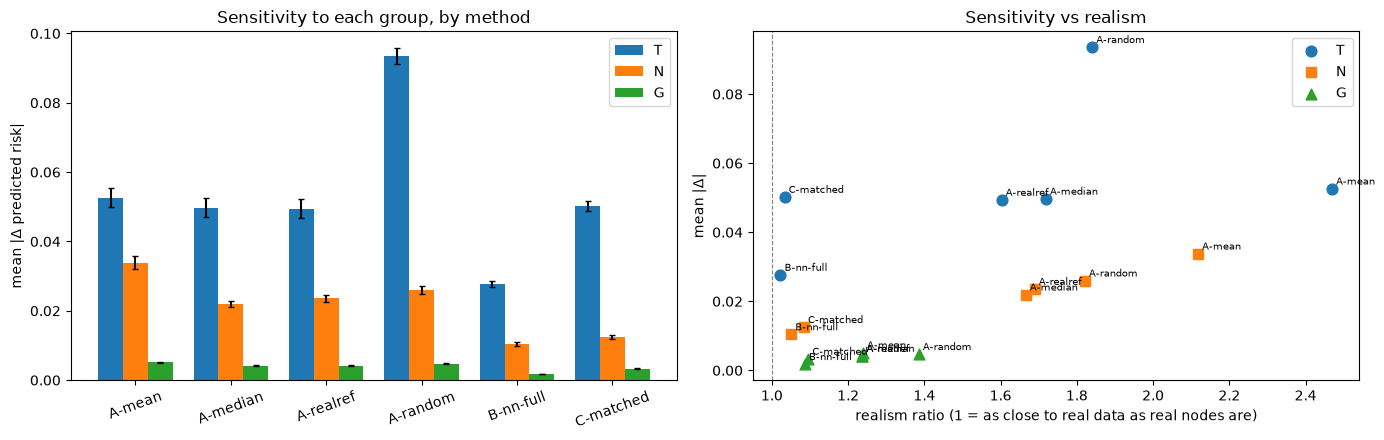

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) sensitivity by method and group, with 95% CI
ax = axes[0]
meths = list(METHODS); w = 0.26
for k, g in enumerate(["T", "N", "G"]):
    sub = res_main[res_main["group"] == g].set_index("method").reindex(meths)
    x = np.arange(len(meths)) + (k - 1) * w
    ax.bar(x, sub["S_mean_abs_delta"], w, label=g,
           yerr=[sub["S_mean_abs_delta"] - sub["ci_lo"], sub["ci_hi"] - sub["S_mean_abs_delta"]], capsize=2)
ax.set_xticks(np.arange(len(meths))); ax.set_xticklabels(meths, rotation=20)
ax.set_ylabel("mean |Δ predicted risk|"); ax.set_title("Sensitivity to each group, by method"); ax.legend()

# (b) is a large Δ just a sign of an unrealistic input?
ax = axes[1]
for g, mk in zip(["T", "N", "G"], ["o", "s", "^"]):
    sub = res_main[res_main["group"] == g]
    ax.scatter(sub["realism_ratio"], sub["S_mean_abs_delta"], marker=mk, s=60, label=g)
    for _, r in sub.iterrows():
        ax.annotate(r["method"], (r["realism_ratio"], r["S_mean_abs_delta"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.axvline(1, color="grey", lw=0.8, ls="--")
ax.set_xlabel("realism ratio (1 = as close to real data as real nodes are)")
ax.set_ylabel("mean |Δ|"); ax.set_title("Sensitivity vs realism"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "p3_methods_comparison.png"), dpi=150); plt.show()

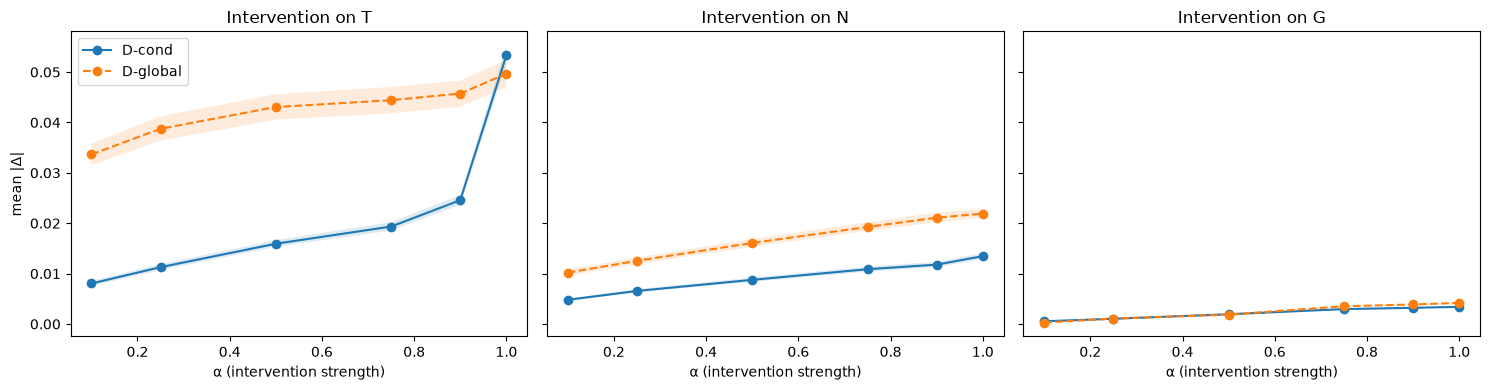

In [57]:
# ---- dose-response for method D ---------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
resD = res[res["method"].str.startswith("D-")]
for ax, g in zip(axes, ["T", "N", "G"]):
    for m, ls in [("D-cond", "-"), ("D-global", "--")]:
        sub = resD[(resD["group"] == g) & (resD["method"] == m)].sort_values("param")
        ax.plot(sub["param"], sub["S_mean_abs_delta"], ls, marker="o", label=m)
        ax.fill_between(sub["param"], sub["ci_lo"], sub["ci_hi"], alpha=0.15)
    ax.set_title(f"Intervention on {g}"); ax.set_xlabel("α (intervention strength)")
axes[0].set_ylabel("mean |Δ|"); axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "p3_dose_response.png"), dpi=150); plt.show()

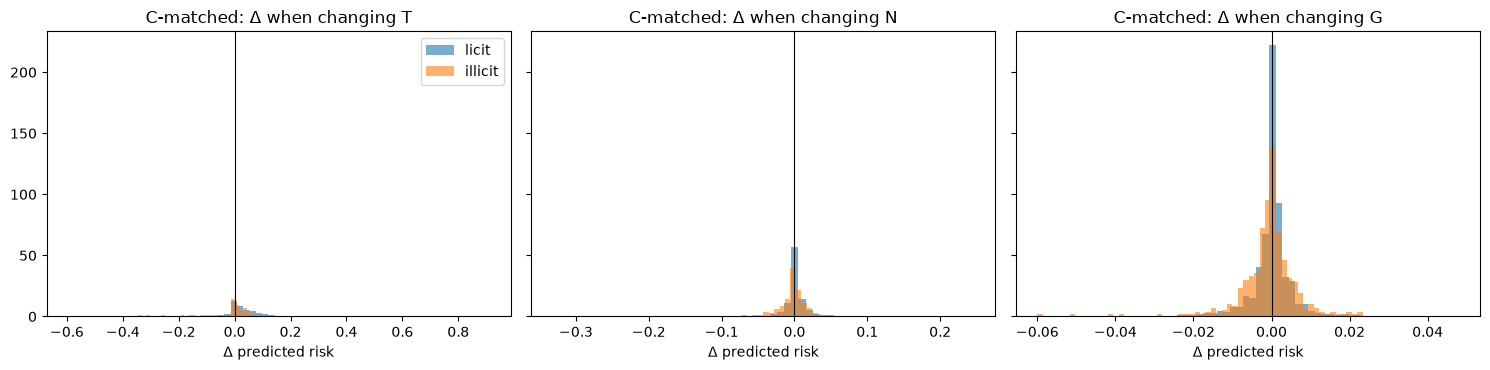

T: mean signed Δ  illicit -0.0395 | licit +0.0339
N: mean signed Δ  illicit -0.0112 | licit +0.0004
G: mean signed Δ  illicit -0.0009 | licit -0.0000


In [58]:
# ---- primary method: distribution of Δ, split by true class ----------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, g in zip(axes, ["T", "N", "G"]):
    d = DELTAS[("C-matched", g, None)]
    for cls, name in [(0, "licit"), (1, "illicit")]:
        v = d[(y_eval == cls) & ~np.isnan(d)]
        ax.hist(v, bins=60, alpha=0.6, density=True, label=name)
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"C-matched: Δ when changing {g}")
    ax.set_xlabel("Δ predicted risk")
axes[0].legend(); plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "p3_primary_delta_distributions.png"), dpi=150); plt.show()

# sign check: illicit nodes should mostly lose risk when their own evidence is replaced
for g in ["T", "N", "G"]:
    d = DELTAS[("C-matched", g, None)]
    print(f"{g}: mean signed Δ  illicit {np.nanmean(d[y_eval==1]):+.4f} | licit {np.nanmean(d[y_eval==0]):+.4f}")

In [59]:
# ---- do the methods agree on the ranking of groups? -----------------------------
rank = res_main.pivot(index="method", columns="group", values="S_mean_abs_delta")[["T", "N", "G"]]
rank["ranking (most → least sensitive)"] = rank.apply(lambda r: " > ".join(r.sort_values(ascending=False).index), axis=1)
d1 = res[(res["method"] == "D-cond") & (res["param"] == 1.0)].set_index("group")["S_mean_abs_delta"]
print("D-cond (α=1):", " > ".join(d1.sort_values(ascending=False).index))
display(rank.reindex(list(METHODS)).round(4))

D-cond (α=1): T > N > G


group,T,N,G,ranking (most → least sensitive)
method,,,,
A-mean,0.0526,0.0338,0.0052,T > N > G
A-median,0.0497,0.0219,0.0042,T > N > G
A-realref,0.0493,0.0235,0.0041,T > N > G
A-random,0.0936,0.0260,0.0047,T > N > G
B-nn-full,0.0276,0.0104,0.0018,T > N > G
C-matched,0.0502,0.0125,0.0033,T > N > G


### P3.5b Does the conclusion depend on the model's random seed?


In [60]:
SEEDS = [42, 0, 1, 2, 3]
c_inputs = {g: iv_matched(g) for g in ["T", "N", "G"]}          # same intervened inputs for every model
seed_rows = []
for s_ in SEEDS:
    m_ = RandomForestClassifier(n_estimators=300, random_state=s_, n_jobs=-1,
                                class_weight="balanced_subsample", max_features="sqrt")
    m_.fit(train_lab[MODEL_COLS], train_lab["y"].astype(int))
    b_ = m_.predict_proba(X_eval[MODEL_COLS])[:, 1]
    rec = {"seed": s_, "test_AUROC": roc_auc_score(test_lab["y"], m_.predict_proba(test_lab[MODEL_COLS])[:, 1])}
    for g, (X_, own_) in c_inputs.items():
        p_ = pd.Series(m_.predict_proba(X_[MODEL_COLS])[:, 1]).groupby(own_).mean().reindex(range(n_eval)).to_numpy()
        rec[f"S_{g}"] = np.nanmean(np.abs(p_ - b_))
    rec["ranking"] = " > ".join(sorted(["T", "N", "G"], key=lambda g: -rec[f"S_{g}"]))
    seed_rows.append(rec)
    print(f"seed {s_:>2} | AUROC {rec['test_AUROC']:.4f} | S_T {rec['S_T']:.4f} S_N {rec['S_N']:.4f} S_G {rec['S_G']:.4f} | {rec['ranking']}")
seed_df = pd.DataFrame(seed_rows)
print(f"\nAUROC range across seeds: {seed_df.test_AUROC.min():.4f} - {seed_df.test_AUROC.max():.4f} (team: 0.8618)")
print("Ranking identical for every seed:", seed_df["ranking"].nunique() == 1)

seed 42 | AUROC 0.8595 | S_T 0.0502 S_N 0.0125 S_G 0.0033 | T > N > G


seed  0 | AUROC 0.8680 | S_T 0.0485 S_N 0.0126 S_G 0.0032 | T > N > G


seed  1 | AUROC 0.8530 | S_T 0.0492 S_N 0.0126 S_G 0.0034 | T > N > G


seed  2 | AUROC 0.8608 | S_T 0.0503 S_N 0.0133 S_G 0.0034 | T > N > G


seed  3 | AUROC 0.8538 | S_T 0.0490 S_N 0.0128 S_G 0.0035 | T > N > G

AUROC range across seeds: 0.8530 - 0.8680 (team: 0.8618)
Ranking identical for every seed: True


## P3.6 Validation pass (V1–V4)


### V1 — Temporal graph construction


In [61]:
# ---- V1a. strict temporal graph vs the team construction -----------------------
def compute_strict_global_feats():
    # Each node is added at its OWN time step; edges are added exactly as in team cell 17.
    ft = full[[TX_ID_COL, TIME_COL]]
    Gs = nx.DiGraph(); out = []
    for t in sorted(ft[TIME_COL].unique()):
        new_tx = ft.loc[ft[TIME_COL] == t, TX_ID_COL].tolist()
        Gs.add_nodes_from(tx_to_idx[x] for x in new_tx)
        if int(t) in edges_by_time:
            Gs.add_edges_from((int(a), int(b)) for a, b in edges_by_time[int(t)])
        pr = nx.pagerank(Gs, alpha=0.85, max_iter=100)
        hub, auth = nx.hits(Gs, max_iter=100, normalized=True)
        core = nx.core_number(Gs.to_undirected())
        for x in new_tx:
            n = tx_to_idx[x]
            out.append((x, pr[n], hub[n], auth[n], core[n], Gs.in_degree(n), Gs.out_degree(n), Gs.number_of_nodes()))
    return pd.DataFrame(out, columns=[TX_ID_COL, "pr_strict", "hub_strict", "auth_strict", "kcore_strict",
                                      "in_strict", "out_strict", "nodes_existing"])

t0 = time.time()
strict = compute_strict_global_feats()
print(f"strict graph features: {time.time()-t0:.0f}s")

chk = full[[TX_ID_COL, TIME_COL] + G_COLS_FINAL].merge(strict, on=TX_ID_COL)
same_step_share = (edges_temporal["source_time"] == edges_temporal["target_time"]).mean()
print(f"Edges whose two endpoints are in the same time step: {same_step_share:.1%}")

v1_feature_diff = pd.DataFrame([
    ("in/out degree", max((chk.g_in_degree - chk.in_strict).abs().max(), (chk.g_out_degree - chk.out_strict).abs().max())),
    ("k-core", (chk.g_kcore - chk.kcore_strict).abs().max()),
    ("HITS hub", (chk.g_hits_hub - chk.hub_strict).abs().max()),
    ("HITS authority", (chk.g_hits_authority - chk.auth_strict).abs().max()),
    ("PageRank", (chk.g_pagerank - chk.pr_strict).abs().max()),
], columns=["feature", "max |team − strict|"])
print("\nMax absolute difference, team construction vs strict:")
display(v1_feature_diff)

chk["ratio"] = chk.g_pagerank / chk.pr_strict
v1_per_step = chk.groupby(TIME_COL).agg(nodes_existing=("nodes_existing", "first"), ratio_median=("ratio", "median"),
                                        ratio_min=("ratio", "min"), ratio_max=("ratio", "max"))
v1_per_step["within_step_rank_corr"] = chk.groupby(TIME_COL).apply(lambda x: spearmanr(x.g_pagerank, x.pr_strict)[0])
print("PageRank, team ÷ strict, selected time steps:")
display(v1_per_step.loc[[t for t in [1, 5, 10, 20, 30, 34, 41, 42, 45, 49] if t in v1_per_step.index]].round(3))
pr_rank_all  = spearmanr(chk.g_pagerank, chk.pr_strict)[0]
pr_rank_test = spearmanr(chk.loc[chk[TIME_COL].isin(test_times), "g_pagerank"], chk.loc[chk[TIME_COL].isin(test_times), "pr_strict"])[0]
print(f"PageRank rank correlation, team vs strict: all steps {pr_rank_all:.3f} | test steps {pr_rank_test:.4f}")

strict graph features: 111s
Edges whose two endpoints are in the same time step: 100.0%

Max absolute difference, team construction vs strict:


,feature,max |team − strict|
0,in/out degree,0.000000e+00
1,k-core,0.000000e+00
2,HITS hub,1.126876e-14
3,HITS authority,1.887379e-14
4,PageRank,7.804416e-03


PageRank, team ÷ strict, selected time steps:


,nodes_existing,ratio_median,ratio_min,ratio_max,within_step_rank_corr
time_step,,,,,
1,7880,0.094,0.001,0.120,0.882
5,31541,0.365,0.010,0.491,0.885
10,58097,0.610,0.123,0.770,0.955
20,90762,0.781,0.094,1.145,0.983
30,123287,0.842,0.309,1.468,0.993
34,136265,0.877,0.107,1.673,0.998
41,166945,0.931,0.826,1.081,0.999
42,174085,0.946,0.861,1.087,1.000
45,189721,0.976,0.933,1.045,1.000


PageRank rank correlation, team vs strict: all steps 0.909 | test steps 0.9993


In [62]:
# ---- V1b. does it matter for the model or for the intervention results? --------
# Swap in strict PageRank, retrain with the 5 seeds of P3.5b, and score the SAME C-matched donor choices.
pr_strict_map = strict.set_index(TX_ID_COL)["pr_strict"]
full_strict = full.copy()
full_strict["g_pagerank"] = full_strict[TX_ID_COL].map(pr_strict_map).to_numpy()
X_eval_strict = full_strict.loc[eval_idx, MODEL_COLS].reset_index(drop=True)
UV_strict = {g: full_strict.loc[universe_idx, c].to_numpy() for g, c in GROUPS.items()}

def c_matched_S(m_, X_base, UVx):
    b_ = m_.predict_proba(X_base[MODEL_COLS])[:, 1]; out = {}
    for g in ["T", "N", "G"]:
        ref, _ = find_matches([o for o in ["T", "N", "G"] if o != g], g)
        own, slot = np.nonzero(ref >= 0)
        X_ = X_base.iloc[own].reset_index(drop=True).copy(); X_[GROUPS[g]] = UVx[g][ref[own, slot]]
        p_ = pd.Series(m_.predict_proba(X_[MODEL_COLS])[:, 1]).groupby(own).mean().reindex(range(n_eval)).to_numpy()
        out[g] = np.nanmean(np.abs(p_ - b_))
    return out

rows = []
for s_ in SEEDS:
    for name, frame, Xb, UVx in [("team graph", full, X_eval, UV), ("strict graph", full_strict, X_eval_strict, UV_strict)]:
        tr_, te_ = frame.loc[train_lab.index], frame.loc[test_lab.index]
        m_ = RandomForestClassifier(n_estimators=300, random_state=s_, n_jobs=-1, class_weight="balanced_subsample",
                                    max_features="sqrt").fit(tr_[MODEL_COLS], tr_["y"].astype(int))
        Sx = c_matched_S(m_, Xb, UVx); imp = dict(zip(MODEL_COLS, m_.feature_importances_))
        rows.append({"graph": name, "seed": s_, "test_AUROC": roc_auc_score(te_["y"], m_.predict_proba(te_[MODEL_COLS])[:, 1]),
                     "pagerank_importance": imp["g_pagerank"], "G_importance": sum(imp[c] for c in G_COLS_FINAL),
                     "S_T": Sx["T"], "S_N": Sx["N"], "S_G": Sx["G"], "ranking": " > ".join(sorted(Sx, key=lambda k: -Sx[k]))})
v1_impact = pd.DataFrame(rows)
display(v1_impact.round(4))
v1_impact_summary = v1_impact.groupby("graph")[["test_AUROC", "pagerank_importance", "G_importance", "S_T", "S_N", "S_G"]].agg(["mean", "std"])
display(v1_impact_summary.round(4))
print("Ranking identical in all 10 models:", v1_impact["ranking"].nunique() == 1)

,graph,seed,test_AUROC,pagerank_importance,G_importance,S_T,S_N,S_G,ranking
0,team graph,42,0.8595,0.0012,0.0117,0.0502,0.0125,0.0033,T > N > G
1,strict graph,42,0.8549,0.0018,0.0123,0.0514,0.0125,0.0031,T > N > G
2,team graph,0,0.8680,0.0011,0.0122,0.0485,0.0126,0.0032,T > N > G
3,strict graph,0,0.8688,0.0021,0.0129,0.0490,0.0124,0.0035,T > N > G
4,team graph,1,0.8530,0.0014,0.0123,0.0492,0.0126,0.0034,T > N > G
5,strict graph,1,0.8469,0.0022,0.0139,0.0491,0.0129,0.0032,T > N > G
6,team graph,2,0.8608,0.0010,0.0123,0.0503,0.0133,0.0034,T > N > G
7,strict graph,2,0.8614,0.0019,0.0129,0.0504,0.0129,0.0033,T > N > G
8,team graph,3,0.8538,0.0012,0.0127,0.0490,0.0128,0.0035,T > N > G
9,strict graph,3,0.8656,0.0023,0.0131,0.0490,0.0124,0.0033,T > N > G


test_AUROC         pagerank_importance         G_importance  \
                   mean     std                mean     std         mean   
graph                                                                      
strict graph     0.8595  0.0088              0.0021  0.0002       0.0130   
team graph       0.8590  0.0061              0.0012  0.0001       0.0122   

                         S_T             S_N             S_G          
                 std    mean     std    mean     std    mean     std  
graph                                                                 
strict graph  0.0006  0.0498  0.0011  0.0126  0.0003  0.0033  0.0001  
team graph    0.0004  0.0494  0.0008  0.0128  0.0003  0.0034  0.0001

Ranking identical in all 10 models: True


### V2 — Which information does the donor pool use?


In [63]:
# ---- V2. historical-only donor pool ------------------------------------------
HIST_MAX_T = min(EVAL_TIMES) - 1
hist_idx = full.index[full[TIME_COL] <= HIST_MAX_T].to_numpy()
H = full.loc[hist_idx].reset_index(drop=True)
ms_h = MatchSpace(H, MATCH_COLS)                       # scaling fitted on historical data only
ZH   = {g: ms_h.block(H, g) for g in GROUPS}
HV   = {g: H[c].to_numpy() for g, c in GROUPS.items()}
ZE_h = {g: ms_h.block(X_eval, g) for g in GROUPS}      # evaluation nodes embedded in the historical space
print(f"historical pool: {len(H)} transactions, steps 1-{HIST_MAX_T} (labelled + unlabelled)")

_hist_cache = {}
def find_matches_hist(match_groups, target_group, k=K_REF, extra=30):
    key = (tuple(match_groups), target_group)
    if key in _hist_cache: return _hist_cache[key]
    d, j = NearestNeighbors(n_neighbors=k + extra).fit(np.hstack([ZH[g] for g in match_groups])).kneighbors(
        np.hstack([ZE_h[g] for g in match_groups]))
    Xt, Xq = HV[target_group], X_eval[GROUPS[target_group]].to_numpy()
    ref = np.full((n_eval, k), -1); dist = np.full((n_eval, k), np.nan)
    for i in range(n_eval):
        ok = ~np.all(Xt[j[i]] == Xq[i], axis=1)
        c_, dd = j[i][ok][:k], d[i][ok][:k]
        ref[i, :len(c_)], dist[i, :len(c_)] = c_, dd
    _hist_cache[key] = (ref, dist); return ref, dist

def iv_matched_hist(group):
    ref, _ = find_matches_hist([g for g in ["T", "N", "G"] if g != group], group)
    owner, slot = np.nonzero(ref >= 0)
    X = X_eval.iloc[owner].reset_index(drop=True).copy(); X[GROUPS[group]] = HV[group][ref[owner, slot]]
    return X, owner

def iv_perturb_conditional_hist(group, alpha):
    ref, _ = find_matches_hist([g for g in ["T", "N", "G"] if g != group], group)
    return _perturb(group, np.stack([np.median(HV[group][r[r >= 0]], axis=0) for r in ref]), alpha)

for g in ["T", "N", "G"]:
    run("C-matched-hist", g, lambda g=g: iv_matched_hist(g))
for g in ["T", "N", "G"]:
    run("D-cond-hist", g, lambda g=g: iv_perturb_conditional_hist(g, 1.0), param=1.0)
res = pd.DataFrame(RESULTS)

rng_ = np.random.default_rng(SEED); rows = []
for g in ["T", "N", "G"]:
    others = [o for o in ["T", "N", "G"] if o != g]
    _, d_same = find_matches(others, g); _, d_hist = find_matches_hist(others, g)
    Zo_u = np.hstack([ZU[o] for o in others]); Zo_h = np.hstack([ZH[o] for o in others]); Zq_h = np.hstack([ZE_h[o] for o in others])
    rnd_u = np.linalg.norm(Zo_u[eval_upos] - Zo_u[rng_.integers(0, len(U), n_eval)], axis=1)
    rnd_h = np.linalg.norm(Zq_h - Zo_h[rng_.integers(0, len(H), n_eval)], axis=1)
    a, b = DELTAS[("C-matched", g, None)], DELTAS[("C-matched-hist", g, None)]; ok = ~np.isnan(a) & ~np.isnan(b)
    rows.append({"group": g,
                 "S same-step": res[(res.method == "C-matched") & (res.group == g)].S_mean_abs_delta.iloc[0],
                 "S historical": res[(res.method == "C-matched-hist") & (res.group == g)].S_mean_abs_delta.iloc[0],
                 "match/random distance, same-step": np.nanmedian(d_same[:, 0]) / np.median(rnd_u),
                 "match/random distance, historical": np.nanmedian(d_hist[:, 0]) / np.median(rnd_h),
                 "per-node Δ correlation": np.corrcoef(a[ok], b[ok])[0, 1]})
v2_pool = pd.DataFrame(rows).set_index("group")
display(v2_pool.round(4))
rank_hist = " > ".join(v2_pool["S historical"].sort_values(ascending=False).index)
print("Ranking with historical donors:", rank_hist)

# Are same-step donors ever the node's own graph neighbours (whose features feed its N)?
nbrs = {}
for a, b in edges_temporal[["source_idx", "target_idx"]].itertuples(index=False):
    nbrs.setdefault(a, set()).add(b); nbrs.setdefault(b, set()).add(a)
u_node = np.array([tx_to_idx[x] for x in U[TX_ID_COL]])
v2_nbr_share = {}
for g in ["T", "N", "G"]:
    ref, _ = find_matches([o for o in ["T", "N", "G"] if o != g], g)
    hits_ = [u_node[r] in nbrs.get(u_node[eval_upos[i]], ()) for i in range(n_eval) for r in ref[i] if r >= 0]
    v2_nbr_share[g] = float(np.mean(hits_))
print("Share of same-step donors that are direct graph neighbours of the node:",
      ", ".join(f"{g} {v:.2%}" for g, v in v2_nbr_share.items()))

historical pool: 166945 transactions, steps 1-41 (labelled + unlabelled)


C-matched-hist T  None | S=0.0610 [0.0592,0.0628] | flips=0.014 | realism=1.02 | 4.7s


C-matched-hist N  None | S=0.0147 [0.0142,0.0153] | flips=0.002 | realism=1.23 | 4.8s


C-matched-hist G  None | S=0.0036 [0.0035,0.0038] | flips=0.000 | realism=1.15 | 6.3s


D-cond-hist    T   1.0 | S=0.0640 [0.0618,0.0660] | flips=0.017 | realism=1.00 | 1.2s


D-cond-hist    N   1.0 | S=0.0173 [0.0165,0.0181] | flips=0.005 | realism=1.17 | 1.1s


D-cond-hist    G   1.0 | S=0.0039 [0.0037,0.0040] | flips=0.000 | realism=1.11 | 0.9s


,S same-step,S historical,"match/random distance, same-step","match/random distance, historical",per-node Δ correlation
group,,,,,
T,0.0502,0.0610,0.1656,0.2240,0.6289
N,0.0125,0.0147,0.1429,0.1203,0.6458
G,0.0033,0.0036,0.2587,0.2644,0.7543


Ranking with historical donors: T > N > G


Share of same-step donors that are direct graph neighbours of the node: T 0.63%, N 1.05%, G 1.19%


### V3 — What the realism metric measures (and what it does not)


In [64]:
# ---- V3a. the donor effect on the realism ratio ---------------------------------
print(f"real-to-real nearest distance: median {np.median(REAL_D):.3f}; exact duplicates {np.mean(REAL_D < 1e-9):.2%}")
rows = []
for m, b in [("C-matched", iv_matched), ("B-nn-full", iv_nn_full), ("A-random", iv_random)]:
    for g in ["T", "N", "G"]:
        X_int, owner = b(g)
        d_self, is_donor = nearest_real(X_int, owner, exclude_donor=False)
        d_both, _ = nearest_real(X_int, owner, exclude_donor=True)
        rows.append({"method": m, "group": g, "nearest real row is the donor": is_donor.mean(),
                     "ratio, self excluded only (old)": np.median(d_self) / np.median(REAL_D),
                     "ratio, self + donor excluded (used)": np.median(d_both) / np.median(REAL_D)})
v3_realism = pd.DataFrame(rows)
display(v3_realism.round(3))

real-to-real nearest distance: median 1.399; exact duplicates 0.00%


,method,group,nearest real row is the donor,"ratio, self excluded only (old)","ratio, self + donor excluded (used)"
0,C-matched,T,0.948,0.544,1.033
1,C-matched,N,0.951,0.527,1.084
2,C-matched,G,0.789,0.864,1.095
3,B-nn-full,T,0.775,0.795,1.022
4,B-nn-full,N,0.831,0.695,1.051
5,B-nn-full,G,0.518,0.952,1.087
6,A-random,T,0.013,1.838,1.840
7,A-random,N,0.007,1.820,1.821
8,A-random,G,0.002,1.385,1.385


In [65]:
# ---- V3b. classifier two-sample test: is the T/N/G COMBINATION detectably synthetic? ----
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
C2ST_N = 3000
c2_nodes = np.random.default_rng(SEED).choice(n_eval, size=min(C2ST_N, n_eval), replace=False)

def c2st_auc(X_int, owner):
    first = pd.Series(np.arange(len(owner))).groupby(owner).first()
    sel = first.reindex(c2_nodes).dropna().astype(int).to_numpy(); nodes = owner[sel]
    X = np.vstack([X_eval.iloc[nodes][MODEL_COLS].to_numpy(), X_int.iloc[sel][MODEL_COLS].to_numpy()])
    y = np.r_[np.zeros(len(sel)), np.ones(len(sel))]; grp = np.r_[nodes, nodes]; p = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(X, y, grp):
        p[te] = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return roc_auc_score(y, p)

t0 = time.time(); rows = []
specs  = [(m, g, (lambda fn=fn, g=g: fn(g))) for m, fn in METHODS.items() for g in "TNG"]
specs += [("C-matched-hist", g, (lambda g=g: iv_matched_hist(g))) for g in "TNG"]
specs += [("D-cond (α=1)",   g, (lambda g=g: iv_perturb_conditional(g, 1.0))) for g in "TNG"]
specs += [("D-cond (α=0.5)", g, (lambda g=g: iv_perturb_conditional(g, 0.5))) for g in "TNG"]
for m, g, b in specs:
    X_int, owner = b(); rows.append({"method": m, "group": g, "c2st_auc": c2st_auc(X_int, owner)})

# floor: the donors' own complete real rows (fully valid transactions from a different set of nodes)
U_rows, H_rows = U[MODEL_COLS].reset_index(drop=True), H[MODEL_COLS].reset_index(drop=True)
def donor_rows(pool_rows, ref):
    owner, slot = np.nonzero(ref >= 0)
    return pool_rows.iloc[ref[owner, slot]].reset_index(drop=True), owner
for g in "TNG":
    others = [o for o in "TNG" if o != g]
    rows.append({"method": "floor: same-step donors' own rows", "group": g, "c2st_auc": c2st_auc(*donor_rows(U_rows, find_matches(others, g)[0]))})
    rows.append({"method": "floor: historical donors' own rows", "group": g, "c2st_auc": c2st_auc(*donor_rows(H_rows, find_matches_hist(others, g)[0]))})
c2st = pd.DataFrame(rows).pivot(index="method", columns="group", values="c2st_auc")[["T", "N", "G"]]
order = list(METHODS) + ["C-matched-hist", "D-cond (α=1)", "D-cond (α=0.5)", "floor: same-step donors' own rows", "floor: historical donors' own rows"]
c2st = c2st.reindex(order)
print(f"C2ST on {len(c2_nodes)} nodes ({time.time()-t0:.0f}s). AUC 0.5 = indistinguishable from the original rows, 1.0 = obviously synthetic.")
display(c2st.round(3))

# what makes historical donors so easy to spot?
Xd, own_ = donor_rows(H_rows, find_matches_hist(["N", "G"], "T")[0])
first_ = pd.Series(np.arange(len(own_))).groupby(own_).first().to_numpy()
A_, B_ = X_eval[MODEL_COLS].to_numpy(), Xd.iloc[first_][MODEL_COLS].to_numpy(); yy = np.r_[np.zeros(len(A_)), np.ones(len(B_))]
period_feats = sorted(((c, max(roc_auc_score(yy, np.r_[A_[:, k], B_[:, k]]), 1 - roc_auc_score(yy, np.r_[A_[:, k], B_[:, k]])))
                       for k, c in enumerate(MODEL_COLS)), key=lambda x: -x[1])[:5]
print("Single features that best separate test-period rows from historical rows:",
      ", ".join(f"{c} (AUC {a:.3f})" for c, a in period_feats))

C2ST on 3000 nodes (257s). AUC 0.5 = indistinguishable from the original rows, 1.0 = obviously synthetic.


group,T,N,G
method,,,
A-mean,1.000,1.000,1.000
A-median,1.000,1.000,1.000
A-realref,1.000,1.000,1.000
A-random,0.986,0.987,0.933
B-nn-full,0.729,0.711,0.588
C-matched,0.786,0.665,0.703
C-matched-hist,0.978,1.000,0.980
D-cond (α=1),0.969,0.986,0.889
D-cond (α=0.5),0.977,0.995,0.924


Single features that best separate test-period rows from historical rows: feature_101 (AUC 0.998), feature_103 (AUC 0.993), feature_100 (AUC 0.989), feature_136 (AUC 0.986), feature_139 (AUC 0.869)


### V4 — Limits of the edge-removal experiment (method E)


In [66]:
# ---- V4. method E with global features fully recomputed ---------------------------
FULL_RECOMP_N = 100
rF = np.random.default_rng(SEED + 7)
ill_e, lic_e = rowsE[y_eval[rowsE] == 1], rowsE[y_eval[rowsE] == 0]
n_ill = min(FULL_RECOMP_N // 2, len(ill_e))
sub = np.sort(np.r_[rF.choice(ill_e, n_ill, replace=False), rF.choice(lic_e, FULL_RECOMP_N - n_ill, replace=False)])

t0 = time.time()
Gt = nx.DiGraph(); Gt.add_nodes_from(range(len(all_tx)))
full_new, changes = {}, []
rE2 = np.random.default_rng(SEED)
for t in sorted(full[TIME_COL].unique()):
    if t > max(EVAL_TIMES): break
    if int(t) in edges_by_time: Gt.add_edges_from((int(a), int(b)) for a, b in edges_by_time[int(t)])
    for r in [r for r in sub if t_eval[r] == t]:
        node = tx_to_idx[full.loc[eval_idx[r], TX_ID_COL]]
        inc = [(p, node) for p in Gt.predecessors(node)] + [(node, s_) for s_ in Gt.successors(node)]
        inc = [e for e in inc if e[0] != e[1]]
        _, nb_before = local_graph_feats(Gt, node)
        e = inc[rE2.integers(len(inc))]
        Gt.remove_edge(*e)
        loc, _ = local_graph_feats(Gt, node)
        pr = nx.pagerank(Gt, alpha=0.85, max_iter=100)
        hub, auth = nx.hits(Gt, max_iter=100, normalized=True)
        core = nx.core_number(Gt.to_undirected())
        Gt.add_edge(*e)
        full_new[r] = {**loc, "g_pagerank": pr[node], "g_hits_hub": hub[node], "g_hits_authority": auth[node], "g_kcore": core[node]}
        old = X_eval.iloc[r]
        changes.append({"pagerank_rel_change": abs(pr[node] - old.g_pagerank) / max(old.g_pagerank, 1e-12),
                        "kcore_change": core[node] - old.g_kcore,
                        "kcore_cap_error": min(old.g_kcore, loc["g_total_degree"]) - core[node],
                        "hits_abs_change": abs(hub[node] - old.g_hits_hub) + abs(auth[node] - old.g_hits_authority),
                        "N_share_invalidated": 1.0 / max(nb_before, 1)})
print(f"{len(full_new)} edits with full recompute: {time.time()-t0:.0f}s")

rows_f = np.array(sorted(full_new))
def score_edit(keep_global):
    X_ = X_eval.iloc[rows_f].reset_index(drop=True).copy()
    cols = ["g_in_degree", "g_out_degree", "g_total_degree", "g_mean_neighbor_degree", "g_max_neighbor_degree", "g_two_hop_reach"]
    if not keep_global: cols += ["g_pagerank", "g_hits_hub", "g_hits_authority", "g_kcore"]
    for c in cols: X_[c] = [full_new[r][c] for r in rows_f]
    X_[G_COLS_FINAL] = enforce_g_constraints(X_[G_COLS_FINAL])
    return predict_risk(X_) - base_risk[rows_f]
d_approx, d_full = score_edit(keep_global=True), score_edit(keep_global=False)
ch = pd.DataFrame(changes)
v4_edge = pd.Series({
    "edits": len(rows_f),
    "mean |Δ|, shortcut (global features kept)": np.abs(d_approx).mean(),
    "mean |Δ|, full recompute": np.abs(d_full).mean(),
    "corr(Δ shortcut, Δ full)": np.corrcoef(d_approx, d_full)[0, 1],
    "max |Δ shortcut − Δ full|": np.abs(d_approx - d_full).max(),
    "PageRank changed by the edit (share)": (ch.pagerank_rel_change > 1e-6).mean(),
    "PageRank relative change, 90th percentile": ch.pagerank_rel_change.quantile(0.9),
    "k-core changed by the edit (share)": (ch.kcore_change != 0).mean(),
    "k-core cap equals exact value (share)": (ch.kcore_cap_error == 0).mean(),
    "HITS max absolute change": ch.hits_abs_change.max(),
    "N: neighbour share invalidated by one edit (mean)": ch.N_share_invalidated.mean(),
})
display(v4_edge.to_frame("value").round(4))

100 edits with full recompute: 421s


,value
edits,100.0000
"mean |Δ|, shortcut (global features kept)",0.0107
"mean |Δ|, full recompute",0.0108
"corr(Δ shortcut, Δ full)",0.9990
max |Δ shortcut − Δ full|,0.0067
PageRank changed by the edit (share),0.9000
"PageRank relative change, 90th percentile",0.5371
k-core changed by the edit (share),0.3500
k-core cap equals exact value (share),0.9500
HITS max absolute change,0.0000


In [67]:
def Sv(m, g, p=None):
    q = res[(res.method == m) & (res.group == g)]
    q = q[q.param.isna()] if p is None else q[q.param == p]
    return q.iloc[0]

imp = v1_impact.groupby("graph")
auc_t, auc_s = imp.test_AUROC.mean()["team graph"], imp.test_AUROC.mean()["strict graph"]
c_fix = v3_realism[v3_realism.method == "C-matched"]
FLOOR_SAME, FLOOR_HIST = "floor: same-step donors' own rows", "floor: historical donors' own rows"
floor_same, hist_floor_min = c2st.loc[FLOOR_SAME], c2st.loc[FLOOR_HIST].min()
validation_summary = pd.DataFrame([
    {"check": "V1 temporal graph",
     "finding": (f"Pre-initialising all {len(all_tx)} nodes leaves degree, k-core, neighbour stats and HITS unchanged "
                 f"(max diff {v1_feature_diff.set_index('feature').loc['HITS hub'].iloc[0]:.0e} or 0). PageRank is rescaled by a "
                 f"time-dependent factor (median {v1_per_step.ratio_median.min():.2f} at step {v1_per_step.ratio_median.idxmin()}) and is "
                 f"under-converged early (within-step rank corr down to {v1_per_step.within_step_rank_corr.min():.2f}); in the test steps "
                 f"it is almost identical (rank corr {pr_rank_test:.4f})."),
     "consequence": (f"Mild look-ahead in PageRank for the training period. Strict PageRank: AUROC {auc_s:.4f} vs {auc_t:.4f} "
                     f"(mean of 5 seeds, within seed noise), S_G {imp.S_G.mean()['strict graph']:.4f} vs {imp.S_G.mean()['team graph']:.4f}, "
                     f"same ranking in all models: {v1_impact['ranking'].nunique() == 1}. Recommend the strict construction "
                     "(add nodes at their own time step) when the team next touches cell 17.")},
    {"check": "V2 donor pool",
     "finding": ("Same-step donors use test-period feature values (never labels) and a scaler fitted on test-period data; "
                 f"{max(v2_nbr_share.values()):.1%} or fewer of them are the node's own graph neighbours. "
                 f"Historical-only donors (steps 1-{HIST_MAX_T}): S_T {v2_pool.loc['T','S historical']:.4f} vs {v2_pool.loc['T','S same-step']:.4f}, "
                 f"ranking {rank_hist}, per-node Δ correlation {v2_pool['per-node Δ correlation'].min():.2f}-{v2_pool['per-node Δ correlation'].max():.2f}."),
     "consequence": ("Conclusion (T > N > G) does not depend on the pool. But historical donors are detectable as coming from another period "
                     f"(C2ST of their own real rows = {hist_floor_min:.2f}+, driven by drifting features such as "
                     f"{period_feats[0][0]}), so same-step stays the candidate; the historical pool is reported as a sensitivity analysis.")},
    {"check": "V3 realism metric",
     "finding": (f"The first version let the donor count as 'nearby real data' (nearest real row was the donor in "
                 f"{c_fix['nearest real row is the donor'].min():.0%}-{c_fix['nearest real row is the donor'].max():.0%} of C-matched cases), "
                 f"giving {c_fix['ratio, self excluded only (old)'].min():.2f}-{c_fix['ratio, self excluded only (old)'].max():.2f}. "
                 f"Fixed (donor excluded): {c_fix['ratio, self + donor excluded (used)'].min():.2f}-{c_fix['ratio, self + donor excluded (used)'].max():.2f}."),
     "consequence": ("Realism now means 'as close to real data as real transactions are to each other', not validity. "
                     f"Validity (C2ST): C-matched {c2st.loc['C-matched'].min():.2f}-{c2st.loc['C-matched'].max():.2f} vs floor "
                     f"{floor_same.min():.2f}-{floor_same.max():.2f}; A-methods {c2st.loc['A-median'].min():.2f}, A-random "
                     f"{c2st.loc['A-random'].min():.2f}+, D-cond {c2st.loc['D-cond (α=1)'].min():.2f}+. C-matched combinations are partly "
                     "detectable, i.e. not guaranteed valid, but far less so than any alternative that does not bias Δ.")},
    {"check": "V4 edge removal",
     "finding": (f"Full recompute of PageRank/HITS/k-core on {int(v4_edge['edits'])} edits: corr(Δ shortcut, Δ full) "
                 f"{v4_edge['corr(Δ shortcut, Δ full)']:.3f}, max difference {v4_edge['max |Δ shortcut − Δ full|']:.4f}; k-core cap exact in "
                 f"{v4_edge['k-core cap equals exact value (share)']:.0%}; HITS unchanged."),
     "consequence": (f"Shortcut 1 is negligible. Shortcut 2 is not fixable: one edit invalidates "
                     f"{v4_edge['N: neighbour share invalidated by one edit (mean)']:.0%} of the neighbour set behind N on average, so "
                     "method E is reported as 'G edited, N stale', not as an isolated G intervention.")},
])
pd.set_option("display.max_colwidth", None)
display(validation_summary)
validation_summary.to_csv(os.path.join(WORK_DIR, "p3_validation_summary.csv"), index=False)

,check,finding,consequence
0,V1 temporal graph,"Pre-initialising all 203769 nodes leaves degree, k-core, neighbour stats and HITS unchanged (max diff 1e-14 or 0). PageRank is rescaled by a time-dependent factor (median 0.09 at step 1) and is under-converged early (within-step rank corr down to 0.88); in the test steps it is almost identical (rank corr 0.9993).","Mild look-ahead in PageRank for the training period. Strict PageRank: AUROC 0.8595 vs 0.8590 (mean of 5 seeds, within seed noise), S_G 0.0033 vs 0.0034, same ranking in all models: True. Recommend the strict construction (add nodes at their own time step) when the team next touches cell 17."
1,V2 donor pool,"Same-step donors use test-period feature values (never labels) and a scaler fitted on test-period data; 1.2% or fewer of them are the node's own graph neighbours. Historical-only donors (steps 1-41): S_T 0.0610 vs 0.0502, ranking T > N > G, per-node Δ correlation 0.63-0.75.","Conclusion (T > N > G) does not depend on the pool. But historical donors are detectable as coming from another period (C2ST of their own real rows = 1.00+, driven by drifting features such as feature_101), so same-step stays the candidate; the historical pool is reported as a sensitivity analysis."
2,V3 realism metric,"The first version let the donor count as 'nearby real data' (nearest real row was the donor in 79%-95% of C-matched cases), giving 0.53-0.86. Fixed (donor excluded): 1.03-1.10.","Realism now means 'as close to real data as real transactions are to each other', not validity. Validity (C2ST): C-matched 0.66-0.79 vs floor 0.48-0.63; A-methods 1.00, A-random 0.93+, D-cond 0.89+. C-matched combinations are partly detectable, i.e. not guaranteed valid, but far less so than any alternative that does not bias Δ."
3,V4 edge removal,"Full recompute of PageRank/HITS/k-core on 100 edits: corr(Δ shortcut, Δ full) 0.999, max difference 0.0067; k-core cap exact in 95%; HITS unchanged.","Shortcut 1 is negligible. Shortcut 2 is not fixable: one edit invalidates 41% of the neighbour set behind N on average, so method E is reported as 'G edited, N stale', not as an isolated G intervention."


## P3.7 Findings, recommendation, limitations


In [68]:
res = pd.DataFrame(RESULTS)
def S(m, g, p=None):
    q = res[(res["method"] == m) & (res["group"] == g)]
    q = q[q["param"].isna()] if p is None else q[q["param"] == p]
    return q.iloc[0]

auc = roc_auc_score(test_lab["y"], p_test)
C = {g: S("C-matched", g) for g in ["T", "N", "G"]}
rank_C = " > ".join(sorted(C, key=lambda g: -C[g].S_mean_abs_delta))
same_rank = rank["ranking (most → least sensitive)"].nunique() == 1
ratio_TG = C["T"].S_mean_abs_delta / C["G"].S_mean_abs_delta
ratio_TN = C["T"].S_mean_abs_delta / C["N"].S_mean_abs_delta
c2 = lambda m: ", ".join(f"{g} {c2st.loc[m, g]:.2f}" for g in "TNG")
FLOOR_SAME = "floor: same-step donors' own rows"

lines = [
 "MODEL",
 f"  The team's T+N+G Random Forest, test AUROC {auc:.4f}; retrained with 5 seeds: {seed_df.test_AUROC.min():.4f}-{seed_df.test_AUROC.max():.4f}.",
 "",
 "1. WHAT CAN BE ISOLATED (P3.1, V4)",
 f"  Each group is partly predictable from the other two (median R^2: T {audit.loc['T','from other two']:.2f}, N {audit.loc['N','from other two']:.2f}, G {audit.loc['G','from other two']:.2f}).",
 "  So no group is fully independent; any 'keep the others fixed' input is only approximately consistent.",
 f"  Removing one real edge invalidates on average {E_summary['N_inputs_invalidated (mean)'].iloc[0]:.0%} of the neighbour set behind N -> G cannot be changed without making N stale.",
 "",
 "2. MAIN RESULT (candidate primary method, C-matched)",
 *[f"  Change {g}: mean |Δrisk| = {C[g].S_mean_abs_delta:.4f}  [95% CI {C[g].ci_lo:.4f}-{C[g].ci_hi:.4f}], decisions flipped {C[g].flip_rate:.1%}" for g in ["T","N","G"]],
 f"  Ranking: {rank_C}. T moves predictions {ratio_TN:.1f}x more than N and {ratio_TG:.0f}x more than G.",
 f"  Same ranking under every method: {same_rank}; every model seed: {seed_df['ranking'].nunique() == 1}; "
 f"strict PageRank (V1): {v1_impact['ranking'].nunique() == 1}; historical donors (V2): {rank_hist == rank_C}.",
 f"  Direction makes sense: replacing T lowers risk for illicit nodes ({np.nanmean(DELTAS[('C-matched','T',None)][y_eval==1]):+.3f}) and raises it for licit nodes ({np.nanmean(DELTAS[('C-matched','T',None)][y_eval==0]):+.3f}).",
 "",
 "3. WHY C-MATCHED IS THE CANDIDATE PRIMARY METHOD",
 "  Closeness to real data (realism ratio; 1 = as close as real transactions are to each other): "
 + ", ".join(f"{m} {v:.2f}" for m, v in real['realism_ratio'].reindex(list(METHODS)).items()),
 "  Share of inputs farther from real data than 95% of real nodes: " + ", ".join(f"{m} {v:.0%}" for m, v in real['ood_rate'].reindex(list(METHODS)).items()),
 f"  Validity of the combination (C2ST AUC, 0.5 = indistinguishable from real rows): C-matched {c2('C-matched')}; "
 f"floor (donors' own real rows) {c2(FLOOR_SAME)}; A-median {c2('A-median')}; A-random {c2('A-random')}; D-cond(α=1) {c2('D-cond (α=1)')}.",
 f"  -> C-matched inputs are not guaranteed valid (above the floor) but are much harder to tell apart from real rows than any alternative except B-nn-full ({c2('B-nn-full')}),",
 f"     and B-nn-full underestimates the effect (S_T {S('B-nn-full','T').S_mean_abs_delta:.4f} vs {C['T'].S_mean_abs_delta:.4f}) because its donor's T is nearly the node's own T.",
 "  Donors are much closer than random on the groups held fixed (match / random distance: " + ", ".join(f"{r['target']} {r['ratio (lower = better match)']:.2f}" for _, r in match_quality.iterrows()) + ").",
 f"  A-mean breaks G's own rules for {S('A-mean','G').g_rule_violation_rate:.0%} of inputs; A-random (real but context-free) gives S_T {S('A-random','T').S_mean_abs_delta:.4f} ({S('A-random','T').S_mean_abs_delta / C['T'].S_mean_abs_delta:.1f}x C-matched).",
 "",
 "4. ROBUSTNESS COMPARISON (method D-cond)",
 *[f"  {m:<8} T: share of the α=1 effect reached at α = " + ", ".join(f"{a}: {S(m,'T',a).S_mean_abs_delta / S(m,'T',1.0).S_mean_abs_delta:.0%}" for a in ALPHAS[:-1]) for m in ["D-global", "D-cond"]],
 f"  D-global jumps immediately (a 10% step already flips {S('D-global','T',0.1).flip_rate:.1%} of decisions): extreme values pulled toward one global median cross many RF thresholds at once.",
 "  D-cond grows steadily, then rises sharply near α=1: many T features sit on a common value and the RF's split thresholds cluster right next to it.",
 f"  D-cond keeps T > N > G at every α: {all(S('D-cond','T',a).S_mean_abs_delta > S('D-cond','N',a).S_mean_abs_delta > S('D-cond','G',a).S_mean_abs_delta for a in ALPHAS)}.",
 f"  Caveat (V3): D-cond inputs are interpolated, so they are easy to tell from real rows (C2ST {c2('D-cond (α=1)')}). It is a dose-response check, not a realistic-input method.",
 "",
 "5. GRAPH-REALIZABLE EDIT (method E, G only)",
 f"  Removing one real edge: mean |Δ| {E_summary['S_mean_abs_delta (E)'].iloc[0]:.4f} vs C-matched G on the same nodes {E_summary['S_mean_abs_delta (C-matched, same nodes)'].iloc[0]:.4f}; flips {E_summary['flip_rate (E)'].iloc[0]:.1%}.",
 f"  Fully recomputing PageRank/HITS/k-core changes almost nothing (corr {v4_edge['corr(Δ shortcut, Δ full)']:.3f}, V4); N staleness remains, so E is 'G edited, N stale'.",
]
print("\n".join(lines))

MODEL
  The team's T+N+G Random Forest, test AUROC 0.8595; retrained with 5 seeds: 0.8530-0.8680.

1. WHAT CAN BE ISOLATED (P3.1, V4)
  Each group is partly predictable from the other two (median R^2: T 0.34, N 0.32, G 0.27).
  So no group is fully independent; any 'keep the others fixed' input is only approximately consistent.
  Removing one real edge invalidates on average 42% of the neighbour set behind N -> G cannot be changed without making N stale.

2. MAIN RESULT (candidate primary method, C-matched)
  Change T: mean |Δrisk| = 0.0502  [95% CI 0.0489-0.0516], decisions flipped 0.6%
  Change N: mean |Δrisk| = 0.0125  [95% CI 0.0120-0.0130], decisions flipped 0.2%
  Change G: mean |Δrisk| = 0.0033  [95% CI 0.0032-0.0034], decisions flipped 0.0%
  Ranking: T > N > G. T moves predictions 4.0x more than N and 15x more than G.
  Same ranking under every method: True; every model seed: True; strict PageRank (V1): True; historical donors (V2): True.
  Direction makes sense: replacing T l

In [69]:
# ---- the comparison table the brief asks for, filled with this run's evidence -----
def verdict(r):
    return "yes" if r < 1.1 else ("borderline" if r < 1.4 else "no (off-manifold)")
concern = {
    "A-mean": "creates combinations no real transaction has; breaks G rules",
    "A-median": "same point for everyone; context ignored",
    "A-realref": "real values, but one donor for everyone; context ignored",
    "A-random": "real values, context ignored; inflates the effect",
    "B-nn-full": "matches on the target too; Δ pushed toward 0 (underestimates)",
    "C-matched": "uses test-period features as donors; combination not guaranteed valid (above C2ST floor)",
    "D-cond": "interpolated inputs are detectably synthetic; use as dose-response check",
    "C-matched-hist": "no test-period donors, but donors are detectably from another period",
    "E-graph-edit": "changes the graph under N; N becomes stale",
}
c2txt = lambda m: " / ".join(f"{c2st.loc[m, g]:.2f}" for g in "TNG")
rows = []
for m in METHODS:
    r = real.loc[m]
    rows.append({"method": m, "close to real data? (realism)": f"{verdict(r.realism_ratio)} ({r.realism_ratio:.2f})",
                 "OOD rate": f"{r.ood_rate:.0%}", "valid combination? C2ST AUC T/N/G": c2txt(m),
                 "keeps other groups fixed?": "yes (numerically)", "cost (s / group)": round(r.seconds, 1), "main concern": concern[m]})
for m, label, c2m in [("D-cond", "D-cond (α=1)", "D-cond (α=1)"), ("C-matched-hist", "C-matched-hist", "C-matched-hist")]:
    q = res[(res.method == m) & ((res.param == 1.0) if m == "D-cond" else res.param.isna())]
    rows.append({"method": label, "close to real data? (realism)": f"{verdict(q.realism_ratio.mean())} ({q.realism_ratio.mean():.2f})",
                 "OOD rate": f"{q.ood_rate.mean():.0%}", "valid combination? C2ST AUC T/N/G": c2txt(c2m),
                 "keeps other groups fixed?": "yes (numerically)", "cost (s / group)": round(q.seconds.mean(), 1), "main concern": concern[m]})
rows.append({"method": "E-graph-edit (G)", "close to real data? (realism)": "yes (a real graph)", "OOD rate": "n/a",
             "valid combination? C2ST AUC T/N/G": "n/a",
             "keeps other groups fixed?": f"NO: invalidates {E_summary['N_inputs_invalidated (mean)'].iloc[0]:.0%} of N's inputs",
             "cost (s / group)": round(E_summary['seconds'].iloc[0], 1), "main concern": concern["E-graph-edit"]})
rows.append({"method": "floor (donors' own real rows)", "close to real data? (realism)": "real", "OOD rate": "-",
             "valid combination? C2ST AUC T/N/G": c2txt("floor: same-step donors' own rows"),
             "keeps other groups fixed?": "-", "cost (s / group)": "-", "main concern": "best achievable C2ST for any donor-based swap"})
comparison = pd.DataFrame(rows).set_index("method")
comparison.to_csv(os.path.join(WORK_DIR, "p3_method_comparison_table.csv"))
display(comparison)

,close to real data? (realism),OOD rate,valid combination? C2ST AUC T/N/G,keeps other groups fixed?,cost (s / group),main concern
method,,,,,,
A-mean,no (off-manifold) (1.94),32%,1.00 / 1.00 / 1.00,yes (numerically),0.7,creates combinations no real transaction has; breaks G rules
A-median,no (off-manifold) (1.54),10%,1.00 / 1.00 / 1.00,yes (numerically),0.7,same point for everyone; context ignored
A-realref,no (off-manifold) (1.51),10%,1.00 / 1.00 / 1.00,yes (numerically),1.1,"real values, but one donor for everyone; context ignored"
A-random,no (off-manifold) (1.68),15%,0.99 / 0.99 / 0.93,yes (numerically),1.9,"real values, context ignored; inflates the effect"
B-nn-full,yes (1.05),5%,0.73 / 0.71 / 0.59,yes (numerically),1.7,matches on the target too; Δ pushed toward 0 (underestimates)
C-matched,yes (1.07),5%,0.79 / 0.66 / 0.70,yes (numerically),1.6,uses test-period features as donors; combination not guaranteed valid (above C2ST floor)
D-cond (α=1),yes (0.90),2%,0.97 / 0.99 / 0.89,yes (numerically),1.0,interpolated inputs are detectably synthetic; use as dose-response check
C-matched-hist,borderline (1.13),7%,0.98 / 1.00 / 0.98,yes (numerically),5.3,"no test-period donors, but donors are detectably from another period"
E-graph-edit (G),yes (a real graph),n/a,n/a,NO: invalidates 42% of N's inputs,1.1,changes the graph under N; N becomes stale


### Recommendation (after the validation pass)


## P3.8 Exports for the team


In [70]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(WORK_DIR, "p3_intervention_results.csv"), index=False)
node_out = pd.DataFrame({
    TX_ID_COL: full.loc[eval_idx, TX_ID_COL].to_numpy(), TIME_COL: t_eval, "y": y_eval, "baseline_risk": base_risk,
    **{f"delta_{g}_matched": DELTAS[("C-matched", g, None)] for g in ["T", "N", "G"]},
    **{f"delta_{g}_matched_hist": DELTAS[("C-matched-hist", g, None)] for g in ["T", "N", "G"]},
})
node_out.to_csv(os.path.join(WORK_DIR, "p3_node_deltas_primary.csv"), index=False)
v1_feature_diff.to_csv(os.path.join(WORK_DIR, "p3_validation_v1_feature_diff.csv"), index=False)
v1_per_step.to_csv(os.path.join(WORK_DIR, "p3_validation_v1_pagerank_per_step.csv"))
v1_impact.to_csv(os.path.join(WORK_DIR, "p3_validation_v1_model_impact.csv"), index=False)
v2_pool.to_csv(os.path.join(WORK_DIR, "p3_validation_v2_donor_pool.csv"))
v3_realism.to_csv(os.path.join(WORK_DIR, "p3_validation_v3_realism.csv"), index=False)
c2st.to_csv(os.path.join(WORK_DIR, "p3_validation_v3_c2st.csv"))
v4_edge.to_frame("value").to_csv(os.path.join(WORK_DIR, "p3_validation_v4_edge_recompute.csv"))
print("Saved to", os.path.abspath(WORK_DIR))
for f in sorted(os.listdir(WORK_DIR)):
    if f.startswith("p3_"): print("  ", f)

Saved to C:\Users\50207\OneDrive\Documents\ChatGPT\AFML
   p3_dose_response.png
   p3_intervention_results.csv
   p3_method_comparison_table.csv
   p3_methods_comparison.png
   p3_node_deltas_primary.csv
   p3_primary_delta_distributions.png
   p3_validation_summary.csv
   p3_validation_v1_feature_diff.csv
   p3_validation_v1_model_impact.csv
   p3_validation_v1_pagerank_per_step.csv
   p3_validation_v2_donor_pool.csv
   p3_validation_v3_c2st.csv
   p3_validation_v3_realism.csv
   p3_validation_v4_edge_recompute.csv


# Final research results — Person 1 + Person 3


# Section 12 — SHAP-based model interpretation

This section adds **feature-level and transaction-level interpretation** to the existing T/N/G ablation and intervention experiments.

- Uses the already-trained `T+N+G` Random Forest (`representation_models["T+N+G"]`).
- Explains a stratified sample of labelled test transactions; it does not retrain the model or use test labels to fit SHAP.
- Reports global feature attribution, aggregated T/N/G attribution, and four representative transaction explanations (TP, TN, FP, FN where present).
- SHAP values explain the fitted model's predictions. They are **not causal effects** and should not be interpreted as real-world causes of fraud.

**Runtime:** Install `shap` if needed. The default explanation sample is capped to keep computation manageable; increase `SHAP_PER_CLASS` only if runtime permits.

In [71]:
import shap
print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


In [72]:
# ---- 12.1 Select the exact model and labelled test rows -----------------------
SHAP_MODEL_NAME = "T+N+G"
SHAP_PER_CLASS = 250       # up to 500 randomly sampled test rows, stratified by class
SHAP_BACKGROUND_N = 100    # background rows used by interventional TreeSHAP
SHAP_TOP_FEATURES = 20
SHAP_SEED = 42

assert SHAP_MODEL_NAME in representation_models
shap_model = representation_models[SHAP_MODEL_NAME]
shap_cols = REPRESENTATIONS[SHAP_MODEL_NAME]
shap_groups = {
    "T": list(T_COLS_LOCAL),
    "N": list(N_COLS),
    "G": list(G_COLS_FINAL),
}
assert set(shap_cols) == set(shap_groups["T"] + shap_groups["N"] + shap_groups["G"])

# Use the same test split and feature columns as the ablation/intervention model.
_shap_test = labelled.loc[labelled[TIME_COL].isin(test_times)].copy()
_shap_test = _shap_test.dropna(subset=["y"])
X_shap_test = _shap_test[shap_cols].astype(float)
y_shap_test = _shap_test["y"].astype(int).to_numpy()
p_shap_test = shap_model.predict_proba(X_shap_test)[:, 1]
pred_shap_test = (p_shap_test >= 0.5).astype(int)  # same fixed threshold used in the T/N/G comparison cell

# Stratified sample: include both labelled classes, then force inclusion of one representative
# TP, TN, FP and FN when those categories exist.
rng_shap = np.random.default_rng(SHAP_SEED)
selected_pos = []
for cls in [0, 1]:
    cls_pos = np.flatnonzero(y_shap_test == cls)
    take = min(SHAP_PER_CLASS, len(cls_pos))
    if take:
        selected_pos.extend(rng_shap.choice(cls_pos, size=take, replace=False).tolist())

case_positions = {}
case_masks = {
    "TP": (y_shap_test == 1) & (pred_shap_test == 1),
    "TN": (y_shap_test == 0) & (pred_shap_test == 0),
    "FP": (y_shap_test == 0) & (pred_shap_test == 1),
    "FN": (y_shap_test == 1) & (pred_shap_test == 0),
}
for case, mask in case_masks.items():
    candidates = np.flatnonzero(mask)
    if len(candidates):
        # Choose a confident representative within its outcome category.
        if case in ["TP", "FP"]:
            pos = int(candidates[np.argmax(p_shap_test[candidates])])
        else:
            pos = int(candidates[np.argmin(p_shap_test[candidates])])
        case_positions[case] = pos
        selected_pos.append(pos)

shap_positions = np.array(sorted(set(selected_pos)), dtype=int)
X_shap = X_shap_test.iloc[shap_positions].reset_index(drop=True)
y_shap = y_shap_test[shap_positions]
p_shap = p_shap_test[shap_positions]
print("Model:", SHAP_MODEL_NAME)
print("Test transactions:", len(X_shap_test))
print("Transactions explained:", len(X_shap))
print("Outcome cases available:", list(case_positions))

Model: T+N+G
Test transactions: 8841
Transactions explained: 503
Outcome cases available: ['TP', 'TN', 'FP', 'FN']


In [73]:
# ---- 12.2 Compute TreeSHAP values for illicit-class probability ---------------
# The background is sampled from TRAINING rows only. Test labels are not used by the explainer.
X_shap_train = labelled.loc[labelled[TIME_COL].isin(train_times), shap_cols].astype(float)
background_n = min(SHAP_BACKGROUND_N, len(X_shap_train))
background = X_shap_train.sample(n=background_n, random_state=SHAP_SEED)

explainer = shap.TreeExplainer(
    shap_model,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)
shap_explanation = explainer(X_shap, check_additivity=False)
shap_values_raw = np.asarray(shap_explanation.values)
base_values_raw = np.asarray(shap_explanation.base_values)

# SHAP versions differ: some return (rows, features, classes), others class-specific arrays.
if shap_values_raw.ndim == 3:
    shap_values = shap_values_raw[:, :, 1]
else:
    shap_values = shap_values_raw
if base_values_raw.ndim == 2:
    shap_base_values = base_values_raw[:, 1]
else:
    shap_base_values = base_values_raw.reshape(-1)

assert shap_values.shape == X_shap.shape, (shap_values.shape, X_shap.shape)
assert len(shap_base_values) == len(X_shap)
print("SHAP matrix:", shap_values.shape)
print("Mean absolute additivity residual:", float(np.mean(np.abs(shap_base_values + shap_values.sum(axis=1) - p_shap))))

  8%|==                  | 85/1006 [00:11<01:59]       

  9%|==                  | 95/1006 [00:12<01:55]       

 10%|==                  | 102/1006 [00:13<01:55]       

 11%|==                  | 110/1006 [00:14<01:54]       

 12%|==                  | 118/1006 [00:15<01:52]       

 13%|===                 | 127/1006 [00:16<01:50]       

... (87 outputs left out)

 97%|=================== | 975/1006 [01:44<00:03]       

 98%|===================| 985/1006 [01:45<00:02]       

 99%|===================| 997/1006 [01:46<00:00]       

SHAP matrix: (503, 182)
Mean absolute additivity residual: 0.00015128635670602338


,feature,group,mean_abs_shap
0,feature_53,T,0.024035
1,feature_55,T,0.022457
2,feature_52,T,0.009721
3,feature_59,T,0.009608
4,feature_90,T,0.009385
5,feature_47,T,0.009310
6,feature_5,T,0.009280
7,feature_76,T,0.008867
8,feature_14,T,0.008466
9,feature_65,T,0.008122


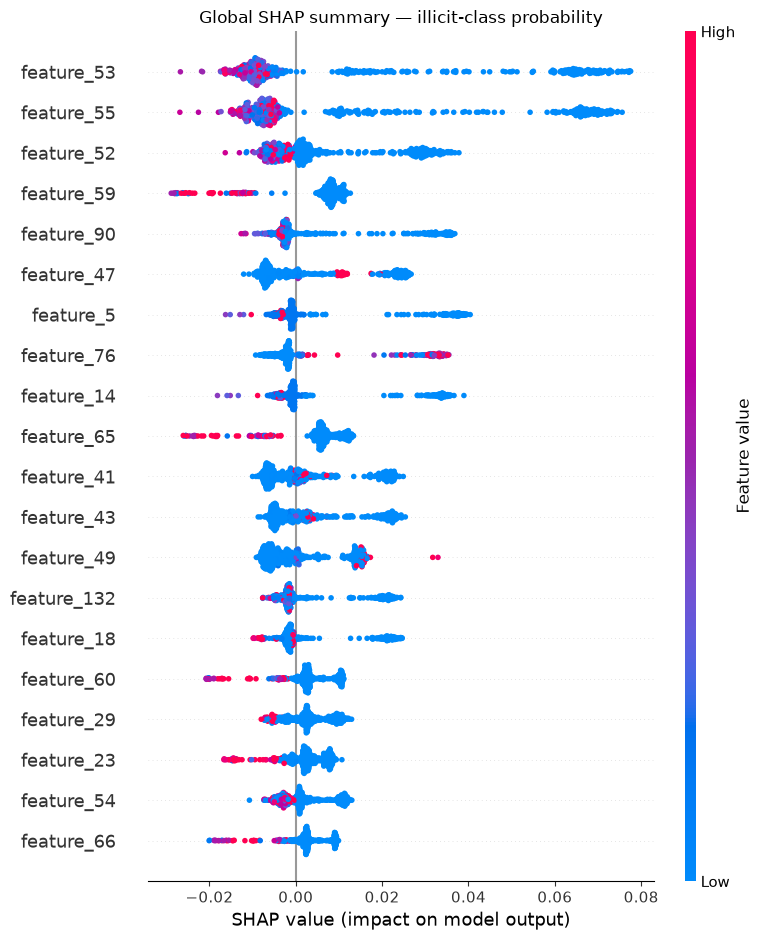

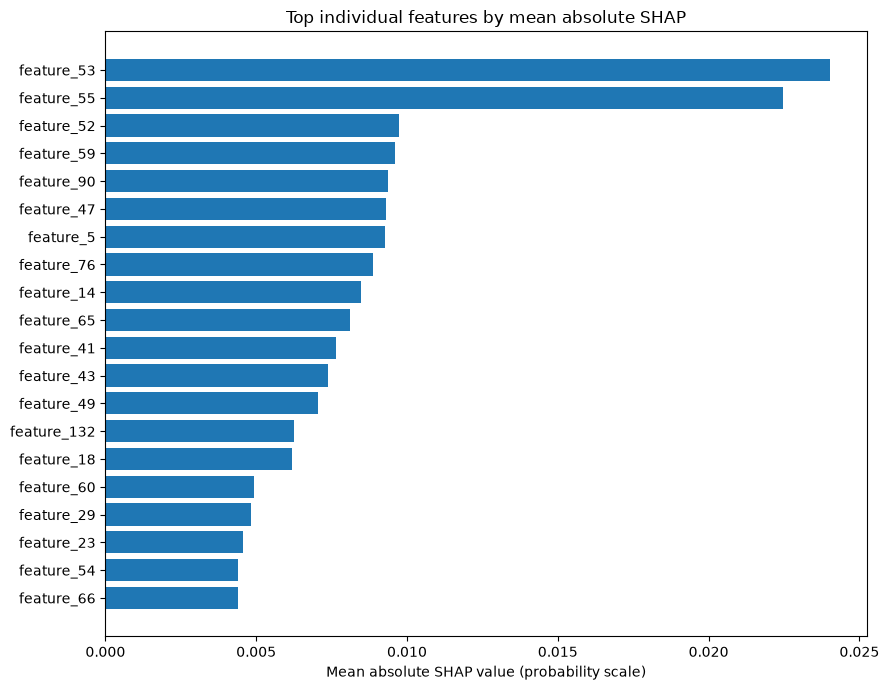

In [74]:
# ---- 12.3 Global feature-level interpretation --------------------------------
mean_abs_shap = np.abs(shap_values).mean(axis=0)
feature_to_group = {c: g for g, cols in shap_groups.items() for c in cols}
feature_shap_df = pd.DataFrame({
    "feature": shap_cols,
    "group": [feature_to_group[c] for c in shap_cols],
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

display(feature_shap_df.head(25))

plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=shap_cols,
    max_display=SHAP_TOP_FEATURES,
    show=False
)
plt.title("Global SHAP summary — illicit-class probability")
plt.tight_layout()
plt.savefig("shap_global_summary.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 7))
top_features = feature_shap_df.head(SHAP_TOP_FEATURES).sort_values("mean_abs_shap")
plt.barh(top_features["feature"], top_features["mean_abs_shap"])
plt.xlabel("Mean absolute SHAP value (probability scale)")
plt.title("Top individual features by mean absolute SHAP")
plt.tight_layout()
plt.savefig("shap_top_features.png", dpi=200, bbox_inches="tight")
plt.show()

,group,mean_abs_group_shap,mean_signed_group_shap,share_of_group_abs_attribution_pct
0,T,0.201899,0.124286,81.169235
1,N,0.044921,0.020872,18.059389
2,G,0.001919,-0.000125,0.771376


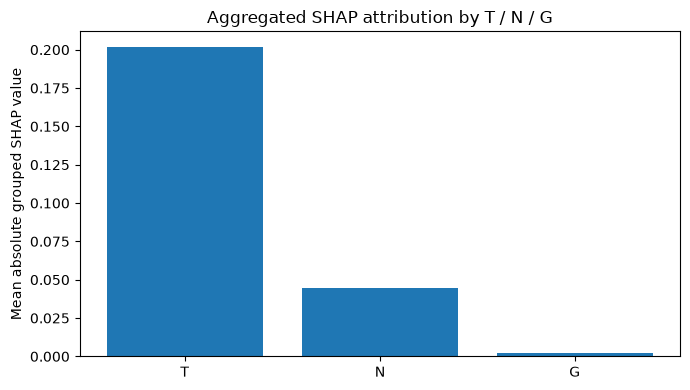

Sum of per-feature mean absolute SHAP values by group (secondary summary):


,group,mean_abs_shap
2,T,0.273685
1,N,0.075267
0,G,0.003973


In [75]:
# ---- 12.4 Aggregate signed feature attributions into T / N / G -----------------
# Sum signed SHAP values within each group for each transaction, then summarize
# the absolute group contribution. This preserves cancellation within a group.
group_shap_rows = {}
for group, cols in shap_groups.items():
    col_pos = [shap_cols.index(c) for c in cols]
    group_shap_rows[group] = shap_values[:, col_pos].sum(axis=1)

group_shap_matrix = pd.DataFrame(group_shap_rows)
group_shap_summary = pd.DataFrame({
    "group": list(shap_groups),
    "mean_abs_group_shap": [np.abs(group_shap_matrix[g]).mean() for g in shap_groups],
    "mean_signed_group_shap": [group_shap_matrix[g].mean() for g in shap_groups],
})
group_shap_summary["share_of_group_abs_attribution_pct"] = (
    100 * group_shap_summary["mean_abs_group_shap"] /
    group_shap_summary["mean_abs_group_shap"].sum()
)
group_shap_summary = group_shap_summary.sort_values("mean_abs_group_shap", ascending=False)
display(group_shap_summary)

plt.figure(figsize=(7, 4))
plt.bar(group_shap_summary["group"], group_shap_summary["mean_abs_group_shap"])
plt.ylabel("Mean absolute grouped SHAP value")
plt.title("Aggregated SHAP attribution by T / N / G")
plt.tight_layout()
plt.savefig("shap_group_attribution.png", dpi=200, bbox_inches="tight")
plt.show()

# Feature-level absolute SHAP totals are also shown as a secondary descriptive view.
feature_group_summary = feature_shap_df.groupby("group", as_index=False)["mean_abs_shap"].sum()
feature_group_summary = feature_group_summary.sort_values("mean_abs_shap", ascending=False)
print("Sum of per-feature mean absolute SHAP values by group (secondary summary):")
display(feature_group_summary)

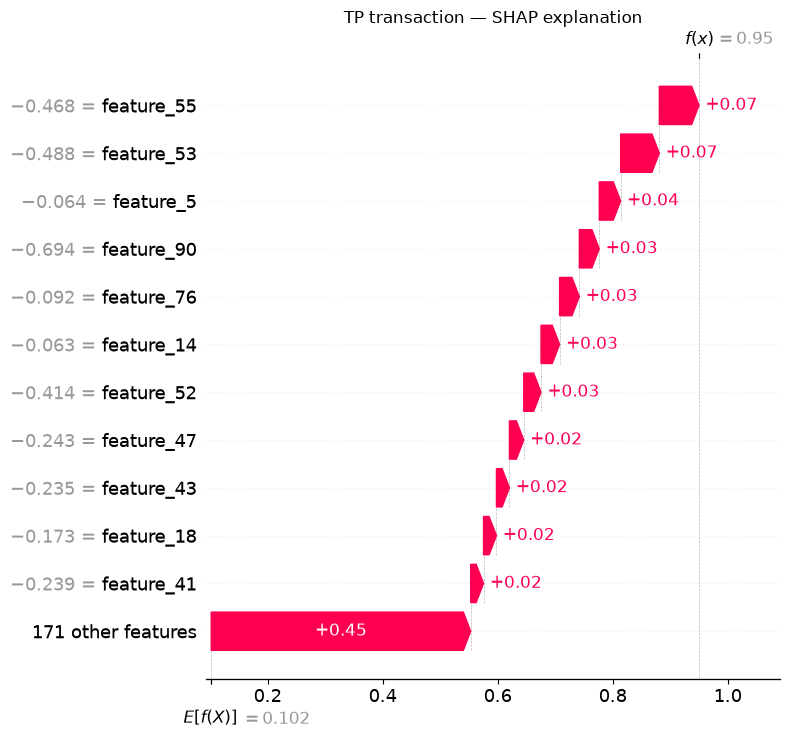

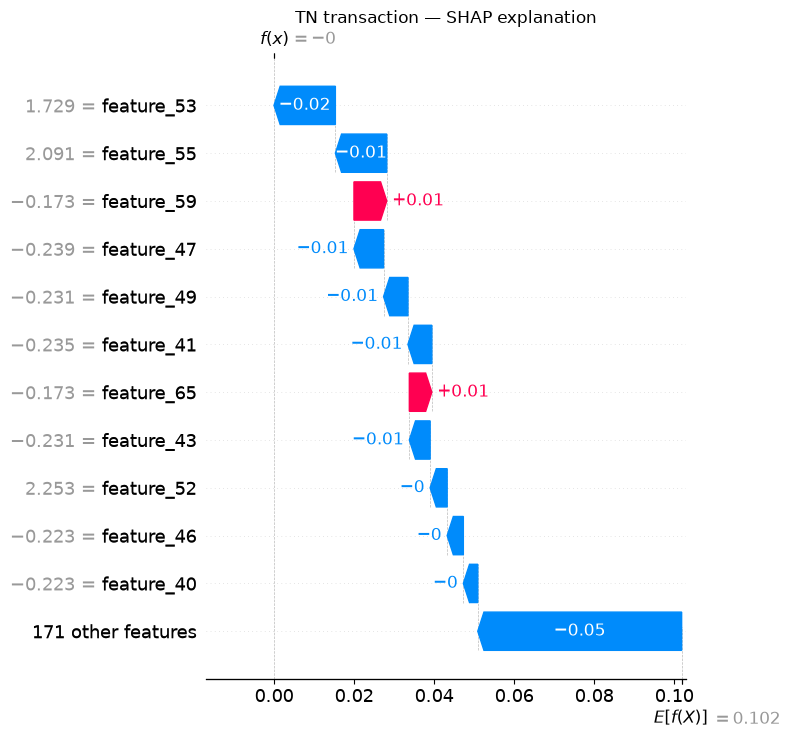

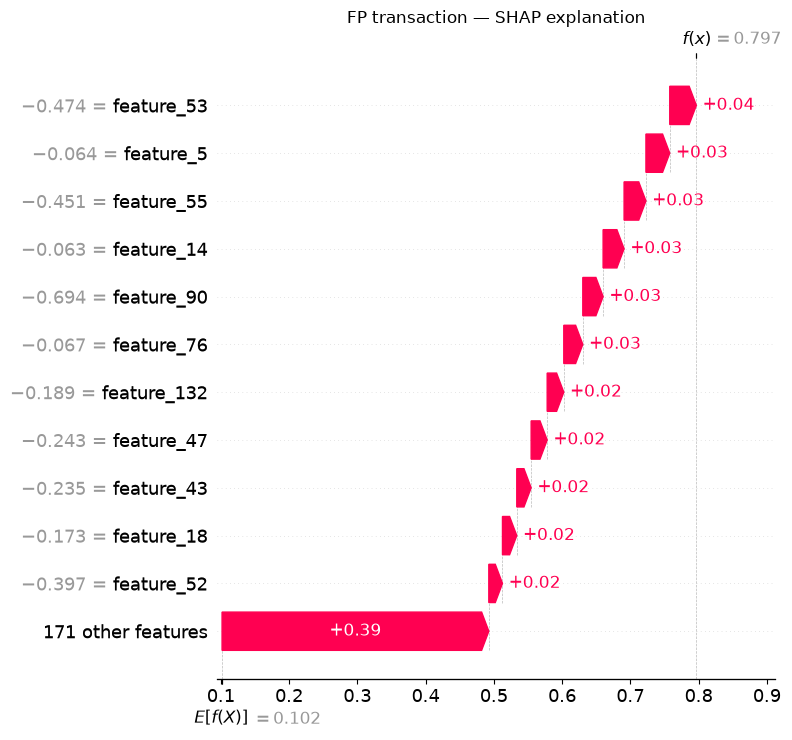

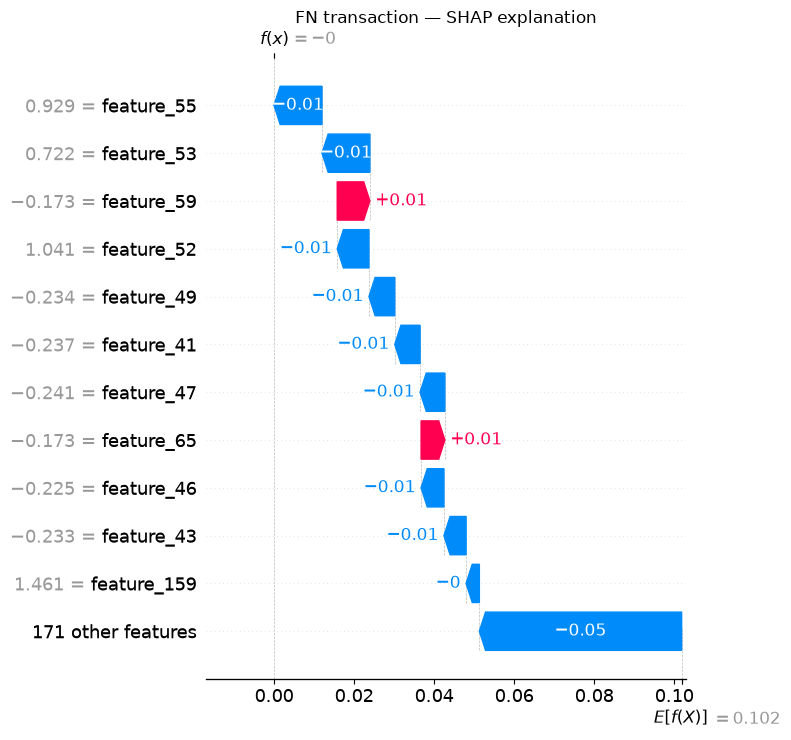

,case,txId,time_step,true_label,predicted_probability,top_positive_features,top_negative_features
0,TP,71989346,42,1,0.950000,"feature_55 (+0.069), feature_53 (+0.067), feature_5 (+0.037), feature_90 (+0.035), feature_76 (+0.034), feature_14 (+0.032), feature_52 (+0.030), feature_47 (+0.025), feature_43 (+0.023), feature_18 (+0.022)",None
1,TN,79428037,42,0,0.000000,"feature_59 (+0.008), feature_65 (+0.006)","feature_53 (-0.015), feature_55 (-0.013), feature_47 (-0.007), feature_49 (-0.006), feature_41 (-0.006), feature_43 (-0.005), feature_52 (-0.004), feature_46 (-0.004)"
2,FP,156049909,45,0,0.796667,"feature_53 (+0.039), feature_5 (+0.035), feature_55 (+0.032), feature_14 (+0.031), feature_90 (+0.030), feature_76 (+0.028), feature_132 (+0.024), feature_47 (+0.023), feature_43 (+0.021), feature_18 (+0.021)",None
3,FN,73436880,42,1,0.000000,"feature_59 (+0.008), feature_65 (+0.006)","feature_55 (-0.012), feature_53 (-0.012), feature_52 (-0.008), feature_49 (-0.006), feature_41 (-0.006), feature_47 (-0.006), feature_46 (-0.006), feature_43 (-0.006)"


In [76]:
# ---- 12.5 Individual transaction explanations (TP / TN / FP / FN) -------------
# Outcome categories use the fixed 0.5 threshold for consistency with the ablation notebook.
# These are illustrative cases, not a statistically representative sample.
case_summary_rows = []
for case, original_pos in case_positions.items():
    local_pos = int(np.where(shap_positions == original_pos)[0][0])
    row_values = shap_values[local_pos]
    order = np.argsort(np.abs(row_values))[::-1][:10]
    tx_row = _shap_test.iloc[original_pos]
    case_summary_rows.append({
        "case": case,
        "txId": tx_row[TX_ID_COL],
        "time_step": int(tx_row[TIME_COL]),
        "true_label": int(y_shap_test[original_pos]),
        "predicted_probability": float(p_shap_test[original_pos]),
        "top_positive_features": ", ".join(f"{shap_cols[j]} ({row_values[j]:+.3f})" for j in order if row_values[j] > 0) or "None",
        "top_negative_features": ", ".join(f"{shap_cols[j]} ({row_values[j]:+.3f})" for j in order if row_values[j] < 0) or "None",
    })
    exp = shap.Explanation(
        values=row_values,
        base_values=float(shap_base_values[local_pos]),
        data=X_shap.iloc[local_pos].to_numpy(),
        feature_names=shap_cols
    )
    plt.figure(figsize=(9, 6))
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.title(f"{case} transaction — SHAP explanation")
    plt.tight_layout()
    plt.savefig(f"shap_case_{case.lower()}.png", dpi=200, bbox_inches="tight")
    plt.show()

case_shap_df = pd.DataFrame(case_summary_rows)
display(case_shap_df)

In [77]:
# ---- 12.6 Export interpretation tables and figures ---------------------------
feature_shap_df.to_csv("shap_feature_importance.csv", index=False)
group_shap_summary.to_csv("shap_group_attribution.csv", index=False)
case_shap_df.to_csv("shap_transaction_cases.csv", index=False)
print("Saved SHAP outputs:")
for filename in [
    "shap_global_summary.png", "shap_top_features.png", "shap_group_attribution.png",
    "shap_feature_importance.csv", "shap_group_attribution.csv", "shap_transaction_cases.csv",
    "shap_case_tp.png", "shap_case_tn.png", "shap_case_fp.png", "shap_case_fn.png"
]:
    if os.path.exists(filename):
        print(" -", filename)

Saved SHAP outputs:
 - shap_global_summary.png
 - shap_top_features.png
 - shap_group_attribution.png
 - shap_feature_importance.csv
 - shap_group_attribution.csv
 - shap_transaction_cases.csv
 - shap_case_tp.png
 - shap_case_tn.png
 - shap_case_fp.png
 - shap_case_fn.png


## Interpretation and reporting notes

1. Report the SHAP sample size, training-only background size, model (`T+N+G` RF), and fixed 0.5 threshold used to classify the illustrative cases.
2. The group summary is based on the **sum of signed feature SHAP values within each group per transaction**, followed by the mean absolute group contribution. The secondary sum of per-feature mean absolute SHAP values is a different aggregation and should not be conflated with it.
3. Correlated and dependent T/N/G features can share or redistribute attribution. Treat SHAP values as model explanations, not unique or causal importance.
4. Compare the broad SHAP pattern with the intervention results, but do not expect the numerical magnitudes or rankings to match: SHAP allocates prediction differences relative to a background distribution, while interventions measure changes under the selected replacement procedure.
5. Run the notebook from top to bottom in the intended dataset environment. This file preserves the original experiment cells and adds the SHAP section; the SHAP outputs are generated when that section is executed.

## Joint matched replacements and non-additivity (added; requires full upstream execution)

For each target block (T+N, T+G, N+G, T+N+G), this analysis finds up to `K_REF` donors in the same time step, nearest in the standardized complement blocks. The same donor row supplies every replaced block, preserving their observed within-donor coupling. Donors are real transactions, labels are not used, and the evaluation node itself is excluded. Outputs include signed and absolute probability changes, coverage, donor distances, realism and OOD diagnostics. No global-mean replacement is used as the primary method.

Pairwise contrasts are `delta_joint - delta_single_a - delta_single_b` using the same target node baseline; they are descriptive sensitivity contrasts. The single-block and joint donor pools differ in matching dimensions, so contrasts can reflect donor selection as well as model non-additivity. T/N/G are coupled representations; these are not causal interaction effects.

**Execution status:** this section is unexecuted in the supplied notebook and requires the Elliptic source CSVs plus all preceding cells.


In [78]:
# Joint replacement implementation; uses the existing `U`, `u_time`, `eval_upos`,
# `t_eval`, `n_eval`, `GROUPS`, `MATCH_COLS`, `ms`, `ZU`, `UV`, `X_eval`,
# `base_risk`, `predict_risk`, `realism`, `g_violations`, and `EVAL_TIMES`.
from itertools import combinations
JOINT_BLOCKS = {"T+N": ["T", "N"], "T+G": ["T", "G"],
                 "N+G": ["N", "G"], "T+N+G": ["T", "N", "G"]}

def find_joint_matches(target_groups, k=K_REF, extra=30):
    target_groups = tuple(target_groups)
    held = [g for g in ["T", "N", "G"] if g not in target_groups]
    # Match only on the held blocks. With no held block, use same-time random donors.
    Zm = np.hstack([ZU[g] for g in held]) if held else None
    refs = np.full((n_eval, k), -1, dtype=int)
    distances = np.full((n_eval, k), np.nan)
    for t in EVAL_TIMES:
        pool = np.where(u_time == t)[0]
        rows = np.where(t_eval == t)[0]
        if not len(rows) or not len(pool):
            continue
        if held:
            nn = NearestNeighbors(n_neighbors=min(k + extra, len(pool))).fit(Zm[pool])
            d, ix = nn.kneighbors(Zm[eval_upos[rows]])
            candidates, dists = pool[ix], d
        else:
            rng = np.random.default_rng(SEED + int(t))
            candidates = np.tile(pool, (len(rows), 1))
            dists = np.zeros(candidates.shape)
            for q in range(len(rows)):
                rng.shuffle(candidates[q])
        for rr, q, cc, dd in zip(rows, eval_upos[rows], candidates, dists):
            ok = cc != q
            # Avoid copying the exact same joint block, where possible.
            same = np.ones(len(cc), dtype=bool)
            for g in target_groups:
                same &= np.all(UV[g][cc] == UV[g][q], axis=1)
            ok &= ~same
            cc, dd = cc[ok][:k], dd[ok][:k]
            refs[rr, :len(cc)] = cc
            distances[rr, :len(cc)] = dd
    return refs, distances

def score_joint_replacement(name, groups):
    refs, dist = find_joint_matches(groups)
    owner, slot = np.nonzero(refs >= 0)
    X = X_eval.iloc[owner].reset_index(drop=True).copy()
    for g in groups:
        X[GROUPS[g]] = UV[g][refs[owner, slot]]
    X.attrs["donor_upos"] = refs[owner, slot]
    prob = predict_risk(X)
    p_node = pd.Series(prob).groupby(owner).mean().reindex(range(n_eval)).to_numpy()
    coverage = np.isfinite(p_node)
    delta = p_node - base_risk
    abs_delta = np.abs(delta[coverage])
    rr, ood = realism(X, owner)
    return {"block": name, "groups": groups, "delta": delta,
            "row": {"block": name, "n_eval": n_eval, "coverage": coverage.mean(),
                    "n_donors": int((refs >= 0).sum()), "mean_signed_delta": float(np.nanmean(delta)),
                    "mean_abs_delta": float(abs_delta.mean()), "median_abs_delta": float(np.median(abs_delta)),
                    "donor_distance_median": float(np.nanmedian(dist)),
                    "realism_ratio": rr, "ood_rate": ood,
                    "g_rule_violation_rate": float(g_violations(X).mean())}}

joint_runs = {name: score_joint_replacement(name, groups) for name, groups in JOINT_BLOCKS.items()}
joint_results_df = pd.DataFrame([v["row"] for v in joint_runs.values()])
display(joint_results_df)

# Descriptive pairwise signed contrast; also report absolute-change contrast separately.
nonadd_rows = []
for a, b in combinations(["T", "N", "G"], 2):
    joint = joint_runs[a + "+" + b]["delta"]
    da, db = DELTAS[("C-matched", a, None)], DELTAS[("C-matched", b, None)]
    contrast = joint - da - db
    abs_contrast = np.abs(joint) - np.abs(da) - np.abs(db)
    valid = np.isfinite(contrast) & np.isfinite(da) & np.isfinite(db)
    nonadd_rows.append({"pair": f"{a}+{b}", "n": int(valid.sum()),
                        "mean_signed_nonadditivity": float(contrast[valid].mean()),
                        "mean_abs_signed_contrast": float(np.abs(contrast[valid]).mean()),
                        "mean_absolute_change_contrast": float(abs_contrast[valid].mean()),
                        "mean_abs_change_contrast": float(np.abs(abs_contrast[valid]).mean())})
nonadditivity_df = pd.DataFrame(nonadd_rows)
display(nonadditivity_df)

# Save the new computed results when this section is run.
joint_results_df.to_csv("joint_replacement_results.csv", index=False)
nonadditivity_df.to_csv("nonadditivity_results.csv", index=False)


,block,n_eval,coverage,n_donors,mean_signed_delta,mean_abs_delta,median_abs_delta,donor_distance_median,realism_ratio,ood_rate,g_rule_violation_rate
0,T+N,8841,1.0,44205,0.040136,0.076025,0.044667,0.000000,0.826556,0.028667,0.0
1,T+G,8841,1.0,44205,0.030147,0.047191,0.025333,0.654730,0.950115,0.038000,0.0
2,N+G,8841,1.0,44205,-0.000275,0.013334,0.004667,0.473956,1.043641,0.048000,0.0
3,T+N+G,8841,1.0,44205,0.059274,0.110886,0.081333,0.000000,0.816418,0.036667,0.0


,pair,n,mean_signed_nonadditivity,mean_abs_signed_contrast,mean_absolute_change_contrast,mean_abs_change_contrast
0,T+N,8841,0.009788,0.064798,0.013332,0.059961
1,T+G,8841,-0.000326,0.031232,-0.006323,0.029631
2,N+G,8841,-0.000052,0.008267,-0.002491,0.007775


## Executed joint replacement and SHAP results

All four joint replacements covered 8,841/8,841 test nodes with 5 donors each (44,205 donor assignments per block). Donors were drawn from the target node’s timestep, excluded the node itself, and were filtered to differ on the full target block. These conditions make the donor validity rate 100% by construction among assigned donors; this is a constraint check, not a claim that a synthetic target-plus-donor combination is fully realistic. The realism ratio and OOD rate are separately reported. When no feature groups remain to match on (T+N+G), same-time donors are randomly selected; its donor-distance entry is not a matching-quality measure.

Observed mean absolute risk changes: T+N 0.0760, T+G 0.0472, N+G 0.0133, T+N+G 0.1109. The mean signed non-additivity contrasts were T+N +0.0098, T+G −0.0003, and N+G −0.0001. These summaries describe model sensitivity and donor-dependent comparisons, not causal interactions.

SHAP explained 503 test transactions with a 100-row training-only background. Grouped mean absolute attribution was T 0.2019, N 0.0449, G 0.0019; the mean additivity residual was 0.000151. All four TP/TN/FP/FN case plots were saved. SHAP describes this fitted RF’s predictions; it does not establish causes of fraud.


## GraphSAGE Interpretability Using GNNExplainer

The consolidated RF notebook did not include GraphSAGE. The separate comparison notebook defined a two-layer, 64-hidden-unit PyTorch `MeanGraphSAGE` using local features T (`feature_1`–`feature_93`) and time-cut, symmetrized transaction edges, but did not save its weights. The first explanation run therefore retrained the same architecture and protocol and saved `graphsage_t_explainer_checkpoint.pt`; subsequent runs reuse that checkpoint. The source RF/GraphSAGE comparison metrics remain unchanged.

PyTorch 2.11 is available, but PyTorch Geometric is not. This section implements the GNNExplainer mask objective directly in PyTorch: learned soft feature and edge masks preserve a target prediction while sparsity and entropy regularizers favor compact explanations. It is an adapted mask optimizer for this custom architecture, not output from the PyG API. Four reproducibly sampled TP/TN/FP/FN examples are explained with two mask initializations each.

Each explanation uses its target’s own temporal snapshot and a two-hop computation graph. Future edges are excluded, and local unmasked predictions are checked against full-snapshot predictions. Masks explain T and graph connectivity, not explicit N or G feature groups.


In [79]:
# Reproduce the source comparison notebook's GraphSAGE-T architecture and temporal protocol.
import random as sage_random, torch, torch.nn as torch_nn, torch.nn.functional as torch_F
from sklearn.metrics import roc_auc_score as sage_auc, average_precision_score as sage_ap, f1_score as sage_f1
SAGE_SEED=42; sage_random.seed(SAGE_SEED); np.random.seed(SAGE_SEED); torch.manual_seed(SAGE_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SAGE_SEED)
SAGE_DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:",torch.__version__,"device:",SAGE_DEVICE,"PyG:",False)
SAGE_T_COLS=[f"feature_{i}" for i in range(1,94)]
sage_tx_ids=features[TX_ID_COL].astype(str).to_numpy(); sage_time_np=features[TIME_COL].to_numpy(dtype=np.int64)
sage_label_map=classes.set_index(TX_ID_COL)[LABEL_COL].astype(str).map({"1":1.0,"2":0.0})
sage_y_np=pd.Series(sage_tx_ids).map(sage_label_map).to_numpy(dtype=np.float32); sage_labeled=np.isfinite(sage_y_np)
sage_X=torch.tensor(features[SAGE_T_COLS].to_numpy(dtype=np.float32),dtype=torch.float32,device=SAGE_DEVICE)
sage_y=torch.tensor(np.nan_to_num(sage_y_np,nan=0.0),dtype=torch.float32,device=SAGE_DEVICE)
sage_edge_src=edges_temporal["source_idx"].to_numpy(dtype=np.int64); sage_edge_dst=edges_temporal["target_idx"].to_numpy(dtype=np.int64)
sage_edge_time=edges_temporal["edge_time"].to_numpy(dtype=np.int64)
sage_nodes_by_time={int(t):np.flatnonzero(sage_time_np==int(t)) for t in np.unique(sage_time_np)}
sage_label_nodes={int(t):np.flatnonzero((sage_time_np==int(t))&sage_labeled) for t in np.unique(sage_time_np)}
sage_snapshots={}
def sage_snapshot(t):
    t=int(t)
    if t not in sage_snapshots:
        present=np.flatnonzero(sage_time_np<=t); keep=sage_edge_time<=t
        src=np.searchsorted(present,sage_edge_src[keep]); dst=np.searchsorted(present,sage_edge_dst[keep])
        ei_np=np.vstack((np.r_[src,dst],np.r_[dst,src])).astype(np.int64)
        assert np.all(sage_time_np[sage_edge_src[keep]]<=t) and np.all(sage_time_np[sage_edge_dst[keep]]<=t)
        sage_snapshots[t]=(present,torch.tensor(present,dtype=torch.long,device=SAGE_DEVICE),torch.tensor(ei_np,dtype=torch.long,device=SAGE_DEVICE),ei_np)
    return sage_snapshots[t]
class ExplainableMeanGraphSAGE(torch_nn.Module):
    def __init__(self,in_dim,hidden_dim=64,dropout=.25):
        super().__init__(); self.self1=torch_nn.Linear(in_dim,hidden_dim); self.neigh1=torch_nn.Linear(in_dim,hidden_dim,bias=False)
        self.self2=torch_nn.Linear(hidden_dim,hidden_dim); self.neigh2=torch_nn.Linear(hidden_dim,hidden_dim,bias=False)
        self.classifier=torch_nn.Linear(hidden_dim,1); self.dropout=dropout
    @staticmethod
    def aggregate(h,edge_index,weight=None):
        src,dst=edge_index; agg=torch.zeros_like(h); deg=torch.zeros((h.shape[0],1),dtype=h.dtype,device=h.device)
        if src.numel():
            w=torch.ones((src.numel(),1),dtype=h.dtype,device=h.device) if weight is None else weight.reshape(-1,1)
            agg.index_add_(0,dst,h[src]*w); deg.index_add_(0,dst,w)
        return agg/deg.clamp_min(1.)
    def forward(self,x,edge_index,edge_weight=None):
        h=torch_F.relu(self.self1(x)+self.neigh1(self.aggregate(x,edge_index,edge_weight)))
        h=torch_F.dropout(h,p=self.dropout,training=self.training)
        h=torch_F.relu(self.self2(h)+self.neigh2(self.aggregate(h,edge_index,edge_weight)))
        h=torch_F.dropout(h,p=self.dropout,training=self.training)
        return self.classifier(h).squeeze(-1)

sage_train=np.isin(sage_time_np,train_times)&sage_labeled
sage_pos=int(sage_y_np[sage_train].sum()); sage_neg=int(sage_train.sum()-sage_pos)
sage_pos_weight=torch.tensor([sage_neg/max(sage_pos,1)],dtype=torch.float32,device=SAGE_DEVICE)
SAGE_EPOCHS=12; SAGE_PATIENCE=3; SAGE_HIDDEN=64; SAGE_LR=1e-3; SAGE_DECAY=1e-5
sage_model=ExplainableMeanGraphSAGE(93,SAGE_HIDDEN,.25).to(SAGE_DEVICE)
sage_optimizer=torch.optim.Adam(sage_model.parameters(),lr=SAGE_LR,weight_decay=SAGE_DECAY)
sage_loss_fn=torch_nn.BCEWithLogitsLoss(pos_weight=sage_pos_weight)
def sage_predict_times(model,times,cache=False):
    model.eval(); ids=[]; probs=[]; zcache={}
    with torch.no_grad():
        for t in times:
            nodes=sage_label_nodes[int(t)]
            if not len(nodes): continue
            present,pt,ei,_=sage_snapshot(t); loc=np.searchsorted(present,nodes); z=model(sage_X[pt],ei)
            if cache: zcache[int(t)]=z.detach().cpu()
            probs.append(z[torch.as_tensor(loc,dtype=torch.long,device=SAGE_DEVICE)].sigmoid().cpu().numpy()); ids.append(nodes)
    return np.concatenate(ids),np.concatenate(probs),zcache
SAGE_CHECKPOINT=Path("graphsage_t_explainer_checkpoint.pt")
if SAGE_CHECKPOINT.exists():
    sage_ckpt=torch.load(SAGE_CHECKPOINT,map_location=SAGE_DEVICE,weights_only=True)
    if sage_ckpt.get("features")!=SAGE_T_COLS or sage_ckpt.get("hidden_dim")!=SAGE_HIDDEN:
        raise ValueError("Saved GraphSAGE checkpoint architecture/features do not match this section.")
    sage_model.load_state_dict(sage_ckpt["state_dict"]); sage_model.to(SAGE_DEVICE); sage_model.eval()
    sage_best_epoch=int(sage_ckpt["best_epoch"])
    sage_history=pd.read_csv("graphsage_explainer_training_history.csv").to_dict("records") if Path("graphsage_explainer_training_history.csv").exists() else []
    print("Reusing saved GraphSAGE checkpoint; no retraining.")
else:
    sage_best_auc=-np.inf; sage_best_state=None; sage_best_epoch=0; sage_wait=0; sage_history=[]
    for epoch in range(1,SAGE_EPOCHS+1):
        sage_model.train(); losses=[]
        for t in train_times:
            nodes=sage_label_nodes[int(t)]
            if not len(nodes): continue
            present,pt,ei,_=sage_snapshot(t); loc=np.searchsorted(present,nodes)
            z=sage_model(sage_X[pt],ei); ids_t=torch.as_tensor(nodes,dtype=torch.long,device=SAGE_DEVICE)
            loss=sage_loss_fn(z[torch.as_tensor(loc,dtype=torch.long,device=SAGE_DEVICE)],sage_y[ids_t])
            sage_optimizer.zero_grad(set_to_none=True); loss.backward(); torch_nn.utils.clip_grad_norm_(sage_model.parameters(),2.0); sage_optimizer.step(); losses.append(float(loss.detach().cpu()))
        vi,vp,_=sage_predict_times(sage_model,val_times); va=sage_auc(sage_y_np[vi].astype(int),vp); vap=sage_ap(sage_y_np[vi].astype(int),vp)
        sage_history.append({"epoch":epoch,"mean_time_step_loss":float(np.mean(losses)),"validation_auroc":va,"validation_auprc":vap})
        print(f"Epoch {epoch:02d} | loss={np.mean(losses):.4f} | val AUROC={va:.4f} | val AUPRC={vap:.4f}")
        if va>sage_best_auc+1e-5:
            sage_best_auc=va; sage_best_epoch=epoch; sage_best_state={k:v.detach().cpu().clone() for k,v in sage_model.state_dict().items()}; sage_wait=0
        else:
            sage_wait+=1
            if sage_wait>=SAGE_PATIENCE: print("Early stopping after",SAGE_PATIENCE,"validation checks."); break
    if sage_best_state is None: raise RuntimeError("No validation-selected GraphSAGE state.")
    sage_model.load_state_dict(sage_best_state); sage_model.to(SAGE_DEVICE); sage_model.eval()
    if sage_best_state is None: raise RuntimeError("No validation-selected GraphSAGE state.")
    sage_model.load_state_dict(sage_best_state); sage_model.to(SAGE_DEVICE); sage_model.eval()
sage_val_idx,sage_val_prob,_=sage_predict_times(sage_model,val_times); sage_test_idx,sage_test_prob,_=sage_predict_times(sage_model,test_times)
sage_grid=np.linspace(.05,.95,91); sage_val_y=sage_y_np[sage_val_idx].astype(int)
sage_threshold=float(sage_grid[np.argmax([sage_f1(sage_val_y,(sage_val_prob>=q).astype(int),zero_division=0) for q in sage_grid])])
sage_test_y=sage_y_np[sage_test_idx].astype(int); sage_test_pred=(sage_test_prob>=sage_threshold).astype(int)
sage_model_metrics=pd.DataFrame([{"model":"GraphSAGE-T local reproduction","best_epoch":sage_best_epoch,"validation_threshold":sage_threshold,
 "test_auroc":sage_auc(sage_test_y,sage_test_prob),"test_auprc":sage_ap(sage_test_y,sage_test_prob),"test_f1":sage_f1(sage_test_y,sage_test_pred,zero_division=0),"test_nodes":len(sage_test_idx),"device":str(SAGE_DEVICE)}])
sage_model_metrics.to_csv("graphsage_explainer_model_metrics.csv",index=False); pd.DataFrame(sage_history).to_csv("graphsage_explainer_training_history.csv",index=False)
torch.save({"state_dict":sage_model.state_dict(),"best_epoch":sage_best_epoch,"seed":SAGE_SEED,"features":SAGE_T_COLS,"hidden_dim":64,"dropout":.25,"threshold":sage_threshold},"graphsage_t_explainer_checkpoint.pt")
print("Validation-selected epoch:",sage_best_epoch,"threshold:",sage_threshold); display(sage_model_metrics)


PyTorch: 2.11.0+cu128 device: cuda PyG: False


Reusing saved GraphSAGE checkpoint; no retraining.


Validation-selected epoch: 12 threshold: 0.9299999999999999


,model,best_epoch,validation_threshold,test_auroc,test_auprc,test_f1,test_nodes,device
0,GraphSAGE-T local reproduction,12,0.93,0.805816,0.471637,0.481894,8841,cuda


In [80]:
# One reproducibly random example per available TP/TN/FP/FN category.
SAGE_EXPLAIN_SEED=42; sage_rng=np.random.default_rng(SAGE_EXPLAIN_SEED)
sage_masks={"TP":(sage_test_y==1)&(sage_test_pred==1),"TN":(sage_test_y==0)&(sage_test_pred==0),"FP":(sage_test_y==0)&(sage_test_pred==1),"FN":(sage_test_y==1)&(sage_test_pred==0)}
sage_case_rows=[]
for case,mask in sage_masks.items():
    cand=np.flatnonzero(mask)
    if len(cand):
        j=int(sage_rng.choice(cand)); g=int(sage_test_idx[j])
        sage_case_rows.append({"case":case,"global_row_index":g,"txId":sage_tx_ids[g],"time_step":int(sage_time_np[g]),"true_label":int(sage_test_y[j]),"predicted_label":int(sage_test_pred[j]),"probability":float(sage_test_prob[j])})
sage_case_df=pd.DataFrame(sage_case_rows); sage_case_df.to_csv("graphsage_gnnexplainer_cases.csv",index=False)
print("Selected cases:",sage_case_df.case.tolist()); display(sage_case_df)


Selected cases: ['TP', 'TN', 'FP', 'FN']


,case,global_row_index,txId,time_step,true_label,predicted_label,probability
0,TP,167994,71989369,42,1,1,0.999745
1,TN,192191,195436746,46,0,0,0.210141
2,FP,185548,173754103,45,0,1,0.953262
3,FN,182355,105985052,44,1,0,0.668602


In [81]:
# Local two-hop mask optimization. The unmasked local prediction must match the temporal full-snapshot result.
SAGE_MASK_SEEDS=[42,7]; SAGE_MASK_EPOCHS=100; SAGE_MASK_LR=.05; SAGE_EDGE_SIZE=.005; SAGE_FEATURE_SIZE=.05; SAGE_ENTROPY=.01
def sage_local_graph(target,t):
    present,_,_,ei_np=sage_snapshot(t); tl=int(np.searchsorted(present,target)); src,dst=ei_np; adj={}
    for a,b in zip(src.tolist(),dst.tolist()): adj.setdefault(a,set()).add(b)
    one=set(adj.get(tl,set())); two=set(one)
    for v in one: two.update(adj.get(v,set()))
    nodes=np.array(sorted(two|{tl}),dtype=np.int64); loc={int(v):i for i,v in enumerate(nodes)}
    keep=np.isin(src,nodes)&np.isin(dst,nodes); local_e=np.vstack(([loc[int(v)] for v in src[keep]],[loc[int(v)] for v in dst[keep]])).astype(np.int64)
    x=sage_X[torch.as_tensor(present[nodes],dtype=torch.long,device=SAGE_DEVICE)]
    return present[nodes],x,torch.as_tensor(local_e,dtype=torch.long,device=SAGE_DEVICE),loc[tl],local_e

def sage_explain_case(row):
    case=row.case; target=int(row.global_row_index); t=int(row.time_step)
    local_global,x,ei,target_local,ei_np=sage_local_graph(target,t)
    with torch.no_grad():
        present,pt,full_ei,_=sage_snapshot(t); full_loc=int(np.searchsorted(present,target))
        p_full=float(sage_model(sage_X[pt],full_ei)[full_loc].sigmoid().cpu())
        p_local=float(sage_model(x,ei)[target_local].sigmoid().cpu())
    local_gap=abs(p_full-p_local)
    if local_gap>1e-4: raise AssertionError(f"2-hop local prediction differs from full snapshot by {local_gap}")
    orig_flags=[p.requires_grad for p in sage_model.parameters()]; runs=[]
    for seed in SAGE_MASK_SEEDS:
        torch.manual_seed(seed+target)
        for p in sage_model.parameters(): p.requires_grad_(False)
        fl=torch.nn.Parameter(torch.randn(x.shape[1],device=SAGE_DEVICE)*.1); el=torch.nn.Parameter(torch.randn(ei.shape[1],device=SAGE_DEVICE)*.1)
        opt=torch.optim.Adam([fl,el],lr=SAGE_MASK_LR)
        for _ in range(SAGE_MASK_EPOCHS):
            fm=fl.sigmoid(); em=el.sigmoid(); prob=sage_model(x*fm,ei,em)[target_local].sigmoid().clamp(1e-6,1-1e-6)
            ref=torch.tensor(p_full,dtype=torch.float32,device=SAGE_DEVICE)
            fidelity=torch_F.binary_cross_entropy(prob,ref)
            ef=-(fm*torch.log(fm+1e-8)+(1-fm)*torch.log(1-fm+1e-8)).mean()
            ee=-(em*torch.log(em+1e-8)+(1-em)*torch.log(1-em+1e-8)).mean()
            loss=fidelity+SAGE_FEATURE_SIZE*fm.sum()+SAGE_EDGE_SIZE*em.sum()+SAGE_ENTROPY*(ef+ee)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        with torch.no_grad():
            fm=fl.sigmoid().cpu().numpy(); em=el.sigmoid().cpu().numpy()
            p_mask=float(sage_model(x*fl.sigmoid(),ei,el.sigmoid())[target_local].sigmoid().cpu())
        directed={}
        for (a,b),score in zip(ei_np.T,em):
            ga=int(local_global[int(a)]); gb=int(local_global[int(b)]); k=tuple(sorted((ga,gb)))
            directed.setdefault(k,[]).append(float(score))
        edge_scores={k:float(np.mean(v)) for k,v in directed.items()}
        runs.append({"seed":seed,"features":fm,"edges":edge_scores,"masked_prob":p_mask,"fidelity_gap":abs(p_mask-p_full),"class_preserved":int((p_mask>=.5)==(p_full>=.5))})
    for p,flag in zip(sage_model.parameters(),orig_flags): p.requires_grad_(flag)
    return {"case":case,"target":target,"time":t,"local_global":local_global,"local_nodes":len(local_global),"directed_edges":len(ei_np.T),"prob":p_full,"local_gap":local_gap,"runs":runs}
sage_explanations=[sage_explain_case(row) for row in sage_case_df.itertuples(index=False)]
print("Completed explanations:",len(sage_explanations))


Completed explanations: 4


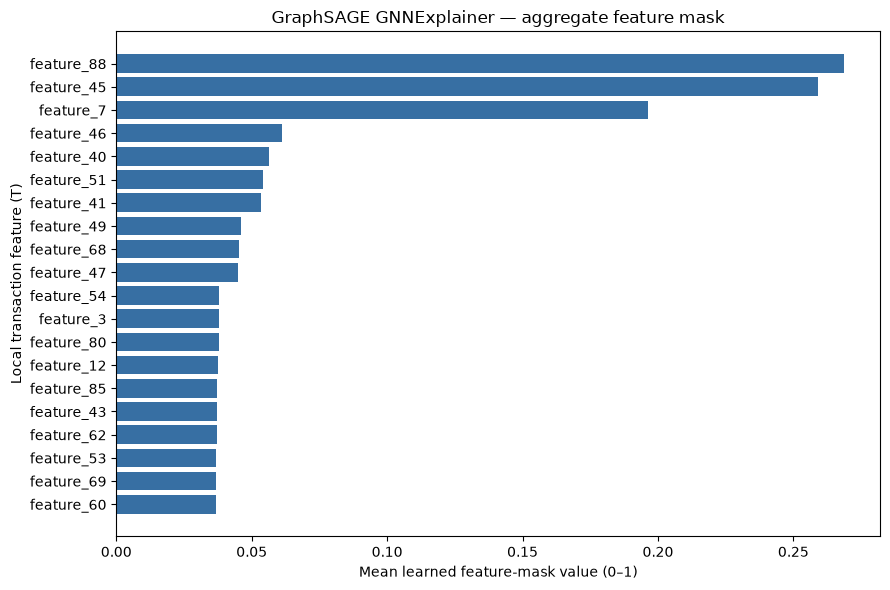

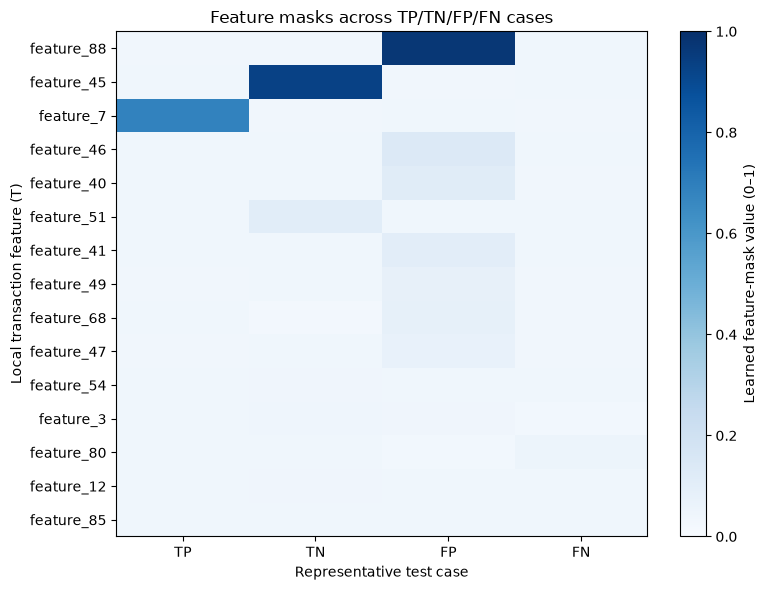

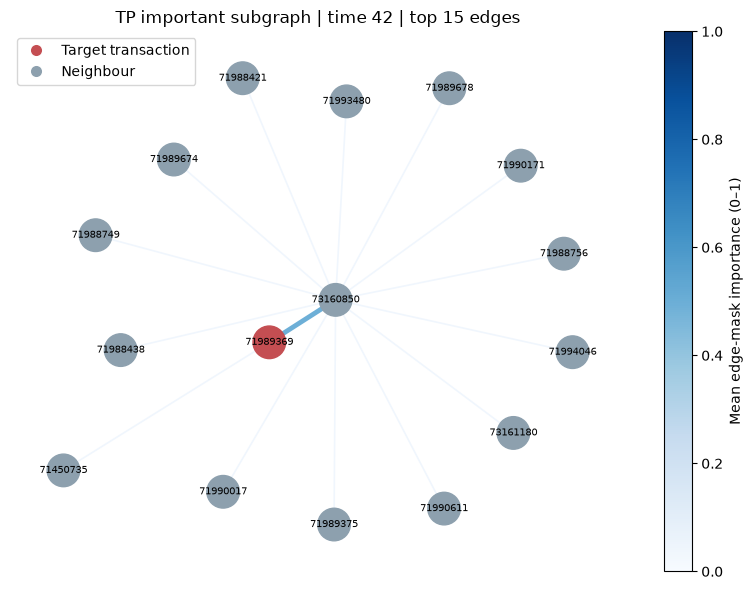

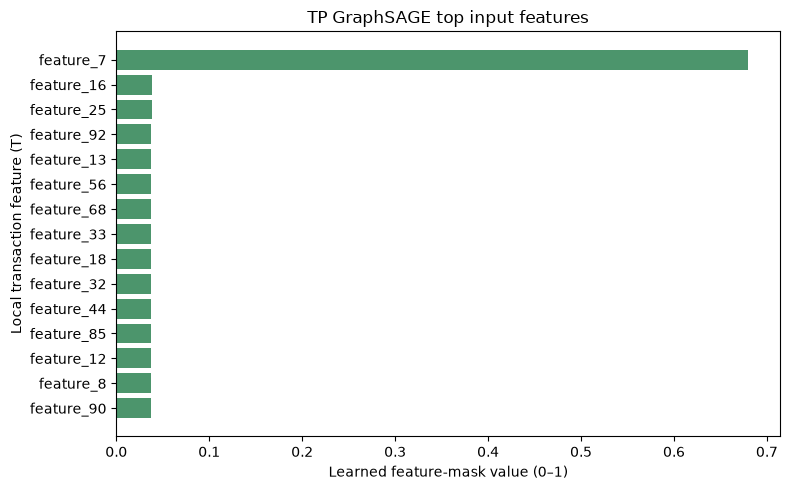

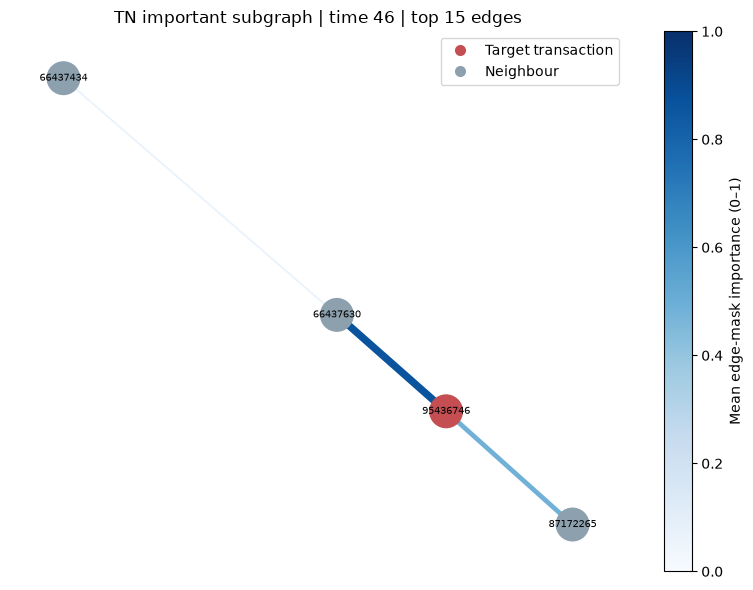

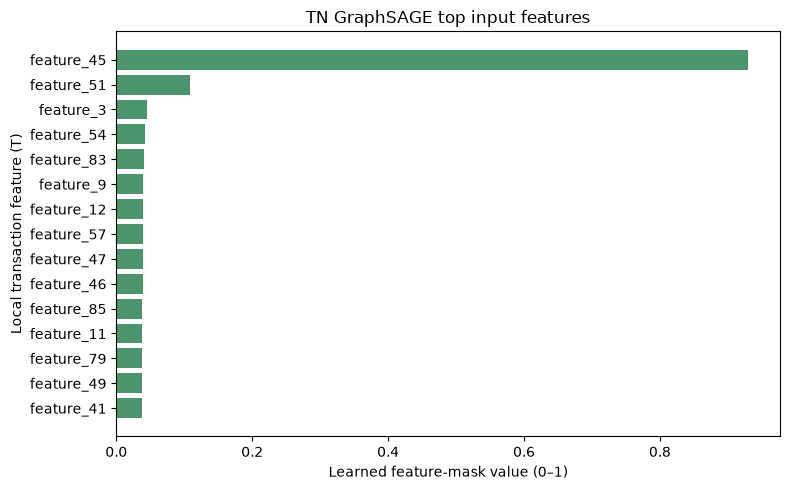

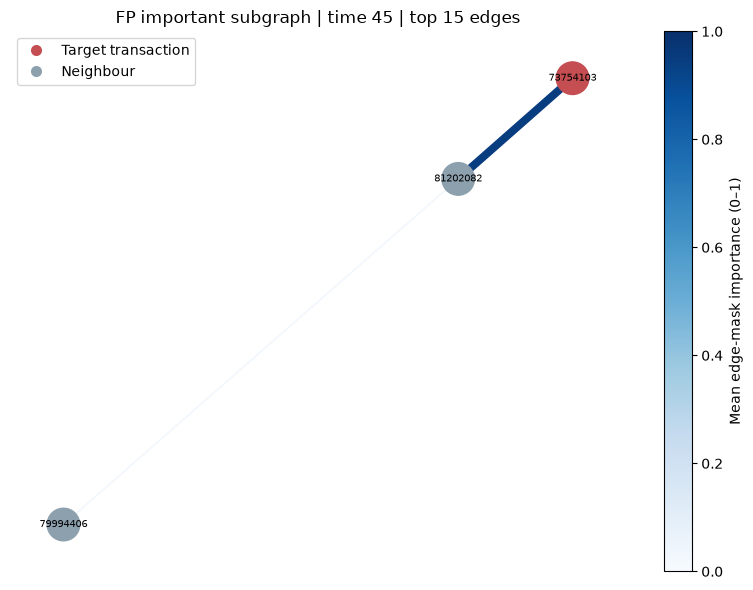

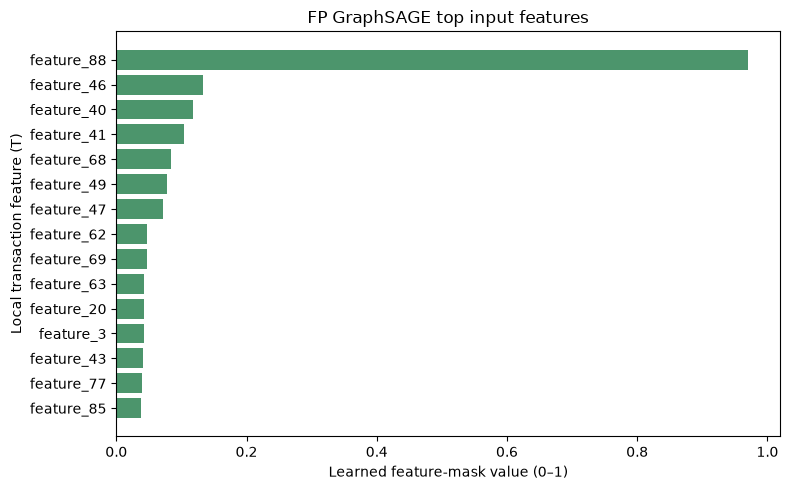

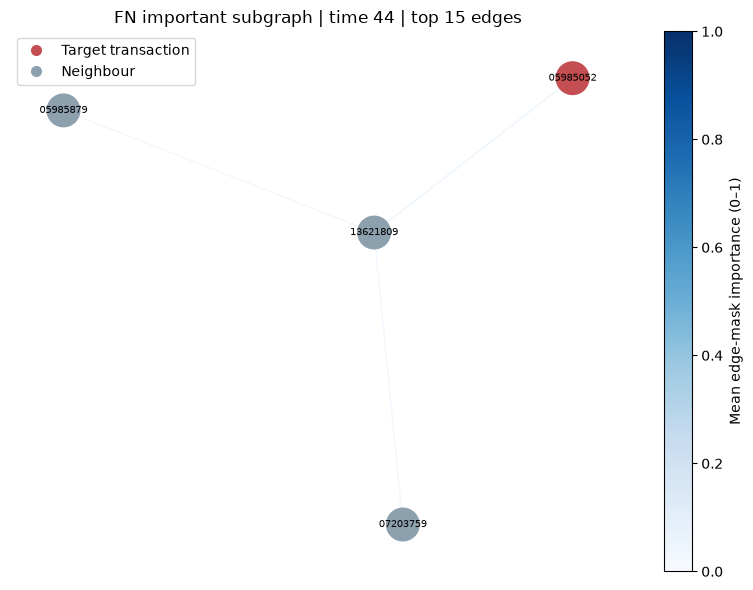

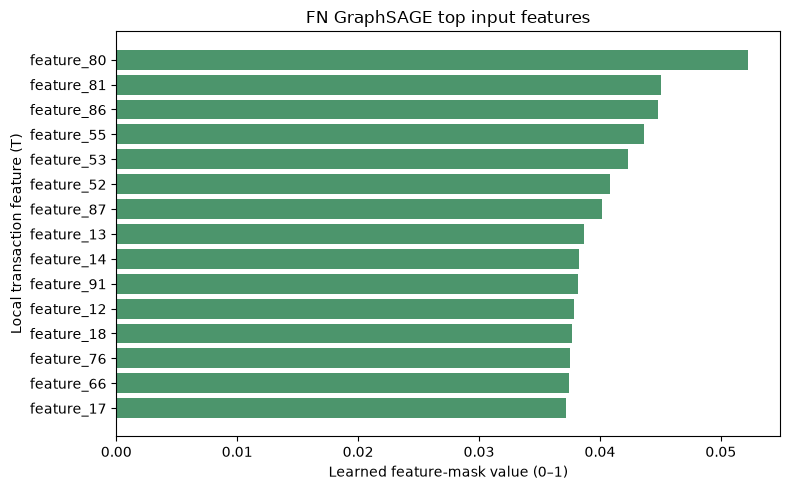

GNNExplainer case summaries:


,case,txId,time_step,true_label,predicted_label,probability,local_nodes,local_directed_edges,full_local_probability_gap,feature_top10_jaccard,edge_top20_jaccard
0,TP,71989369,42,1,1,0.999745,52,102,0.0,0.111111,0.290323
1,TN,195436746,46,0,0,0.210141,4,6,0.0,0.428571,1.000000
2,FP,173754103,45,0,1,0.953262,3,4,0.0,0.818182,1.000000
3,FN,105985052,44,1,0,0.668602,4,6,0.0,0.250000,1.000000


Seed stability:


,case,feature_top10_jaccard,edge_top20_jaccard,all_seed_predictions_preserved,max_masked_probability_gap
0,TP,0.111111,0.290323,True,0.008579
1,TN,0.428571,1.000000,True,0.061716
2,FP,0.818182,1.000000,True,0.108231
3,FN,0.250000,1.000000,True,0.104276


In [82]:
# Export per-case feature/edge masks, aggregate importance and two-seed stability.
import networkx as sage_nx
from matplotlib.lines import Line2D
Path("figures").mkdir(exist_ok=True)
feature_rows=[]; edge_rows=[]; stability_rows=[]; summary_rows=[]; case_vectors={}
for ex in sage_explanations:
    runs=ex["runs"]; fmat=np.vstack([r["features"] for r in runs]); fm=fmat.mean(0)
    eu=set().union(*(r["edges"].keys() for r in runs)); em={k:float(np.mean([r["edges"].get(k,0.) for r in runs])) for k in eu}
    fs=[set(np.argsort(r["features"])[-10:]) for r in runs]; es=[set(sorted(r["edges"],key=r["edges"].get,reverse=True)[:20]) for r in runs]
    fj=len(fs[0]&fs[1])/max(1,len(fs[0]|fs[1])); ej=len(es[0]&es[1])/max(1,len(es[0]|es[1]))
    stability_rows.append({"case":ex["case"],"feature_top10_jaccard":fj,"edge_top20_jaccard":ej,"all_seed_predictions_preserved":all(r["class_preserved"] for r in runs),"max_masked_probability_gap":max(r["fidelity_gap"] for r in runs)})
    t=ex["target"]; row=sage_case_df[sage_case_df.case==ex["case"]].iloc[0]
    summary_rows.append({"case":ex["case"],"txId":sage_tx_ids[t],"time_step":ex["time"],"true_label":int(row.true_label),"predicted_label":int(row.predicted_label),"probability":float(row.probability),"local_nodes":ex["local_nodes"],"local_directed_edges":ex["directed_edges"],"full_local_probability_gap":ex["local_gap"],"feature_top10_jaccard":fj,"edge_top20_jaccard":ej})
    case_vectors[ex["case"]]=fm
    for j,v in enumerate(fm): feature_rows.append({"case":ex["case"],"txId":sage_tx_ids[t],"time_step":ex["time"],"feature":SAGE_T_COLS[j],"importance_mask":float(v)})
    for (a,b),v in sorted(em.items(),key=lambda kv:kv[1],reverse=True)[:50]:
        available=int(max(sage_time_np[a],sage_time_np[b])); assert available<=ex["time"]
        edge_rows.append({"case":ex["case"],"time_step":ex["time"],"source_txId":sage_tx_ids[a],"target_txId":sage_tx_ids[b],"edge_available_time":available,"importance_mask":v,"message_passing":"undirected"})
features_out=pd.DataFrame(feature_rows); edges_out=pd.DataFrame(edge_rows); stability_out=pd.DataFrame(stability_rows); cases_out=pd.DataFrame(summary_rows)
aggregate=(features_out.groupby("feature",as_index=False).agg(mean_importance_mask=("importance_mask","mean"),sd_across_cases=("importance_mask","std")).sort_values("mean_importance_mask",ascending=False))
features_out.to_csv("graphsage_gnnexplainer_feature_importance.csv",index=False); edges_out.to_csv("graphsage_gnnexplainer_edge_importance.csv",index=False)
stability_out.to_csv("graphsage_gnnexplainer_stability.csv",index=False); cases_out.to_csv("graphsage_gnnexplainer_case_summary.csv",index=False); aggregate.to_csv("graphsage_gnnexplainer_aggregate_features.csv",index=False)
# Aggregate feature plot.
plt.figure(figsize=(9,6)); top=aggregate.head(20).sort_values("mean_importance_mask"); plt.barh(top.feature,top.mean_importance_mask,color="#376fa3")
plt.xlabel("Mean learned feature-mask value (0–1)"); plt.ylabel("Local transaction feature (T)"); plt.title("GraphSAGE GNNExplainer — aggregate feature mask"); plt.tight_layout(); plt.savefig("figures/graphsage_gnnexplainer_aggregate_features.png",dpi=180); plt.show()
# Compare the four representative cases on the top aggregate features.
case_order=[c for c in ["TP","TN","FP","FN"] if c in case_vectors]; topnames=aggregate.head(15).feature.tolist()
heat=np.vstack([[case_vectors[c][SAGE_T_COLS.index(f)] for c in case_order] for f in topnames]); fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(heat,aspect="auto",cmap="Blues",vmin=0,vmax=1)
ax.set_yticks(range(len(topnames)),topnames); ax.set_xticks(range(len(case_order)),case_order); ax.set_xlabel("Representative test case"); ax.set_ylabel("Local transaction feature (T)"); ax.set_title("Feature masks across TP/TN/FP/FN cases")
fig.colorbar(im,ax=ax,label="Learned feature-mask value (0–1)"); fig.tight_layout(); fig.savefig("figures/graphsage_gnnexplainer_case_comparison.png",dpi=180); plt.show()
# Per-case subgraph and feature bar plots.
for ex in sage_explanations:
    case=ex["case"]; target=ex["target"]; runs=ex["runs"]
    eu=set().union(*(r["edges"].keys() for r in runs)); em={k:float(np.mean([r["edges"].get(k,0.) for r in runs])) for k in eu}; chosen=sorted(em,key=em.get,reverse=True)[:15]
    g=sage_nx.Graph(); g.add_node(target)
    for a,b in chosen: g.add_edge(a,b,weight=em[(a,b)])
    pos=sage_nx.spring_layout(g,seed=SAGE_EXPLAIN_SEED,weight="weight"); fig,ax=plt.subplots(figsize=(8,6))
    sage_nx.draw_networkx_nodes(g,pos,node_color=["#c44e52" if v==target else "#8da0ae" for v in g.nodes],node_size=550,ax=ax)
    sage_nx.draw_networkx_edges(g,pos,width=[1+5*g[a][b]["weight"] for a,b in g.edges],edge_color=[g[a][b]["weight"] for a,b in g.edges],edge_cmap=plt.cm.Blues,edge_vmin=0,edge_vmax=1,ax=ax)
    sm=plt.cm.ScalarMappable(cmap=plt.cm.Blues,norm=plt.Normalize(vmin=0,vmax=1)); fig.colorbar(sm,ax=ax,label="Mean edge-mask importance (0–1)")
    sage_nx.draw_networkx_labels(g,pos,{v:sage_tx_ids[v][-8:] for v in g.nodes},font_size=7,ax=ax)
    ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor='#c44e52',label='Target transaction',markersize=9),Line2D([0],[0],marker='o',color='w',markerfacecolor='#8da0ae',label='Neighbour',markersize=9)])
    ax.set_title(f"{case} important subgraph | time {ex['time']} | top 15 edges"); ax.axis('off'); fig.tight_layout(); fig.savefig(f"figures/graphsage_gnnexplainer_subgraph_{case.lower()}.png",dpi=180); plt.show()
    fm=np.mean(np.vstack([r["features"] for r in runs]),axis=0); ii=np.argsort(fm)[-15:]; ii=ii[np.argsort(fm[ii])]
    fig,ax=plt.subplots(figsize=(8,5)); ax.barh([SAGE_T_COLS[k] for k in ii],fm[ii],color="#4c956c"); ax.set_xlabel("Learned feature-mask value (0–1)"); ax.set_ylabel("Local transaction feature (T)")
    ax.set_title(f"{case} GraphSAGE top input features"); fig.tight_layout(); fig.savefig(f"figures/graphsage_gnnexplainer_features_{case.lower()}.png",dpi=180); plt.show()
print("GNNExplainer case summaries:"); display(cases_out); print("Seed stability:"); display(stability_out)


## Interpretation and comparison

GNNExplainer masks explain GraphSAGE reliance on T and graph connections. SHAP explains the T+N+G Random Forest; matched replacements measure score changes under RF feature-block replacements. They concern different models and inputs, so their scores are not directly comparable. Important edges and features are model-specific evidence, not causes of fraud. Stability across two mask initializations is reported by case.
